# MSCS 634 – Final Project (Deliverable 4)
# Advanced Data Mining for Data-Driven Insights and Predictive Modeling
### Customer Churn and Value Analysis – IBM Telco Customer Churn Dataset

**Course:** MSCS 634
**Authors:** Pranavi Balakulla, Sandeep Reddy Banda, Sowmya Cheruku, Vineela Reddy Karnatakam

---

This notebook **consolidates all code from the project** into one reproducible workflow (run it top to bottom with
*Run All*). Each part corresponds to one project deliverable:

| Part | Deliverable | Contents |
|---|---|---|
| **Part 1** | Deliverable 1 | Dataset selection, cleaning (missing values, duplicates, inconsistencies, noise) and exploratory data analysis |
| **Part 2** | Deliverable 2 | Regression: estimating customer lifetime revenue, feature engineering, 5 models, cross-validation |
| **Part 3** | Deliverable 3 | Classification of churn (with hyperparameter tuning), K-Means segmentation, association rule mining |
| **Part 4** | Deliverable 4 | **Ethical considerations:** privacy, fairness analysis by customer group, and dataset biases |
| **Part 5** | Deliverable 4 | Consolidated results, practical recommendations and future improvements |

**Files used:** `Telco-Customer-Churn.csv` (raw data) → Part 1 writes `telco_churn_cleaned.csv` → Parts 2–5 use it.
All figures are saved to `Images/` with a prefix showing the part (`p1_`, `p2_`, `p3_`, `p4_`).

In [1]:
# ---------------------------------------------------------------
# Libraries for the whole project
# ---------------------------------------------------------------
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# Statistics (Part 1)
from scipy.stats import chi2_contingency, pointbiserialr

# Modelling and evaluation (Parts 2-4)
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, cross_validate, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,
                             roc_curve, silhouette_score)

# Association rule mining (Part 3C)
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
RANDOM_STATE = 42      # one seed everywhere so every result is reproducible

In [2]:
# ---------------------------------------------------------------
# Consistent, colour-blind-safe chart styling (same look as Deliverable 1)
# ---------------------------------------------------------------
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"
MUTED = "#b4b2a9"                      # neutral grey for baselines / "other"

# Fixed categorical order: a colour always follows the same entity, never its rank
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
STAY, LEAVE = CAT[0], CAT[1]           # blue = stayed, orange = churned (as in Deliverable 1)

SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("diverging", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

FIG_DIR = "Images"
FIG_PREFIX = ""     # set at the start of each part (p1_, p2_, ...)
CHURN_COLORS = {"No": STAY, "Yes": LEAVE}
os.makedirs(FIG_DIR, exist_ok=True)


def save(fig, name):
    # Save a figure into Images/ so it can be referenced from the README.
    fig.savefig(os.path.join(FIG_DIR, FIG_PREFIX + name))

---
# Part 1 – Data Collection, Cleaning and Exploration (Deliverable 1)

In [3]:
FIG_PREFIX = "p1_"     # figures from Part 1 are saved as Images/p1_*.png

## 1.1 Dataset Selection and Justification

### 1.1.1 Description

The **Telco Customer Churn** dataset was published by IBM as a sample dataset and is mirrored on Kaggle
(`blastchar/telco-customer-churn`) and on IBM's public GitHub. It describes **7,043 customers** of a fictional
telecommunications company that sells home phone and internet services. Each row is one customer; each column
describes the customer's demographics, the services they subscribe to, their account and billing details, and whether
they **churned** (left the company) in the last month.

| # | Attribute | Type | Description |
|---|-----------|------|-------------|
| 1 | `customerID` | ID | Unique customer identifier |
| 2 | `gender` | Categorical | Male / Female |
| 3 | `SeniorCitizen` | Binary (0/1) | 1 if the customer is a senior citizen |
| 4 | `Partner` | Categorical | Has a partner (Yes/No) |
| 5 | `Dependents` | Categorical | Has dependents (Yes/No) |
| 6 | `tenure` | Numeric | Months the customer has stayed with the company (0–72) |
| 7 | `PhoneService` | Categorical | Has phone service (Yes/No) |
| 8 | `MultipleLines` | Categorical | Yes / No / No phone service |
| 9 | `InternetService` | Categorical | DSL / Fiber optic / No |
| 10–15 | `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Categorical | Add-on services: Yes / No / No internet service |
| 16 | `Contract` | Categorical | Month-to-month / One year / Two year |
| 17 | `PaperlessBilling` | Categorical | Yes / No |
| 18 | `PaymentMethod` | Categorical | Electronic check / Mailed check / Bank transfer (automatic) / Credit card (automatic) |
| 19 | `MonthlyCharges` | Numeric | Current monthly bill (USD) |
| 20 | `TotalCharges` | Numeric (stored as text!) | Total amount billed over the customer's lifetime (USD) |
| 21 | `Churn` | Categorical – **target** | Did the customer leave in the last month? (Yes/No) |

### 1.1.2 Why this dataset fits the whole project

| Requirement | How the dataset meets it |
|---|---|
| ≥ 500 records, 8–10+ attributes | **7,043 records** and **21 attributes** (19 features + ID + target) |
| Realistic cleaning work (Deliverable 1) | Hidden blank values, a numeric column stored as text, inconsistent encodings (`0/1` vs `Yes/No`), redundant categories (`No internet service`), and duplicate-looking profiles |
| **Regression** (Deliverable 2) | Continuous targets are available: `MonthlyCharges` (driven by the service mix) and `TotalCharges` |
| **Classification** (Deliverable 3) | A clear, business-relevant binary target: `Churn` |
| **Clustering** (Deliverable 3) | Customers can be segmented by tenure, spend, and service usage |
| **Association rules** (Deliverable 3) | Most attributes are Yes/No service flags, which map naturally to "items" in a transaction (e.g. *{Month-to-month, Fiber optic} ⇒ {Churn = Yes}*) |
| Practical value | Keeping an existing customer is usually far cheaper than acquiring a new one, so knowing *who* churns and *why* has direct business value |

Because every later deliverable needs a different kind of target (continuous, binary, none, and itemsets),
choosing a dataset that supports **all four** techniques was the most important decision of the project.

## 1.3 Loading and Inspecting the Data

The CSV is stored in the root of the repository. If the file is not found (for example when the notebook is
opened somewhere else), it falls back to IBM's public copy of the same file on GitHub.

In [4]:
# ---------------------------------------------------------------
# 1.3.1 Load the raw dataset
# ---------------------------------------------------------------
DATA_PATH = "Telco-Customer-Churn.csv"
DATA_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
            "master/data/Telco-Customer-Churn.csv")

source = DATA_PATH if os.path.exists(DATA_PATH) else DATA_URL
raw = pd.read_csv(source)

# Work on a copy so the untouched raw data stays available for before/after comparisons
df = raw.copy()

print(f"Loaded from: {source}")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Loaded from: Telco-Customer-Churn.csv
Rows: 7,043   Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# ---------------------------------------------------------------
# 1.3.2 Structure: column types and non-null counts
# ---------------------------------------------------------------
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
# ---------------------------------------------------------------
# 1.3.3 Column profile: data type, number of distinct values, and example values
# ---------------------------------------------------------------
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "example_values": [", ".join(map(str, df[c].unique()[:4])) for c in df.columns],
})
profile

,dtype,n_unique,example_values
customerID,object,7043,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW"
gender,object,2,"Female, Male"
SeniorCitizen,int64,2,"0, 1"
Partner,object,2,"Yes, No"
Dependents,object,2,"No, Yes"
tenure,int64,73,"1, 34, 2, 45"
PhoneService,object,2,"No, Yes"
MultipleLines,object,3,"No phone service, No, Yes"
InternetService,object,3,"DSL, Fiber optic, No"
OnlineSecurity,object,3,"No, Yes, No internet service"


In [7]:
# ---------------------------------------------------------------
# 1.3.4 Summary statistics for the columns pandas recognises as numeric
# ---------------------------------------------------------------
# NOTE: TotalCharges is missing from this table because it was read as text,
# which is the first sign of a data-quality problem (handled in Section 5).
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


## 1.4 Data-Quality Assessment

Before changing anything, we measure what is wrong with the raw data. Each issue found here is fixed in Section 5.

In [8]:
# ---------------------------------------------------------------
# 1.4.1 Standard missing values (NaN)
# ---------------------------------------------------------------
print("NaN values per column (non-zero only):")
nan_counts = df.isna().sum()
print(nan_counts[nan_counts > 0] if nan_counts.sum() else "  none - but see the hidden blanks below")

NaN values per column (non-zero only):
  none - but see the hidden blanks below


In [9]:
# ---------------------------------------------------------------
# 1.4.2 Hidden missing values: cells that contain only spaces
# ---------------------------------------------------------------
# pandas does not treat " " as missing, so isna() reports 0 even when values are absent.
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
blank_counts = pd.Series({c: int(df[c].astype(str).str.strip().eq("").sum()) for c in text_cols})
print("Whitespace-only cells per column (non-zero only):")
print(blank_counts[blank_counts > 0])

# Confirm the type problem: TotalCharges should be numeric but cannot be parsed as-is
print("\nTotalCharges dtype:", df["TotalCharges"].dtype)
print("Values that fail numeric conversion:",
      pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum())

Whitespace-only cells per column (non-zero only):
TotalCharges    11
dtype: int64

TotalCharges dtype: object
Values that fail numeric conversion: 11


In [10]:
# ---------------------------------------------------------------
# 1.4.3 Duplicates
# ---------------------------------------------------------------
print("Duplicate customerIDs           :", df["customerID"].duplicated().sum())
print("Fully duplicated rows           :", df.duplicated().sum())
print("Duplicates ignoring customerID  :", df.drop(columns="customerID").duplicated().sum())

Duplicate customerIDs           : 0
Fully duplicated rows           : 0
Duplicates ignoring customerID  : 22


In [11]:
# ---------------------------------------------------------------
# 1.4.4 Inconsistent encodings and redundant categories
# ---------------------------------------------------------------
# (a) SeniorCitizen uses 0/1 while every other yes/no column uses "Yes"/"No"
print("SeniorCitizen values:", sorted(df["SeniorCitizen"].unique()))

# (b) Six add-on columns have a third level, "No internet service", and MultipleLines has
#     "No phone service". Check that these levels are LOGICALLY consistent with the parent column:
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]
no_internet = df["InternetService"].eq("No")
for c in addon_cols:
    level = df[c].eq("No internet service")
    print(f"{c:<17} 'No internet service' rows: {level.sum():>5} | "
          f"matches InternetService=='No' exactly: {(level == no_internet).all()}")

level = df["MultipleLines"].eq("No phone service")
print(f"{'MultipleLines':<17} 'No phone service'    rows: {level.sum():>5} | "
      f"matches PhoneService=='No' exactly: {(level == df['PhoneService'].eq('No')).all()}")

SeniorCitizen values: [np.int64(0), np.int64(1)]


OnlineSecurity    'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
OnlineBackup      'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
DeviceProtection  'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
TechSupport       'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
StreamingTV       'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
StreamingMovies   'No internet service' rows:  1526 | matches InternetService=='No' exactly: True
MultipleLines     'No phone service'    rows:   682 | matches PhoneService=='No' exactly: True


**Findings from the assessment**

| Issue | Where | Scale |
|---|---|---|
| Hidden missing values (single space) | `TotalCharges` | 11 rows |
| Numeric column stored as text | `TotalCharges` | whole column |
| Inconsistent encoding (`0/1` vs `Yes/No`) | `SeniorCitizen` | whole column |
| Redundant category levels | 6 add-on columns + `MultipleLines` | 1,526 / 682 rows |
| Identical profiles under different IDs | all columns except `customerID` | 22 rows |

The redundant levels are perfectly consistent with `InternetService` / `PhoneService`, so they repeat information
that already exists in another column. That makes it safe to merge them into `"No"` (Section 5.4).

## 1.5 Data Cleaning

### 1.5.1 Trim whitespace and convert `TotalCharges` to a number

In [12]:
# ---------------------------------------------------------------
# 1.5.1 Strip leading/trailing spaces from every text column
# ---------------------------------------------------------------
# This turns the " " cells into true empty strings and protects against
# categories such as "Yes " vs "Yes" being counted as different values.
for c in text_cols:
    df[c] = df[c].str.strip()

# Convert TotalCharges to float; empty strings become NaN (a real, detectable missing value)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace("", np.nan), errors="coerce")
missing_mask = df["TotalCharges"].isna()

print("TotalCharges dtype now:", df["TotalCharges"].dtype)
print("Missing TotalCharges  :", missing_mask.sum())
df.loc[missing_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

TotalCharges dtype now: float64
Missing TotalCharges  : 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,NaN,Two year,No
753,3115-CZMZD,0,20.25,NaN,Two year,No
936,5709-LVOEQ,0,80.85,NaN,Two year,No
1082,4367-NUYAO,0,25.75,NaN,Two year,No
1340,1371-DWPAZ,0,56.05,NaN,Two year,No
3331,7644-OMVMY,0,19.85,NaN,Two year,No
3826,3213-VVOLG,0,25.35,NaN,Two year,No
4380,2520-SGTTA,0,20.00,NaN,Two year,No
5218,2923-ARZLG,0,19.70,NaN,One year,No
6670,4075-WKNIU,0,73.35,NaN,Two year,No


### 1.5.2 Handle missing values

All 11 missing `TotalCharges` rows share one pattern: **`tenure = 0`**. These are brand-new customers who signed
a contract but have not been billed yet. That tells us the value is not *unknown* — it is **zero**.

Options considered:

| Option | Result | Decision |
|---|---|---|
| Drop the 11 rows | Loses valid customers (0.16% of data); removes the "brand-new customer" group entirely | Rejected |
| Mean/median imputation | Would give a customer with 0 months of service a lifetime bill of over \$1,000 — logically impossible | Rejected |
| **Domain-based imputation: 0** | Consistent with `TotalCharges ≈ tenure × MonthlyCharges` (0 × anything = 0) | **Chosen** |

In [13]:
# ---------------------------------------------------------------
# 1.5.2 Domain-based imputation of TotalCharges
# ---------------------------------------------------------------
# Every missing row has tenure == 0, so the correct lifetime bill is 0
assert (df.loc[missing_mask, "tenure"] == 0).all(), "Unexpected: missing TotalCharges with tenure > 0"

# Show why median imputation would be wrong
print(f"Median TotalCharges (what median imputation would insert): ${df['TotalCharges'].median():,.2f}")

df.loc[missing_mask, "TotalCharges"] = 0.0
print("Missing values remaining in the whole dataset:", int(df.isna().sum().sum()))

Median TotalCharges (what median imputation would insert): $1,397.47
Missing values remaining in the whole dataset: 0


### 1.5.3 Duplicates

There are no duplicate `customerID`s and no fully duplicated rows. However, **22 rows** become identical once
the ID is ignored. Before deleting anything, we look at what those rows are.

In [14]:
# ---------------------------------------------------------------
# 1.5.3 Inspect rows that are identical apart from customerID
# ---------------------------------------------------------------
feature_cols = [c for c in df.columns if c != "customerID"]
dup_mask = df.duplicated(subset=feature_cols, keep=False)    # keep=False marks every copy

dups = df[dup_mask]
print(f"Rows involved in duplicate profiles: {dup_mask.sum()}  (extra copies: {df.duplicated(subset=feature_cols).sum()})")
print("Tenure values among them :", sorted(dups["tenure"].unique()))
print("Internet service         :", dups["InternetService"].value_counts().to_dict())
print("Contract                 :", dups["Contract"].value_counts().to_dict())
dups.sort_values(["MonthlyCharges"]).head(6)[["customerID", "tenure", "PhoneService", "InternetService",
                                              "Contract", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows involved in duplicate profiles: 42  (extra copies: 22)
Tenure values among them : [np.int64(1)]
Internet service         : {'No': 26, 'Fiber optic': 12, 'DSL': 4}
Contract                 : {'Month-to-month': 42}


,customerID,tenure,PhoneService,InternetService,Contract,MonthlyCharges,TotalCharges,Churn
542,2866-IKBTM,1,Yes,No,Month-to-month,19.55,19.55,No
1491,8605-ITULD,1,Yes,No,Month-to-month,19.55,19.55,No
5170,7721-DVEKZ,1,Yes,No,Month-to-month,19.65,19.65,No
6774,0970-QXPXW,1,Yes,No,Month-to-month,19.65,19.65,No
6706,7878-RTCZG,1,Yes,No,Month-to-month,19.90,19.90,No
4817,6654-QGBZZ,1,Yes,No,Month-to-month,19.90,19.90,No


**Decision: keep them.** All 42 rows involved are **first-month (`tenure = 1`), month-to-month customers on the
simplest plans** — 26 have phone service only and 16 have internet only, none with any add-ons. With so few attributes
able to vary (and the bill equal to one month's charge), different people on the same basic plan will naturally look
identical. They have **different customer IDs** and mixed churn outcomes, so they are separate customers, not
data-entry repeats. Removing them would under-represent the company's newest, most basic customer segment.

### 1.5.4 Fix inconsistent data

In [15]:
# ---------------------------------------------------------------
# 1.5.4a Make SeniorCitizen use the same Yes/No coding as every other binary column
# ---------------------------------------------------------------
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# ---------------------------------------------------------------
# 1.5.4b Merge redundant levels into "No"
# ---------------------------------------------------------------
# "No internet service" is exactly the same information as InternetService == "No" (verified in 4.4),
# and "No phone service" is exactly PhoneService == "No". Merging leaves every add-on column as a
# clean Yes/No flag (easier to encode and to use as association-rule items) WITHOUT losing information,
# because InternetService and PhoneService still record who has no service.
for c in addon_cols:
    df[c] = df[c].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

# ---------------------------------------------------------------
# 1.5.4c Validate that every categorical column now holds only the expected values
# ---------------------------------------------------------------
yes_no = {"Yes", "No"}
expected = {
    "gender": {"Male", "Female"},
    "InternetService": {"DSL", "Fiber optic", "No"},
    "Contract": {"Month-to-month", "One year", "Two year"},
    "PaymentMethod": {"Electronic check", "Mailed check",
                      "Bank transfer (automatic)", "Credit card (automatic)"},
}
for c in ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
          "PaperlessBilling", "Churn"] + addon_cols:
    expected[c] = yes_no

problems = {c: set(df[c].unique()) - allowed for c, allowed in expected.items()
            if set(df[c].unique()) - allowed}
print("Unexpected category values:", problems if problems else "none - all columns valid")

Unexpected category values: none - all columns valid


### 1.5.5 Identify and address noisy data

"Noise" means values that are random errors or extreme deviations. We check for it in three ways:

1. **Statistical outliers** in the numeric columns (IQR rule and z-scores).
2. **Logical/domain rules** that must hold for valid records.
3. **Cross-field consistency**: `TotalCharges` should be roughly `tenure × MonthlyCharges`.

In [16]:
# ---------------------------------------------------------------
# 1.5.5a Statistical outlier detection
# ---------------------------------------------------------------
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr                    # Tukey fences
    z = (df[c] - df[c].mean()) / df[c].std()                   # standard score
    rows.append({
        "column": c, "min": df[c].min(), "max": df[c].max(),
        "lower_fence": round(lo, 2), "upper_fence": round(hi, 2),
        "IQR_outliers": int(((df[c] < lo) | (df[c] > hi)).sum()),
        "|z|>3_outliers": int((z.abs() > 3).sum()),
        "skewness": round(df[c].skew(), 3),
    })
pd.DataFrame(rows).set_index("column")

,min,max,lower_fence,upper_fence,IQR_outliers,|z|>3_outliers,skewness
column,,,,,,,
tenure,0.00,72.00,-60.00,124.00,0,0,0.240
MonthlyCharges,18.25,118.75,-46.02,171.38,0,0,-0.221
TotalCharges,0.00,8684.80,-4683.52,8868.67,0,0,0.963


In [17]:
# ---------------------------------------------------------------
# 1.5.5b Domain-rule checks (each should report 0 violations)
# ---------------------------------------------------------------
rules = {
    "tenure outside 0-72 months":                      ~df["tenure"].between(0, 72),
    "MonthlyCharges <= 0":                              df["MonthlyCharges"] <= 0,
    "TotalCharges < 0":                                 df["TotalCharges"] < 0,
    "tenure > 0 but TotalCharges == 0":                (df["tenure"] > 0) & (df["TotalCharges"] == 0),
    "no phone AND no internet (no service at all)":    df["PhoneService"].eq("No") & df["InternetService"].eq("No"),
    "add-on service but no internet":                  df["InternetService"].eq("No") & df[addon_cols].eq("Yes").any(axis=1),
    "multiple lines but no phone service":             df["PhoneService"].eq("No") & df["MultipleLines"].eq("Yes"),
}
pd.Series({k: int(v.sum()) for k, v in rules.items()}, name="violations").to_frame()

,violations
tenure outside 0-72 months,0
MonthlyCharges <= 0,0
TotalCharges < 0,0
tenure > 0 but TotalCharges == 0,0
no phone AND no internet (no service at all),0
add-on service but no internet,0
multiple lines but no phone service,0


In [18]:
# ---------------------------------------------------------------
# 1.5.5c Cross-field consistency: TotalCharges vs tenure x MonthlyCharges
# ---------------------------------------------------------------
billed = df["tenure"] * df["MonthlyCharges"]                                  # expected lifetime bill
ratio = np.where(billed > 0, df["TotalCharges"] / billed, 1.0)              # 1.0 = perfectly consistent
df_ratio = pd.Series(ratio, index=df.index)

print(df_ratio.describe().round(3))
inconsistent = (df_ratio - 1).abs() > 0.25
print(f"\nCustomers whose TotalCharges differs from tenure x MonthlyCharges by more than 25%: {inconsistent.sum()}")
print("Median tenure of those customers:", df.loc[inconsistent, "tenure"].median(), "months")

count    7043.000
mean        1.000
std         0.051
min         0.689
25%         0.980
50%         1.000
75%         1.019
max         1.573
dtype: float64

Customers whose TotalCharges differs from tenure x MonthlyCharges by more than 25%: 27
Median tenure of those customers: 3.0 months


**Interpretation and decisions on noise**

* **No statistical outliers.** The IQR rule and the |z| > 3 rule both flag **0** values in all three numeric columns.
  `TotalCharges` is strongly right-skewed (skew ≈ 0.96), but the extreme values are long-tenure customers with
  large bills, i.e. genuine customers. **No rows are removed**; the skew will be handled with a log transform or
  scaling at modeling time.
* **No domain-rule violations.** Every customer has at least one service, and add-ons only appear for customers
  with the matching base service.
* **Small billing inconsistencies are real-world noise, not errors.** For 27 customers the lifetime bill differs from
  `tenure × MonthlyCharges` by more than 25%. They are mostly short-tenure customers, for whom a single price change
  (e.g. adding or dropping a service mid-contract) moves the ratio a lot. Because the overall ratio is centred at
  1.00, these records are **kept unchanged**.
* **Smoothing by binning.** To reduce the effect of small month-to-month variation, `tenure` is also smoothed into
  five **tenure groups**. Binning is a standard noise-smoothing technique and the groups will also be needed as
  discrete items for association-rule mining in Deliverable 4.

### 1.5.6 Derived columns that support the analysis

Three helper columns are added. They do not change the original attributes; they make the EDA (and later modeling)
easier.

* `Churn_flag` — numeric version of the target (1 = churned) so churn **rates** can be averaged.
* `tenure_group` — binned tenure (smoothing, see 5.5).
* `NumServices` — how many services a customer subscribes to (phone, extra lines, internet, and six add-ons).

In [19]:
# ---------------------------------------------------------------
# 1.5.6 Derived columns
# ---------------------------------------------------------------
df["Churn_flag"] = df["Churn"].map({"No": 0, "Yes": 1})

# Equal-meaning business bins: first year, second year, years 3-4, year 5, year 6
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 60, 72],
                            labels=["0-12", "13-24", "25-48", "49-60", "61-72"])

service_flags = ["PhoneService", "MultipleLines"] + addon_cols
df["NumServices"] = df[service_flags].eq("Yes").sum(axis=1) + df["InternetService"].ne("No").astype(int)

df[["tenure", "tenure_group", "NumServices", "Churn", "Churn_flag"]].head()

,tenure,tenure_group,NumServices,Churn,Churn_flag
0,1,0-12,2,No,0
1,34,25-48,4,No,0
2,2,0-12,4,Yes,1
3,45,25-48,4,No,0
4,2,0-12,2,Yes,1


### 1.5.7 Cleaning summary and export

In [20]:
# ---------------------------------------------------------------
# 1.5.7 Before / after summary
# ---------------------------------------------------------------
summary = pd.DataFrame({
    "Raw data": [
        f"{raw.shape[0]:,} x {raw.shape[1]}",
        int(raw.isna().sum().sum()),
        int(raw["TotalCharges"].astype(str).str.strip().eq("").sum()),
        str(raw["TotalCharges"].dtype),
        ", ".join(map(str, sorted(raw["SeniorCitizen"].unique()))),
        int(raw[addon_cols].eq("No internet service").any(axis=1).sum()),
    ],
    "Cleaned data": [
        f"{df.shape[0]:,} x {df.shape[1]}",
        int(df.isna().sum().sum()),
        int((df["TotalCharges"].astype(str).str.strip() == "").sum()),
        str(df["TotalCharges"].dtype),
        ", ".join(sorted(df["SeniorCitizen"].unique())),
        int(df[addon_cols].eq("No internet service").any(axis=1).sum()),
    ],
}, index=["Shape (rows x cols)", "NaN cells", "Blank TotalCharges", "TotalCharges dtype",
          "SeniorCitizen values", "Rows with 'No internet service'"])
summary

,Raw data,Cleaned data
Shape (rows x cols),"7,043 x 21","7,043 x 24"
NaN cells,0,0
Blank TotalCharges,11,0
TotalCharges dtype,object,float64
SeniorCitizen values,"0, 1","No, Yes"
Rows with 'No internet service',1526,0


In [21]:
# ---------------------------------------------------------------
# Save the cleaned dataset so Deliverables 2-4 start from the same clean data
# ---------------------------------------------------------------
CLEAN_PATH = "telco_churn_cleaned.csv"
df.to_csv(CLEAN_PATH, index=False)
print(f"Saved cleaned data -> {CLEAN_PATH}  ({df.shape[0]:,} rows, {df.shape[1]} columns)")

Saved cleaned data -> telco_churn_cleaned.csv  (7,043 rows, 24 columns)


## 1.6 Exploratory Data Analysis (EDA)

### 1.6.1 Target variable: how many customers churn?

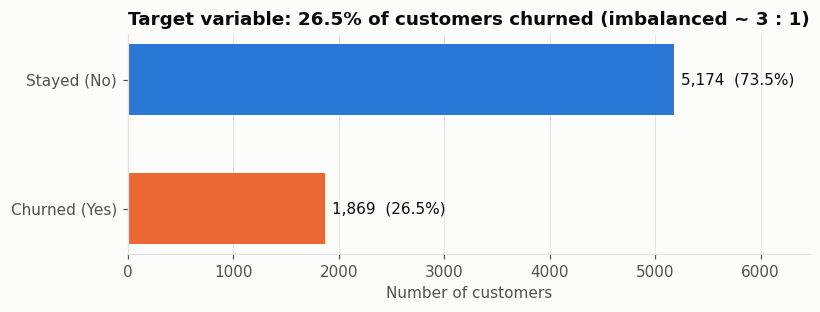

In [22]:
# ---------------------------------------------------------------
# 1.6.1 Class balance of the target
# ---------------------------------------------------------------
counts = df["Churn"].value_counts().reindex(["No", "Yes"])
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 2.6))
bars = ax.barh(["Stayed (No)", "Churned (Yes)"], counts.values, color=[STAY, LEAVE], height=0.55)
for b, n, p in zip(bars, counts.values, pct.values):
    ax.text(b.get_width() + 70, b.get_y() + b.get_height() / 2, f"{n:,}  ({p:.1f}%)", va="center")
ax.invert_yaxis()
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Number of customers")
ax.grid(axis="y", visible=False)
ax.set_title(f"Target variable: {pct['Yes']:.1f}% of customers churned (imbalanced ~ 3 : 1)")
save(fig, "01_churn_distribution.png")
plt.show()

**Observation.** About **1 in 4** customers churned (1,869 of 7,043). The classes are **imbalanced (≈ 73% / 27%)**,
so a model that always predicts "No" would already be 73% accurate. Accuracy alone will therefore be a misleading
metric in Deliverable 3.

### 1.6.2 Distributions of the numeric features

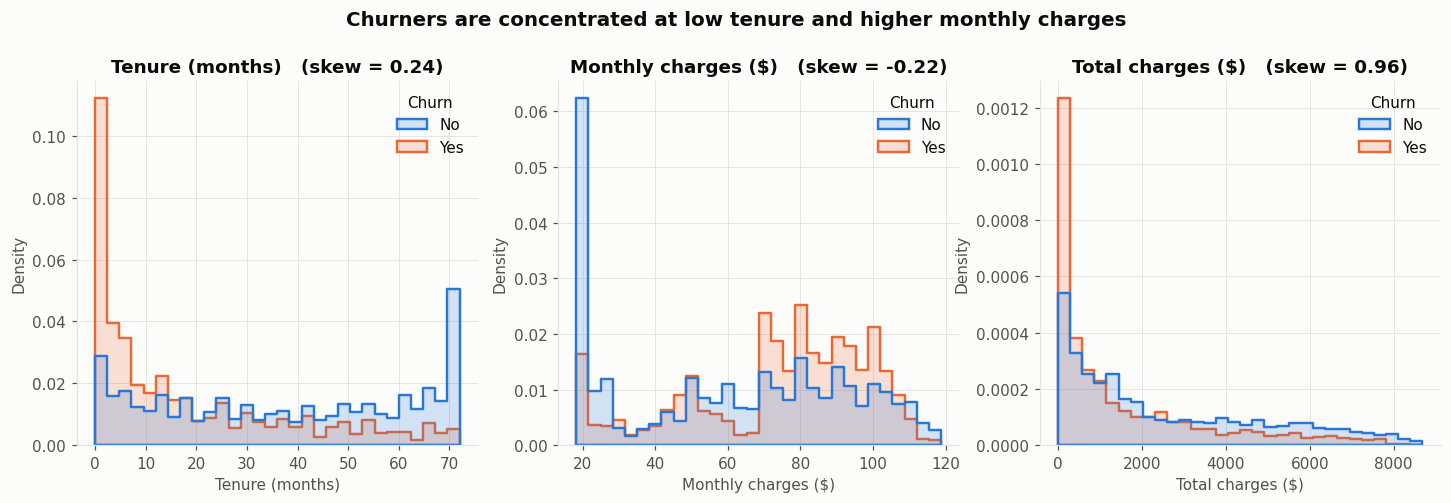

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1679.52
Yes,10.0,79.65,703.55


In [23]:
# ---------------------------------------------------------------
# 1.6.2 Histograms of each numeric feature, split by churn status
# ---------------------------------------------------------------
# stat="density" + common_norm=False puts both groups on the same scale even though
# there are ~3x more "No" customers, so the SHAPES can be compared directly.
labels = {"tenure": "Tenure (months)", "MonthlyCharges": "Monthly charges ($)",
          "TotalCharges": "Total charges ($)"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Churn", hue_order=["No", "Yes"], palette=CHURN_COLORS,
                 bins=30, stat="density", common_norm=False, element="step",
                 fill=True, alpha=0.2, linewidth=1.6, ax=ax)
    ax.set_title(f"{labels[col]}   (skew = {df[col].skew():.2f})")
    ax.set_xlabel(labels[col])
    ax.set_ylabel("Density")
    ax.get_legend().set_title("Churn")
fig.suptitle("Churners are concentrated at low tenure and higher monthly charges", y=1.03,
             fontsize=13, fontweight="bold")
save(fig, "02_numeric_distributions.png")
plt.show()

# Medians by churn status back up what the plots show
df.groupby("Churn")[num_cols].median().round(2)

**Observations**

* **Tenure** is bimodal: many very new customers and many long-standing (≈ 72-month) customers. Churners are piled up
  in the **first few months** (median tenure 10 months vs 38 for customers who stayed).
* **MonthlyCharges** is not normal — there is a large spike around \$20 (phone-only customers with no internet) and a
  broad hump at \$70–\$105. Churners are concentrated in the **higher-charge** range.
* **TotalCharges** is heavily **right-skewed** (skew ≈ 0.96). Churners have *lower* lifetime totals simply because they
  leave early.

### 1.6.3 Outlier check with box plots

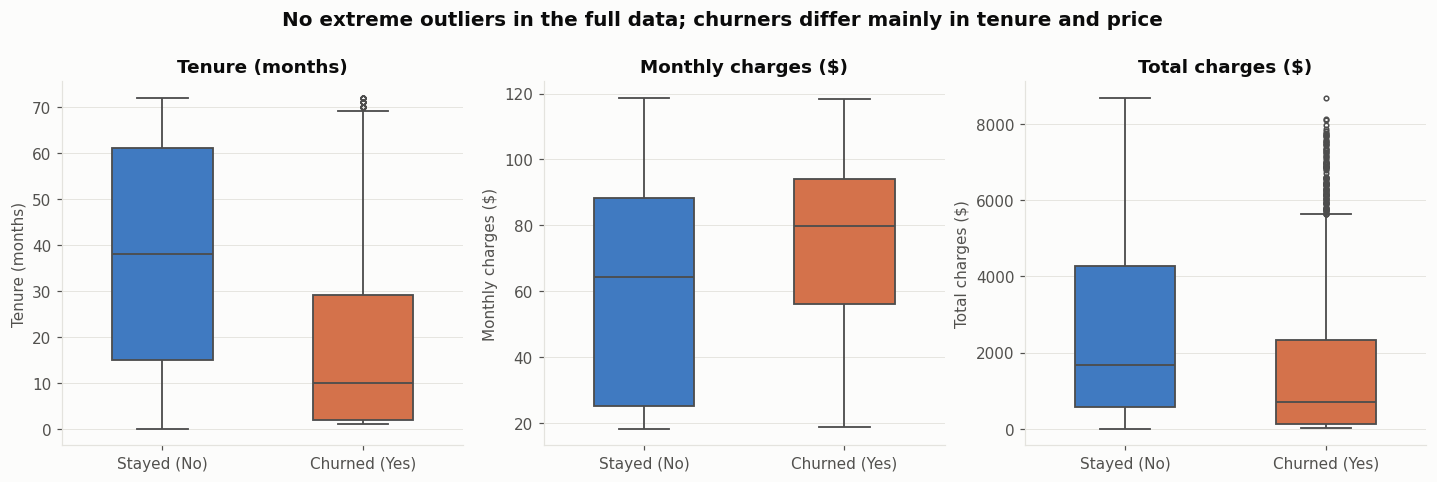

In [24]:
# ---------------------------------------------------------------
# 1.6.3 Box plots: outliers and the spread of each numeric feature by churn status
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=col, order=["No", "Yes"], hue="Churn", hue_order=["No", "Yes"],
                palette=CHURN_COLORS, legend=False, width=0.5, linewidth=1.2, fliersize=3, ax=ax)
    ax.set_xticks([0, 1], ["Stayed (No)", "Churned (Yes)"])
    ax.set_xlabel("")
    ax.set_ylabel(labels[col])
    ax.set_title(labels[col])
fig.suptitle("No extreme outliers in the full data; churners differ mainly in tenure and price", y=1.03,
             fontsize=13, fontweight="bold")
save(fig, "03_boxplots_outliers.png")
plt.show()

**Observations.** Across the full dataset none of the numeric features has values outside the 1.5 × IQR fences
(confirmed numerically in 5.5a). The few points drawn beyond the whiskers for churners' `tenure` and `TotalCharges`
appear only *within the churn subgroup*, because that group is concentrated at short tenures — they are long-tenure
customers who churned, which is real behaviour, not noise. **No outlier removal is needed.**

### 1.6.4 Categorical features vs churn rate

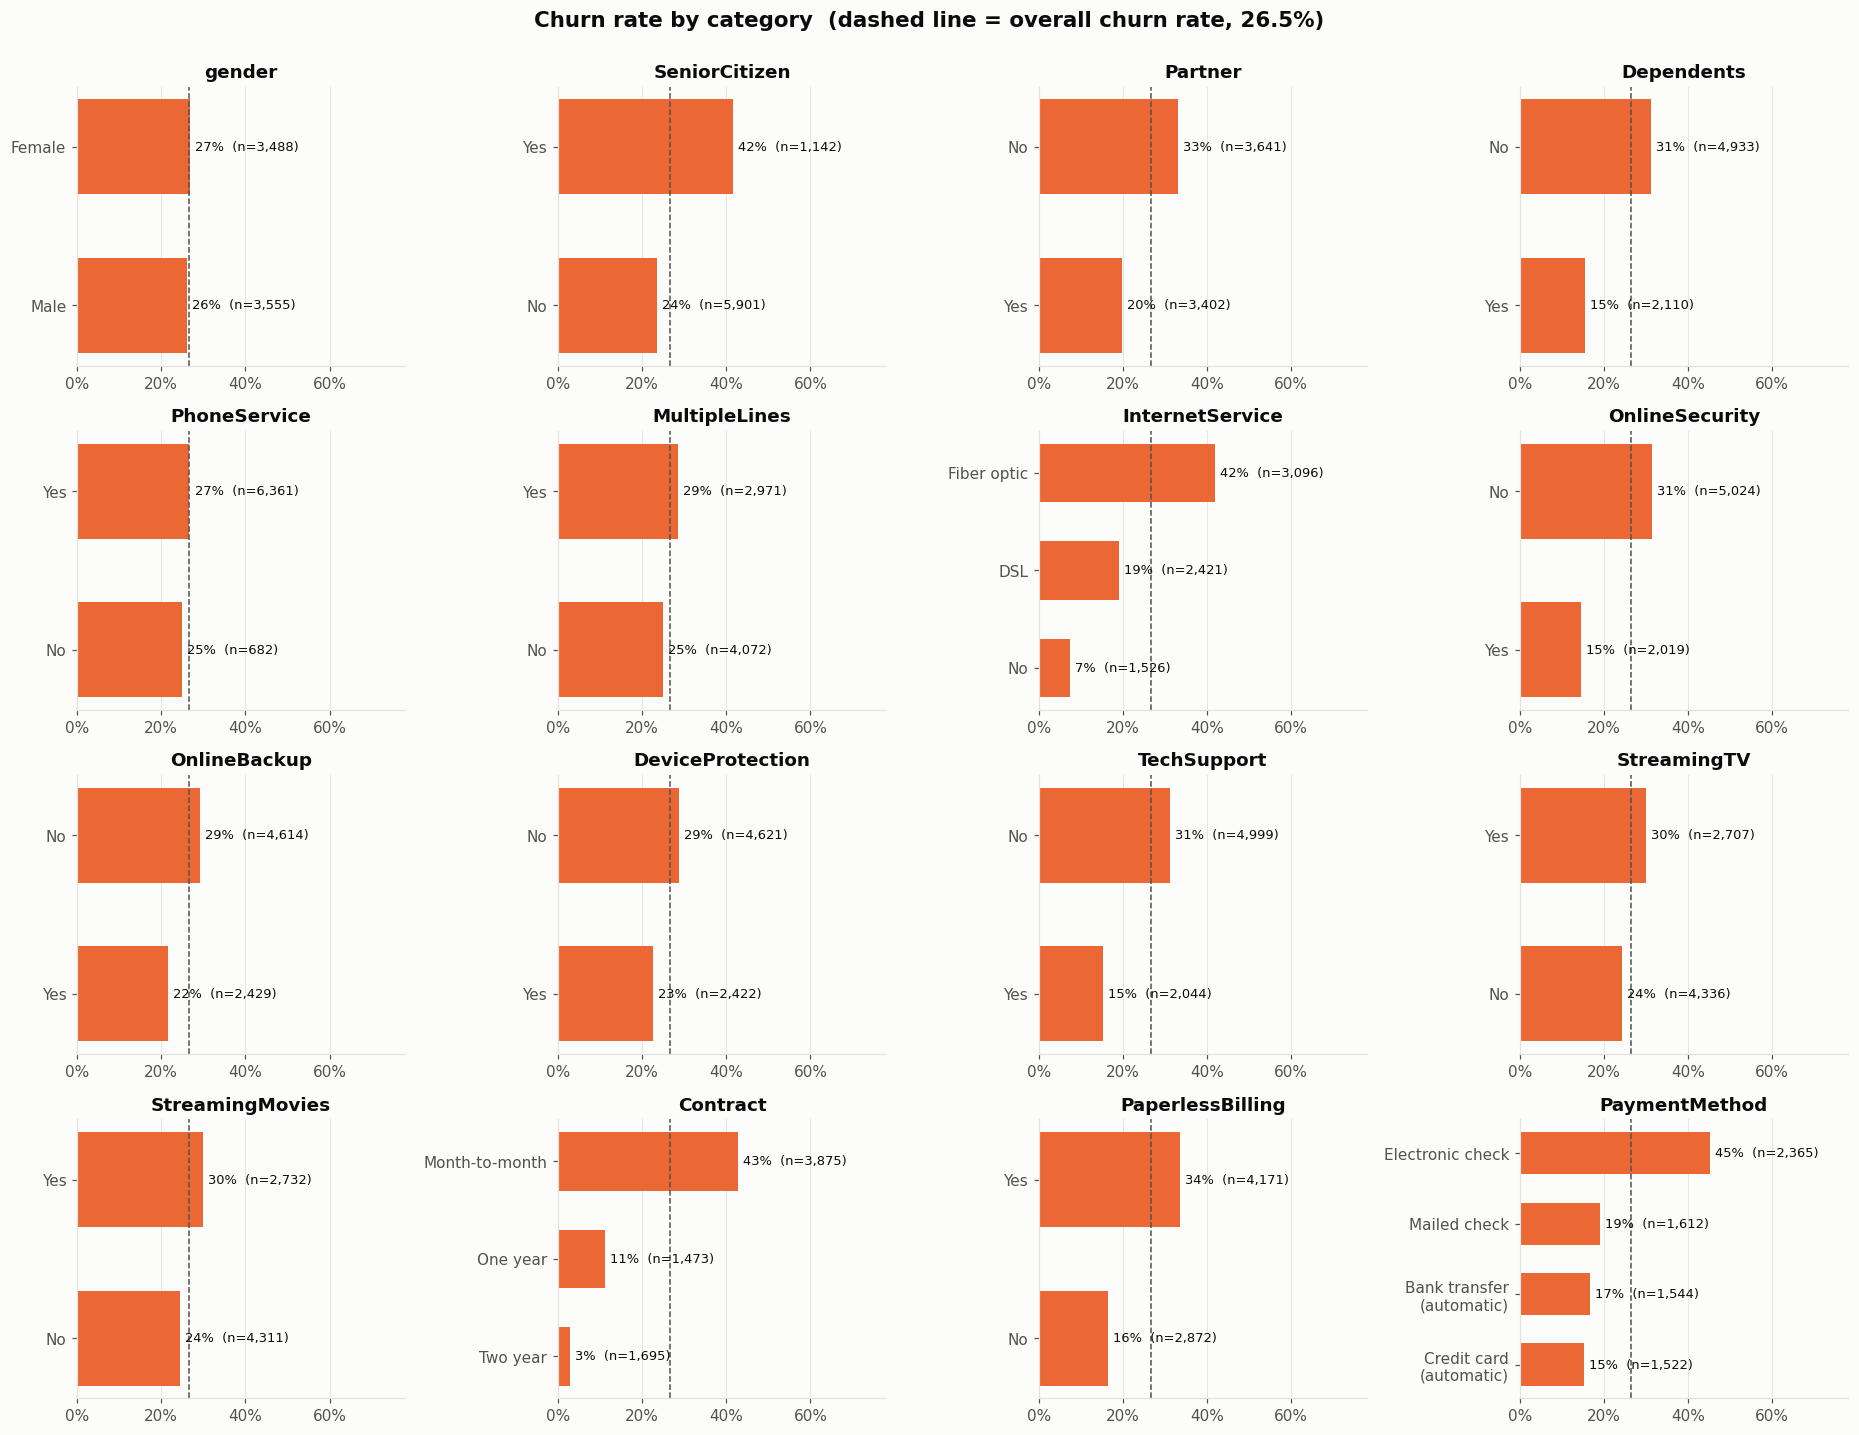

In [25]:
# ---------------------------------------------------------------
# 1.6.4 Churn rate for every level of every categorical feature
# ---------------------------------------------------------------
cat_features = ["gender", "SeniorCitizen", "Partner", "Dependents",
                "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
                "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
                "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
overall = df["Churn_flag"].mean()

fig, axes = plt.subplots(4, 4, figsize=(17, 13))
for ax, col in zip(axes.flat, cat_features):
    rate = df.groupby(col)["Churn_flag"].agg(["mean", "size"]).sort_values("mean")
    names = [str(i).replace(" (", "\n(") for i in rate.index]          # wrap long labels
    ax.barh(names, rate["mean"], color=LEAVE, height=0.6)
    ax.axvline(overall, color=INK_2, ls="--", lw=1)                     # overall churn rate
    for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
        ax.text(m + 0.012, i, f"{m:.0%}  (n={n:,})", va="center", fontsize=8.5)
    ax.set_xlim(0, 0.78)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.grid(axis="y", visible=False)
    ax.set_title(col)
fig.suptitle(f"Churn rate by category  (dashed line = overall churn rate, {overall:.1%})",
             fontsize=14, fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "04_churn_rate_by_category.png")
plt.show()

**Observations**

* **Contract** is the strongest single signal: month-to-month customers churn at **≈ 43%**, compared with ≈ 11% on
  one-year and ≈ 3% on two-year contracts.
* **Fiber optic** internet customers churn at **≈ 42%** — about twice the DSL rate (19%) despite being the premium
  product, which hints at a price or service-quality problem.
* **Electronic check** payers churn at **≈ 45%**, versus 15–19% for every other payment method.
* Customers **without OnlineSecurity or TechSupport** churn about twice as often as those who have them.
* **Senior citizens**, customers **without a partner or dependents**, and **paperless billing** users also churn more.
* **gender** and **PhoneService** show almost no difference from the overall rate — they are weak predictors.

### 1.6.5 Ranking features by strength of association with churn

Visual comparisons can be misleading, so we quantify association:

* **Cramér's V** (from a chi-square test) for categorical features — 0 = no association, 1 = perfect.
* **Point-biserial correlation** for numeric features vs the binary target.

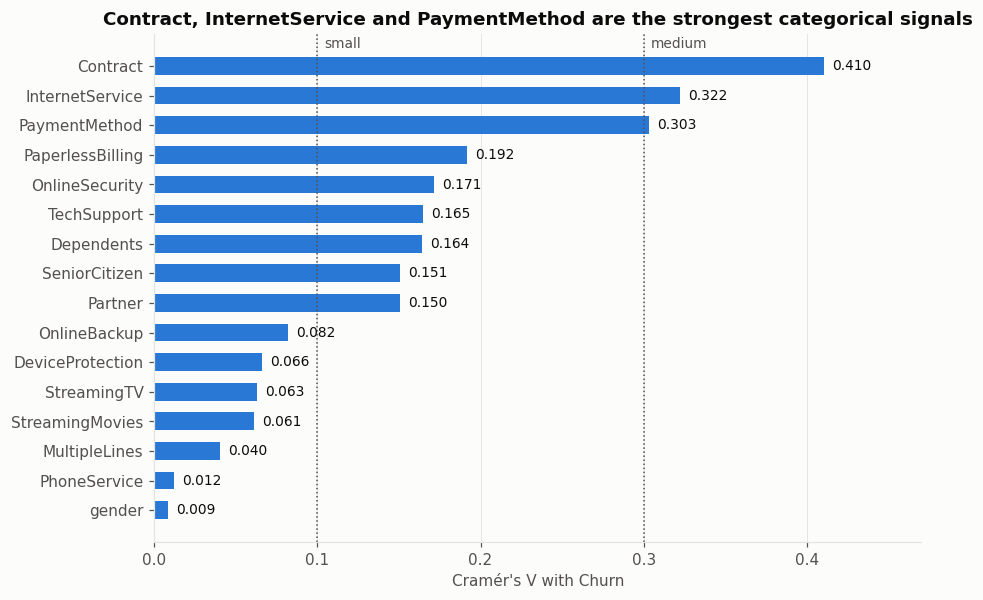

,feature,cramers_v,p_value
0,Contract,0.4101,0.0000
1,InternetService,0.3225,0.0000
2,PaymentMethod,0.3034,0.0000
3,PaperlessBilling,0.1918,0.0000
4,OnlineSecurity,0.1712,0.0000
5,TechSupport,0.1647,0.0000
6,Dependents,0.1642,0.0000
7,SeniorCitizen,0.1509,0.0000
8,Partner,0.1504,0.0000
9,OnlineBackup,0.0823,0.0000


In [26]:
# ---------------------------------------------------------------
# 1.6.5a Cramer's V for each categorical feature vs Churn
# ---------------------------------------------------------------
def cramers_v(x, y):
    # Cramer's V = sqrt( chi2 / (n * (min(rows, cols) - 1)) )
    table = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(table, correction=False)
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1))), p

assoc = pd.DataFrame([(c, *cramers_v(df[c], df["Churn"])) for c in cat_features],
                     columns=["feature", "cramers_v", "p_value"]).sort_values("cramers_v")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(assoc["feature"], assoc["cramers_v"], color=STAY, height=0.6)
for i, v in enumerate(assoc["cramers_v"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
for x, lab in [(0.1, "small"), (0.3, "medium")]:                     # common effect-size guides
    ax.axvline(x, color=INK_2, ls=":", lw=1)
    ax.text(x + 0.004, len(assoc) - 0.4, lab, color=INK_2, fontsize=9)
ax.set_xlim(0, 0.47)
ax.set_xlabel("Cramér's V with Churn")
ax.grid(axis="y", visible=False)
ax.set_title("Contract, InternetService and PaymentMethod are the strongest categorical signals")
save(fig, "05_cramers_v_ranking.png")
plt.show()

assoc.sort_values("cramers_v", ascending=False).round(4).reset_index(drop=True)

In [27]:
# ---------------------------------------------------------------
# 1.6.5b Point-biserial correlation for numeric features vs Churn
# ---------------------------------------------------------------
pb = pd.DataFrame([(c, *pointbiserialr(df["Churn_flag"], df[c])) for c in num_cols + ["NumServices"]],
                  columns=["feature", "r_pb", "p_value"])
pb["r_pb"] = pb["r_pb"].round(3)
pb

,feature,r_pb,p_value
0,tenure,-0.352,7.999058e-205
1,MonthlyCharges,0.193,2.706646e-60
2,TotalCharges,-0.198,2.127212e-63
3,NumServices,-0.019,1.039819e-01


**Observations.** `Contract` (V ≈ 0.41), `InternetService` (≈ 0.32) and `PaymentMethod` (≈ 0.30) have the strongest
categorical associations; `tenure` is the strongest numeric one (r ≈ −0.35: longer tenure → less churn).
`gender` (V ≈ 0.009, p ≈ 0.47) and `PhoneService` (V ≈ 0.012, p ≈ 0.32) are **not statistically significant** and are
candidates to drop from the classification model. `NumServices` has almost no *linear* correlation with churn
(r ≈ −0.02) even though Section 6.7c shows a strong pattern — the relationship is **non-linear** (it rises, then falls),
a reminder that correlation coefficients can miss real effects.

### 1.6.6 Correlation between features (multicollinearity check)

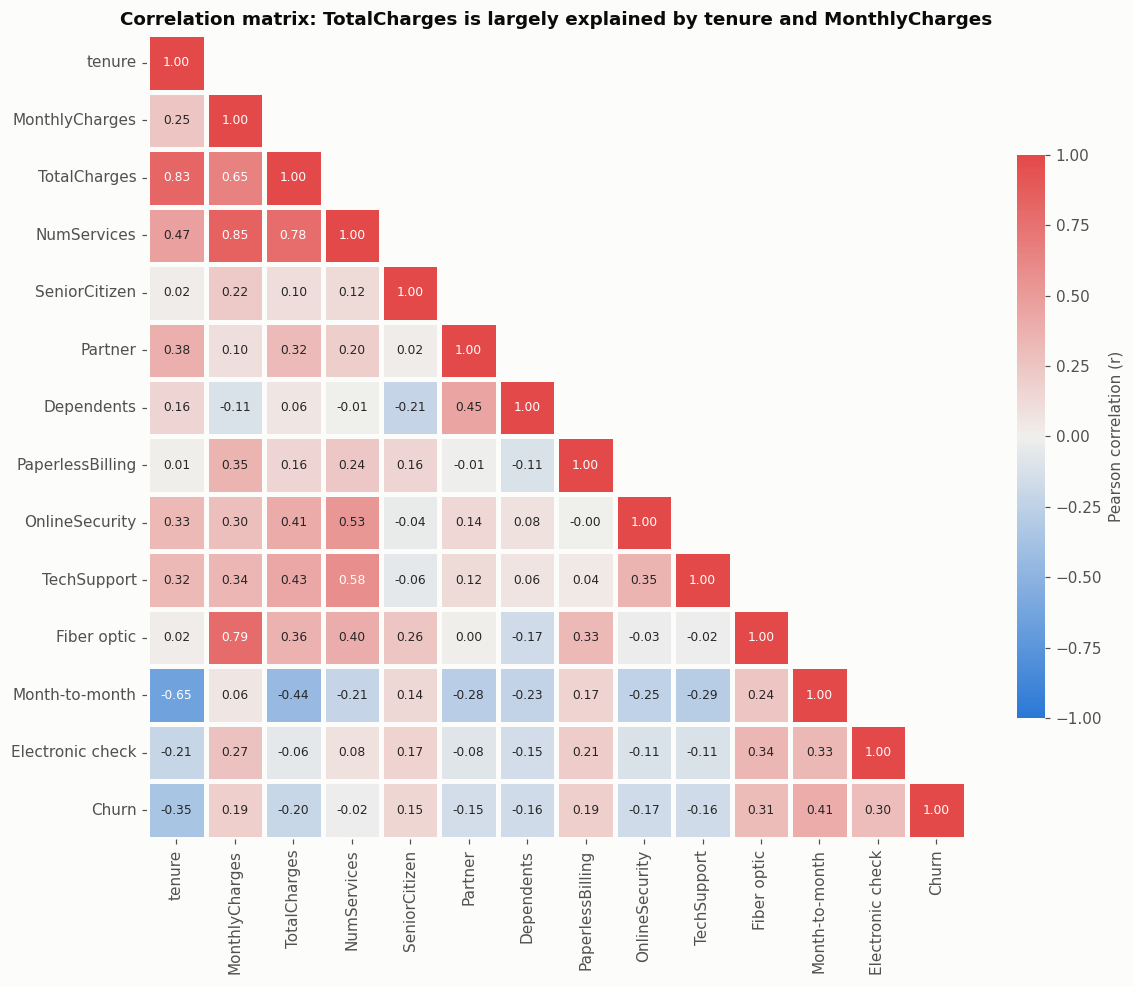

,feature_1,feature_2,r
0,MonthlyCharges,NumServices,0.851
1,TotalCharges,tenure,0.826
2,Fiber optic,MonthlyCharges,0.787
3,NumServices,TotalCharges,0.776
4,MonthlyCharges,TotalCharges,0.651
5,Month-to-month,tenure,-0.646
6,NumServices,TechSupport,0.581
7,NumServices,OnlineSecurity,0.525


In [28]:
# ---------------------------------------------------------------
# 1.6.6 Correlation heatmap of numeric + key binary-encoded features
# ---------------------------------------------------------------
yn = lambda s: s.eq("Yes").astype(int)          # Yes/No -> 1/0
enc = pd.DataFrame({
    "tenure": df["tenure"], "MonthlyCharges": df["MonthlyCharges"],
    "TotalCharges": df["TotalCharges"], "NumServices": df["NumServices"],
    "SeniorCitizen": yn(df["SeniorCitizen"]), "Partner": yn(df["Partner"]),
    "Dependents": yn(df["Dependents"]), "PaperlessBilling": yn(df["PaperlessBilling"]),
    "OnlineSecurity": yn(df["OnlineSecurity"]), "TechSupport": yn(df["TechSupport"]),
    "Fiber optic": df["InternetService"].eq("Fiber optic").astype(int),
    "Month-to-month": df["Contract"].eq("Month-to-month").astype(int),
    "Electronic check": df["PaymentMethod"].eq("Electronic check").astype(int),
    "Churn": df["Churn_flag"],
})
corr = enc.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)       # hide the redundant upper triangle

fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=2, linecolor=SURFACE,
            cbar_kws={"shrink": 0.7, "label": "Pearson correlation (r)"}, ax=ax)
ax.grid(False)
ax.set_title("Correlation matrix: TotalCharges is largely explained by tenure and MonthlyCharges")
save(fig, "06_correlation_heatmap.png")
plt.show()

# The strongest pairwise correlations (excluding the diagonal)
pairs = (corr.where(~np.eye(len(corr), dtype=bool)).stack()
         .reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "r"}))
pairs = pairs[pairs["feature_1"] < pairs["feature_2"]]
pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index).head(8).round(3).reset_index(drop=True)

**Observations**

* `TotalCharges` is strongly correlated with `tenure` (**r ≈ 0.83**) and with `MonthlyCharges` (**r ≈ 0.65**), because it
  is approximately their product. Using all three together in a linear model would cause **multicollinearity**.
* `NumServices` is the strongest predictor of `MonthlyCharges` (**r ≈ 0.85**), followed by `Fiber optic` (**r ≈ 0.79**) —
  more services and a faster connection mean a higher bill.
* `Month-to-month` is strongly negatively correlated with `tenure`: short-tenure customers are on flexible contracts.
* The features most positively correlated with churn are `Month-to-month`, `Fiber optic` and `Electronic check`;
  the most negative are `tenure` and `TotalCharges`.

### 1.6.7 Feature relationships

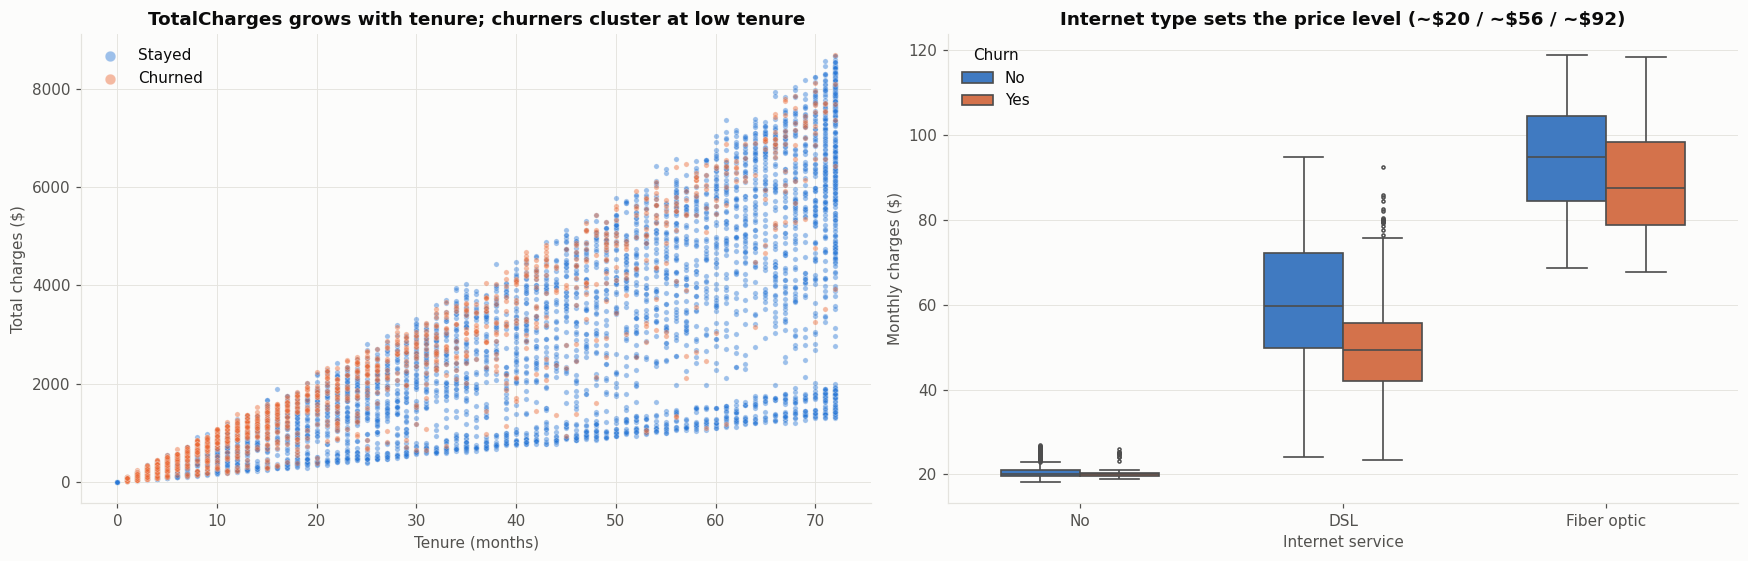

InternetService
DSL            56.15
Fiber optic    91.68
No             20.15
Name: MonthlyCharges, dtype: float64

In [29]:
# ---------------------------------------------------------------
# 1.6.7a Tenure vs TotalCharges, and MonthlyCharges by internet type
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

ax = axes[0]
for status in ["No", "Yes"]:                    # draw churners last so they sit on top
    sub = df[df["Churn"] == status]
    ax.scatter(sub["tenure"], sub["TotalCharges"], s=12, alpha=0.45, color=CHURN_COLORS[status],
               edgecolor=SURFACE, linewidth=0.3, label="Churned" if status == "Yes" else "Stayed")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Total charges ($)")
ax.set_title("TotalCharges grows with tenure; churners cluster at low tenure")
ax.legend(markerscale=2)

ax = axes[1]
sns.boxplot(data=df, x="InternetService", y="MonthlyCharges", hue="Churn", hue_order=["No", "Yes"],
            order=["No", "DSL", "Fiber optic"], palette=CHURN_COLORS, width=0.6, linewidth=1.1,
            fliersize=2, ax=ax)
ax.set_xlabel("Internet service")
ax.set_ylabel("Monthly charges ($)")
ax.set_title("Internet type sets the price level (~$20 / ~$56 / ~$92)")
ax.legend(title="Churn")

fig.tight_layout()
save(fig, "07_feature_relationships.png")
plt.show()

df.groupby("InternetService")["MonthlyCharges"].median().round(2)

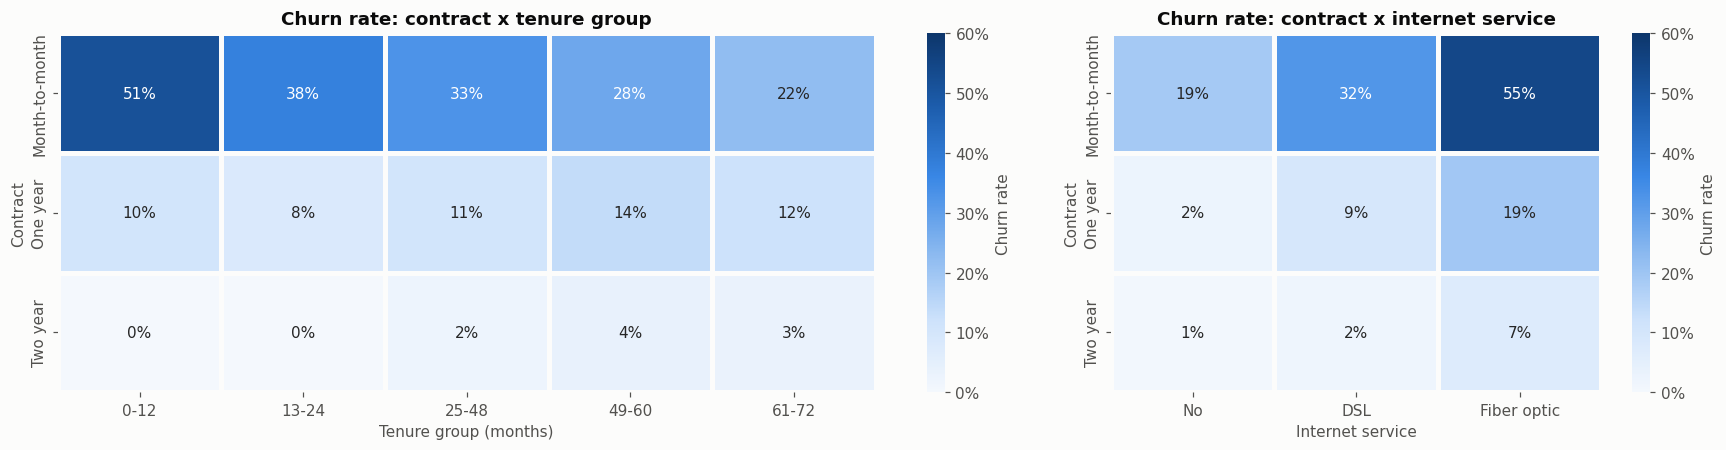

In [30]:
# ---------------------------------------------------------------
# 1.6.7b Interaction heatmaps: churn rate for combinations of two features
# ---------------------------------------------------------------
contract_order = ["Month-to-month", "One year", "Two year"]
t1 = df.pivot_table(index="Contract", columns="tenure_group", values="Churn_flag",
                    aggfunc="mean", observed=True).reindex(contract_order)
t2 = df.pivot_table(index="Contract", columns="InternetService", values="Churn_flag",
                    aggfunc="mean", observed=True).reindex(contract_order)[["No", "DSL", "Fiber optic"]]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [5, 3]})
for ax, tbl, xlabel in [(axes[0], t1, "Tenure group (months)"), (axes[1], t2, "Internet service")]:
    sns.heatmap(tbl, cmap=SEQ_BLUE, vmin=0, vmax=0.6, annot=True, fmt=".0%", linewidths=2,
                linecolor=SURFACE, cbar_kws={"label": "Churn rate", "format": mtick.PercentFormatter(1.0)},
                annot_kws={"size": 10}, ax=ax)
    ax.grid(False)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Contract")
axes[0].set_title("Churn rate: contract x tenure group")
axes[1].set_title("Churn rate: contract x internet service")
fig.tight_layout()
save(fig, "08_interaction_heatmaps.png")
plt.show()

**Observations**

* Within **month-to-month** contracts, churn falls steadily with tenure (51% in the first year → 22% after five
  years). On one- and two-year contracts churn stays low at **every** tenure, so the contract itself — not just
  time with the company — is what keeps customers.
* Within each internet type, churners actually pay slightly **less** than customers who stay (6.7a, right panel).
  The overall "churners pay more" pattern is mostly a **mix effect**: churners are concentrated in the expensive
  fiber-optic tier.
* The **month-to-month + fiber optic** combination churns at **≈ 55%**, whereas **two-year + DSL** churns at only
  **≈ 2%**. Effects combine, so models that capture **interactions** (decision trees, random forests) should
  outperform a model that treats features independently.

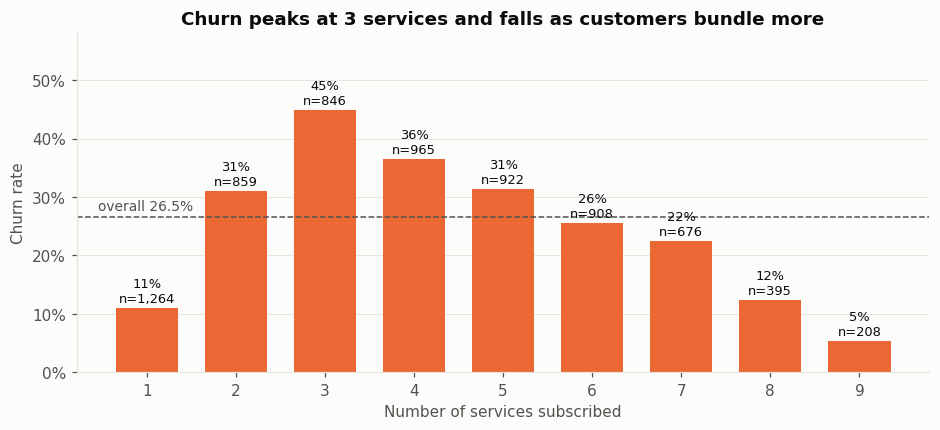

In [31]:
# ---------------------------------------------------------------
# 1.6.7c Number of services vs churn rate
# ---------------------------------------------------------------
svc = df.groupby("NumServices")["Churn_flag"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(svc.index, svc["mean"], color=LEAVE, width=0.7)
ax.axhline(overall, color=INK_2, ls="--", lw=1)
ax.text(0.45, overall + 0.012, f"overall {overall:.1%}", color=INK_2, fontsize=9, ha="left")
for x, m, n in zip(svc.index, svc["mean"], svc["size"]):
    ax.text(x, m + 0.01, f"{m:.0%}\nn={int(n):,}", ha="center", fontsize=8.5)
ax.set_xticks(svc.index)
ax.set_xlabel("Number of services subscribed")
ax.set_ylabel("Churn rate")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 0.58)
ax.grid(axis="x", visible=False)
ax.set_title("Churn peaks at 3 services and falls as customers bundle more")
save(fig, "09_num_services_churn.png")
plt.show()

**Observations.** Phone-only customers (1 service) rarely churn (≈ 11%). Churn peaks at **3 services (≈ 45%)** —
typically internet plus phone with few protective add-ons — and then falls steadily as customers bundle more services,
reaching ≈ 5% at 9 services. Bundling appears to "lock in" customers, which is a useful pattern to test with
association rules in Deliverable 4.

In [32]:
# ---------------------------------------------------------------
# 1.6.8 Key numbers quoted in the insights section (computed, not typed by hand)
# ---------------------------------------------------------------
inet = df[df["InternetService"] != "No"]          # customers who could buy add-ons
key = {
    "Churn rate overall": overall,
    "Churn rate - month-to-month": df.loc[df.Contract.eq("Month-to-month"), "Churn_flag"].mean(),
    "Share of all churners on month-to-month": df.loc[df.Churn_flag.eq(1), "Contract"].eq("Month-to-month").mean(),
    "Churn rate - fiber optic": df.loc[df.InternetService.eq("Fiber optic"), "Churn_flag"].mean(),
    "Churn rate - electronic check": df.loc[df.PaymentMethod.eq("Electronic check"), "Churn_flag"].mean(),
    "Churn rate - first 12 months": df.loc[df.tenure_group.eq("0-12"), "Churn_flag"].mean(),
    "Churn rate - 61-72 months": df.loc[df.tenure_group.eq("61-72"), "Churn_flag"].mean(),
    "Internet users WITHOUT TechSupport": inet.loc[inet.TechSupport.eq("No"), "Churn_flag"].mean(),
    "Internet users WITH TechSupport": inet.loc[inet.TechSupport.eq("Yes"), "Churn_flag"].mean(),
    "Internet users WITHOUT OnlineSecurity": inet.loc[inet.OnlineSecurity.eq("No"), "Churn_flag"].mean(),
    "Internet users WITH OnlineSecurity": inet.loc[inet.OnlineSecurity.eq("Yes"), "Churn_flag"].mean(),
    "Churn rate - senior citizens": df.loc[df.SeniorCitizen.eq("Yes"), "Churn_flag"].mean(),
}
pd.Series(key, name="value").map("{:.1%}".format).to_frame()

,value
Churn rate overall,26.5%
Churn rate - month-to-month,42.7%
Share of all churners on month-to-month,88.6%
Churn rate - fiber optic,41.9%
Churn rate - electronic check,45.3%
Churn rate - first 12 months,47.4%
Churn rate - 61-72 months,6.6%
Internet users WITHOUT TechSupport,41.6%
Internet users WITH TechSupport,15.2%
Internet users WITHOUT OnlineSecurity,41.8%


## 1.7 Key Insights and How They Guide the Next Deliverables

### 1.7.1 Summary of insights

1. **Churn is imbalanced and substantial.** 26.5% of customers churned (1,869 of 7,043).
2. **Contract type is the #1 driver.** Month-to-month customers churn at 42.7% vs 2.8% on two-year contracts, and they
   account for **88.6% of all churners**.
3. **The first year is the danger zone.** Customers in their first 12 months churn at 47.4%; customers past 5 years
   churn at only 6.6%. Churners have a median tenure of 10 months vs 38 for loyal customers.
4. **Price and product matter.** Churners pay more per month (median \$79.65 vs \$64.43). Fiber-optic customers churn
   at 41.9%, about twice the DSL rate.
5. **Payment behaviour is a signal.** Electronic-check payers churn at 45.3%; automatic payment methods churn at 15–17%.
6. **Protective add-ons reduce churn.** Among internet users, those without TechSupport churn at 41.6% vs 15.2% with it;
   the same pattern holds for OnlineSecurity (41.8% vs 14.6%).
7. **Effects combine.** Month-to-month + fiber optic → ≈ 55% churn; two-year + DSL → ≈ 2%.
8. **Weak features.** `gender` and `PhoneService` show no significant association with churn.
9. **Redundancy.** `TotalCharges` ≈ `tenure × MonthlyCharges` (r = 0.83 with tenure), so the three numeric features
   overlap heavily.

### 1.7.2 How these insights guided the modelling

* **Class imbalance** → stratified splits, class weights and F1 / ROC-AUC in Part 3A.
* **Multicollinearity** (`TotalCharges ≈ tenure × MonthlyCharges`) → leakage check and Ridge/Lasso in Part 2.
* **Strong categorical drivers and interactions** (contract × internet × tenure) → engineered interaction features (Part 2) and tree-based classifiers (Part 3A).
* **Weak features** (`gender`, `PhoneService`) → removed from the churn classifiers (Part 3A).
* **Binary service flags and tenure bins** → items for association rule mining (Part 3C).

## 1.8 Challenges Encountered and How They Were Addressed

| Challenge | How it was addressed |
|---|---|
| **Missing values were hidden.** `isna()` reported 0 missing values because the 11 empty `TotalCharges` cells contained a space, which also forced the whole column to be read as text. | Scanned every text column for whitespace-only cells, stripped whitespace, converted with `pd.to_numeric`, and only then counted missing values. |
| **Choosing an imputation method.** Mean/median imputation would have given brand-new customers a lifetime bill of over \$1,000. | Investigated the rows first; all had `tenure = 0`, so the value was imputed with **0**, which is logically correct. |
| **Deciding whether "duplicates" were errors.** 22 rows were identical except for their ID. | Inspected them instead of dropping blindly: all were first-month, month-to-month customers on 1–2 basic services with no add-ons, so they are genuine distinct customers and were kept. |
| **Inconsistent and redundant encodings** (`0/1` vs `Yes/No`; "No internet service"). | Verified that the extra levels are *exactly* implied by `InternetService`/`PhoneService` before merging them into "No", so no information was lost; validated every column against its allowed set of values. |
| **Separating noise from real behaviour.** `TotalCharges` is skewed and some bills do not equal `tenure × MonthlyCharges`. | Used IQR + z-score rules (0 outliers), domain-rule checks (0 violations) and a ratio check (27 minor mismatches explained by price changes). Kept all records and smoothed `tenure` by binning. |
| **Class imbalance can hide patterns in raw counts.** | Compared **churn rates** (not counts) and used `common_norm=False` density plots so both classes are visible on the same scale. |

## 1.9 Conclusion

The Telco Customer Churn dataset is now **clean, consistent and fully numeric where it should be**: 7,043 customers,
0 missing values, validated categories, and three helper columns (`Churn_flag`, `tenure_group`, `NumServices`).
The cleaned file is saved as `telco_churn_cleaned.csv` and is the starting point for Parts 2–3.
EDA shows that churn is driven mainly by **contract flexibility, early tenure, fiber-optic service, electronic-check
payment and the absence of protective add-ons**, which gives clear, testable hypotheses for the regression,
classification, clustering and association-rule models that follow.

---
# Part 2 – Regression Modeling and Performance Evaluation (Deliverable 2)

In [33]:
FIG_PREFIX = "p2_"     # figures from Part 2 are saved as Images/p2_*.png

## 2.1 Choosing the Regression Target

**Business question:** *How much revenue is a customer worth, given their plan and profile?*
We predict **`TotalCharges`** — the total amount a customer has been billed over their relationship with the company
(their lifetime revenue to date). Estimating customer value lets the business decide **how much it can afford to spend
to retain each customer**, which pairs directly with the churn model in Deliverable 3 (revenue at risk = churn
probability × customer value).

**Why not the target planned in Deliverable 1?** Deliverable 1 proposed predicting `MonthlyCharges`. Before building
models we ran two quick sanity checks (code below):

| Candidate | Check | Result | Problem |
|---|---|---|---|
| `MonthlyCharges` from the services a customer buys | 5-fold CV R² of a plain linear regression | ≈ 0.999 | The bill is a **price-list lookup** (base price + add-on prices). There is nothing left to predict, every model ties, and model comparison is meaningless. |
| `TotalCharges` using **tenure** as a feature | 5-fold CV R² | ≈ 0.999 | `TotalCharges ≈ tenure × MonthlyCharges`. Using tenure is **target leakage**: the answer is built from the inputs. |
| **`TotalCharges` without tenure** | 5-fold CV R² | ≈ 0.75 | A realistic, non-trivial problem: the model must infer how valuable a customer is from contract, services, billing and demographics. **Chosen.** |

So `tenure` (and `tenure_group`, which is derived from it) are **excluded** from the predictors. `Churn` is also
excluded: it is an outcome (and the target of Deliverable 3), not a description of the customer's plan or profile.

### 2.2 Reload the cleaned data written by Part 1

In [34]:
# ---------------------------------------------------------------
# Reload the cleaned dataset written in Part 1 (same file used in every part)
# ---------------------------------------------------------------
# The file is stored in this repository; if it is missing, the identical copy
# from the Deliverable 1 repository on GitHub is used instead.
DATA_PATH = "telco_churn_cleaned.csv"
DATA_URL = "https://raw.githubusercontent.com/pranavibalakulla/MSCS_634_Project_Deliverable_1/main/telco_churn_cleaned.csv"

source = DATA_PATH if os.path.exists(DATA_PATH) else DATA_URL
df = pd.read_csv(source)
print(f"Loaded from: {source}")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}   Missing values: {int(df.isna().sum().sum())}")
df.head(3)

Loaded from: telco_churn_cleaned.csv
Rows: 7,043   Columns: 24   Missing values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_flag,tenure_group,NumServices
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12,2
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,25-48,4
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12,4


In [35]:
# ---------------------------------------------------------------
# 2.1b. Sanity checks behind the target choice (see the table in Section 1)
# ---------------------------------------------------------------
kf_check = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def quick_r2(X, y):
    # Mean 5-fold cross-validated R^2 of an ordinary linear regression
    return cross_validate(LinearRegression(), X, y, cv=kf_check, scoring="r2")["test_score"].mean()

# (a) MonthlyCharges explained by the services purchased
X_a = pd.get_dummies(df[service_cols + ["InternetService"]], drop_first=True, dtype=float)
# (b) TotalCharges when tenure and MonthlyCharges are both allowed
X_b = df[["tenure", "MonthlyCharges"]].assign(tenure_x_monthly=df["tenure"] * df["MonthlyCharges"])
# (c) TotalCharges from plan + profile, WITHOUT tenure
profile_cols = ["SeniorCitizen", "Partner", "Dependents", "gender", "InternetService", "Contract",
                "PaperlessBilling", "PaymentMethod"] + service_cols
X_c = pd.get_dummies(df[profile_cols], drop_first=True, dtype=float).assign(MonthlyCharges=df["MonthlyCharges"])

pd.DataFrame({
    "candidate": ["MonthlyCharges ~ services", "TotalCharges ~ tenure, MonthlyCharges",
                  "TotalCharges ~ plan + profile (no tenure)"],
    "5-fold CV R2": [quick_r2(X_a, df["MonthlyCharges"]), quick_r2(X_b, df["TotalCharges"]),
                     quick_r2(X_c, df["TotalCharges"])],
}).round(4)

,candidate,5-fold CV R2
0,MonthlyCharges ~ services,0.9988
1,"TotalCharges ~ tenure, MonthlyCharges",0.9991
2,TotalCharges ~ plan + profile (no tenure),0.7480


## 2.3 Understanding the Target

count    7043.00
mean     2279.73
std      2266.79
min         0.00
25%       398.55
50%      1394.55
75%      3786.60
max      8684.80
Name: TotalCharges, dtype: float64


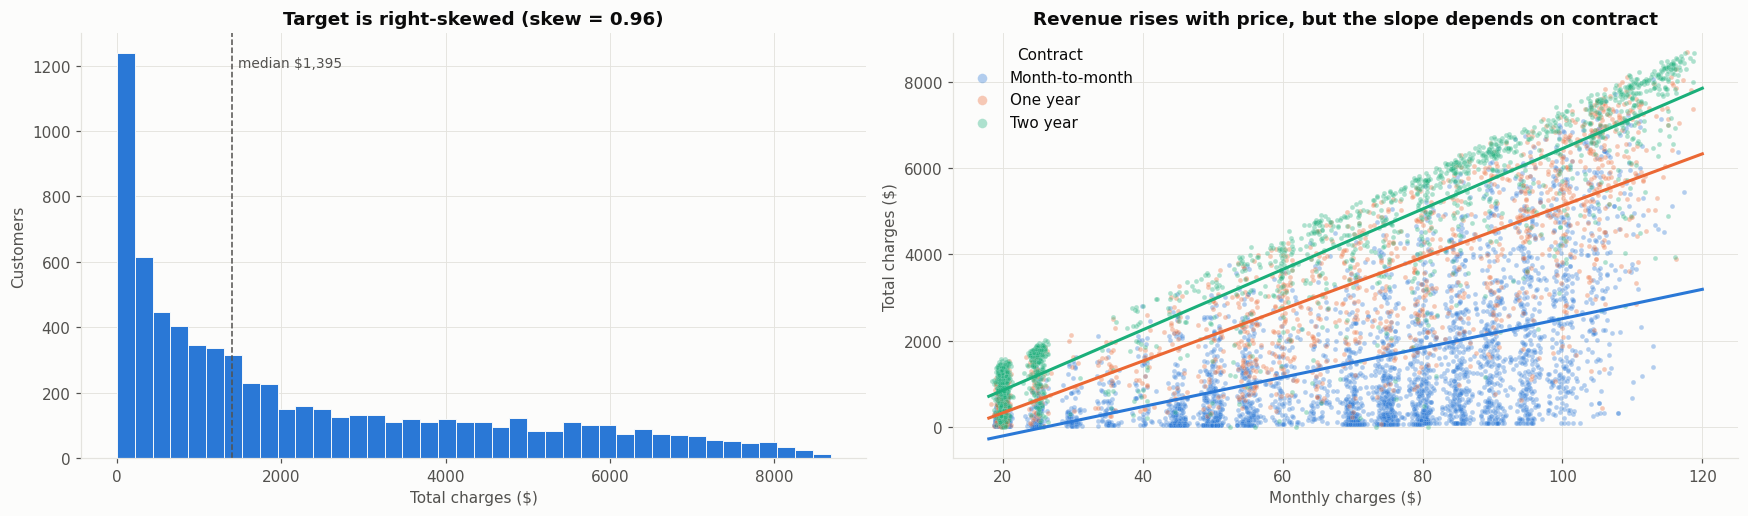

,total $ per $1 of monthly price
Contract,
Month-to-month,20.6
One year,46.6
Two year,61.0


In [36]:
# ---------------------------------------------------------------
# 2.3. Target distribution and its relationship with price and contract
# ---------------------------------------------------------------
TARGET = "TotalCharges"
print(df[TARGET].describe().round(2))

contract_order = ["Month-to-month", "One year", "Two year"]
contract_colors = dict(zip(contract_order, CAT[:3]))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

ax = axes[0]
ax.hist(df[TARGET], bins=40, color=CAT[0], edgecolor=SURFACE, linewidth=0.6)
ax.axvline(df[TARGET].median(), color=INK_2, ls="--", lw=1)
ax.text(df[TARGET].median() + 80, ax.get_ylim()[1] * 0.92,
        f"median ${df[TARGET].median():,.0f}", color=INK_2, fontsize=9)
ax.set_xlabel("Total charges ($)")
ax.set_ylabel("Customers")
ax.set_title(f"Target is right-skewed (skew = {df[TARGET].skew():.2f})")

ax = axes[1]
for c in contract_order:
    sub = df[df["Contract"] == c]
    ax.scatter(sub["MonthlyCharges"], sub[TARGET], s=10, alpha=0.35, color=contract_colors[c],
               edgecolor=SURFACE, linewidth=0.2, label=c)
    slope = np.polyfit(sub["MonthlyCharges"], sub[TARGET], 1)
    xs = np.linspace(18, 120, 50)
    ax.plot(xs, np.polyval(slope, xs), color=contract_colors[c], lw=2)
ax.set_xlabel("Monthly charges ($)")
ax.set_ylabel("Total charges ($)")
ax.set_title("Revenue rises with price, but the slope depends on contract")
ax.legend(title="Contract", markerscale=2)

fig.tight_layout()
save(fig, "01_target_distribution.png")
plt.show()

# Average lifetime revenue per $ of monthly price, by contract
(df.groupby("Contract")[TARGET].sum() / df.groupby("Contract")["MonthlyCharges"].sum()).round(1).rename(
    "total $ per $1 of monthly price").to_frame()

**Observations**

* `TotalCharges` is **right-skewed**: many recent customers with small totals and a long tail of high-value customers.
* Lifetime revenue grows with the monthly price, but the **slope differs by contract**: each dollar of monthly price
  is worth far more for two-year customers than for month-to-month customers (because they stay much longer).
  A plain linear model gives `MonthlyCharges` **one** slope for everyone, so it cannot represent this.
  This is the key motivation for the **interaction features** engineered in Section 4.

## 2.4 Feature Engineering

We build two feature sets so the effect of feature engineering can be measured directly.

**Raw feature set** — the cleaned attributes as they are: one-hot encoded categorical columns + `MonthlyCharges`.

**Engineered feature set** — the raw set **plus** new features, each motivated by the EDA:

| New feature | Definition | Why it should help |
|---|---|---|
| `NumServices` | Number of services subscribed (from Deliverable 1) | Customers with more services are more "embedded" and stay longer |
| `ProtectionAddons` | Count of OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport | Deliverable 1 showed protective add-ons strongly linked to retention |
| `StreamingAddons` | Count of StreamingTV, StreamingMovies | Separates entertainment spend from protection spend |
| `AutoPay` | 1 if paying by automatic bank transfer or credit card | Automatic payers churned far less in Deliverable 1 |
| `FamilyAccount` | 1 if the customer has a partner **or** dependents | Combines two related household signals |
| `Contract × MonthlyCharges` (2 terms) | Monthly price multiplied by each contract dummy | Lets the price slope differ by contract (Section 3 scatter plot) |
| `AutoPay × MonthlyCharges` | Monthly price × automatic-payment flag | Lets price matter more for stable, auto-paying customers |
| `FamilyAccount × MonthlyCharges` | Monthly price × household flag | Same idea for household customers |
| `NumServices × MonthlyCharges` | Price × number of services | Captures "embedded and high-spend" customers |
| `MonthlyCharges²` | Squared monthly price | Allows a curved (non-linear) price effect |

All features are standardised inside each model pipeline, so the scaling is learned only from training folds.

In [37]:
# ---------------------------------------------------------------
# 2.4.1 Raw feature set: one-hot categoricals + MonthlyCharges
# ---------------------------------------------------------------
categorical_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
                    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

# drop_first=True avoids the "dummy variable trap" (perfect multicollinearity) in linear models
X_raw = pd.get_dummies(df[categorical_cols], drop_first=True, dtype=float)
X_raw["MonthlyCharges"] = df["MonthlyCharges"]
y = df[TARGET].copy()

# Deliberately EXCLUDED: tenure, tenure_group (leakage), Churn/Churn_flag (outcome), customerID (identifier)
print("Raw feature set:", X_raw.shape[1], "features")

Raw feature set: 21 features


In [38]:
# ---------------------------------------------------------------
# 2.4.2 Engineered feature set
# ---------------------------------------------------------------
X_eng = X_raw.copy()
mc = df["MonthlyCharges"]

# Count features
X_eng["NumServices"] = df["NumServices"]
X_eng["ProtectionAddons"] = df[["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]].eq("Yes").sum(axis=1)
X_eng["StreamingAddons"] = df[["StreamingTV", "StreamingMovies"]].eq("Yes").sum(axis=1)

# Combined flags
X_eng["AutoPay"] = df["PaymentMethod"].str.contains("automatic").astype(float)
X_eng["FamilyAccount"] = (df["Partner"].eq("Yes") | df["Dependents"].eq("Yes")).astype(float)

# Interaction terms: allow the effect of price to differ between customer types
X_eng["OneYear_x_Monthly"] = X_raw["Contract_One year"] * mc
X_eng["TwoYear_x_Monthly"] = X_raw["Contract_Two year"] * mc
X_eng["AutoPay_x_Monthly"] = X_eng["AutoPay"] * mc
X_eng["Family_x_Monthly"] = X_eng["FamilyAccount"] * mc
X_eng["NumServices_x_Monthly"] = X_eng["NumServices"] * mc

# Polynomial term: allow a curved price effect
X_eng["MonthlyCharges_sq"] = mc ** 2

new_features = [c for c in X_eng.columns if c not in X_raw.columns]
print("Engineered feature set:", X_eng.shape[1], "features  (", len(new_features), "new )")

# Correlation of each new feature with the target (quick check that they carry signal)
X_eng[new_features].corrwith(y).sort_values(ascending=False).round(3).rename("corr_with_TotalCharges").to_frame()

Engineered feature set: 32 features  ( 11 new )


,corr_with_TotalCharges
NumServices_x_Monthly,0.800
NumServices,0.776
MonthlyCharges_sq,0.693
ProtectionAddons,0.678
StreamingAddons,0.591
TwoYear_x_Monthly,0.584
Family_x_Monthly,0.542
AutoPay_x_Monthly,0.530
OneYear_x_Monthly,0.336
AutoPay,0.307


## 2.5 Train/Test Split and Model Definitions

* **80 / 20 split** (`random_state = 42`). The 20% **test set is locked away** and used once, at the end.
* All model selection uses **5-fold cross-validation on the training set only**.

**Models compared** (each wrapped in a pipeline with `StandardScaler`):

| Model | Type | Why it is included |
|---|---|---|
| Linear Regression | Multiple linear regression (OLS) | Interpretable baseline |
| Ridge Regression | L2-regularised linear | Shrinks correlated coefficients (multicollinearity found in Deliverable 1); `alpha` chosen by internal CV (`RidgeCV`) |
| Lasso Regression | L1-regularised linear | Shrinks **and** removes weak features (built-in feature selection); `alpha` chosen by internal CV (`LassoCV`) |
| Random Forest | Ensemble of decision trees | Captures non-linear effects and interactions automatically |
| Gradient Boosting | Sequential tree ensemble | Usually the strongest tabular model; checks whether linear models leave signal behind |

In [39]:
# ---------------------------------------------------------------
# 2.5.1 Hold-out split (same rows for both feature sets)
# ---------------------------------------------------------------
idx_train, idx_test = train_test_split(df.index, test_size=0.20, random_state=RANDOM_STATE)
print(f"Training rows: {len(idx_train):,}   Test rows: {len(idx_test):,}")
print(f"Mean TotalCharges - train: ${y.loc[idx_train].mean():,.0f}   test: ${y.loc[idx_test].mean():,.0f}")

Training rows: 5,634   Test rows: 1,409
Mean TotalCharges - train: $2,287   test: $2,250


In [40]:
# ---------------------------------------------------------------
# 2.5.2 Model pipelines
# ---------------------------------------------------------------
def make_models():
    # Fresh, unfitted model objects (called separately for each feature set)
    return {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 61))),
        "Lasso": make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-2, 3, 60), cv=5, max_iter=50000,
                                                          random_state=RANDOM_STATE)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestRegressor(
            n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)),
        "Gradient Boosting": make_pipeline(StandardScaler(), GradientBoostingRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)),
    }

MODEL_NAMES = list(make_models().keys())
MODEL_COLORS = dict(zip(MODEL_NAMES, CAT[:5]))     # fixed colour per model in every chart

## 2.6 Cross-Validation (5-fold) on Raw vs Engineered Features

Cross-validation estimates how well each model **generalises to unseen data**: the training set is split into 5 folds;
each model is trained on 4 folds and scored on the 5th, five times. We report the **mean and standard deviation** of:

* **R²** – share of variance in lifetime revenue explained (1.0 = perfect)
* **MSE** – mean squared error (\$²); penalises large errors heavily
* **RMSE** – square root of MSE, in dollars (typical size of an error)
* **MAE** – mean absolute error, in dollars (less sensitive to large errors)

In [41]:
# ---------------------------------------------------------------
# 2.6.1 Run 5-fold CV for every model on both feature sets
# ---------------------------------------------------------------
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"r2": "r2", "mse": "neg_mean_squared_error", "mae": "neg_mean_absolute_error"}

cv_rows, fold_rows = [], []
for set_name, X in [("Raw", X_raw), ("Engineered", X_eng)]:
    for name, model in make_models().items():
        start = time.time()
        res = cross_validate(model, X.loc[idx_train], y.loc[idx_train], cv=cv, scoring=scoring)
        mse = -res["test_mse"]
        rmse = np.sqrt(mse)                       # RMSE per fold
        cv_rows.append({
            "features": set_name, "model": name,
            "R2_mean": res["test_r2"].mean(), "R2_std": res["test_r2"].std(),
            "MSE_mean": mse.mean(),
            "RMSE_mean": rmse.mean(), "RMSE_std": rmse.std(),
            "MAE_mean": -res["test_mae"].mean(),
            "seconds": time.time() - start,
        })
        for k in range(cv.get_n_splits()):
            fold_rows.append({"features": set_name, "model": name, "fold": k + 1,
                              "R2": res["test_r2"][k], "RMSE": rmse[k]})

cv_results = pd.DataFrame(cv_rows)
fold_results = pd.DataFrame(fold_rows)

show = cv_results.copy()
show["R2 (mean ± std)"] = show.apply(lambda r: f"{r.R2_mean:.4f} ± {r.R2_std:.4f}", axis=1)
show["RMSE $ (mean ± std)"] = show.apply(lambda r: f"{r.RMSE_mean:,.1f} ± {r.RMSE_std:,.1f}", axis=1)
show["MSE"] = show["MSE_mean"].map("{:,.0f}".format)
show["MAE $"] = show["MAE_mean"].map("{:,.1f}".format)
show[["features", "model", "R2 (mean ± std)", "RMSE $ (mean ± std)", "MSE", "MAE $"]]

,features,model,R2 (mean ± std),RMSE $ (mean ± std),MSE,MAE $
0,Raw,Linear Regression,0.7441 ± 0.0094,"1,144.3 ± 18.9","1,309,746",898.6
1,Raw,Ridge,0.7442 ± 0.0094,"1,144.0 ± 18.7","1,309,057",898.0
2,Raw,Lasso,0.7441 ± 0.0094,"1,144.2 ± 18.7","1,309,480",898.5
3,Raw,Random Forest,0.7791 ± 0.0168,"1,062.5 ± 36.7","1,130,274",756.1
4,Raw,Gradient Boosting,0.7897 ± 0.0146,"1,036.9 ± 32.8","1,076,160",736.6
5,Engineered,Linear Regression,0.7918 ± 0.0103,"1,031.9 ± 22.2","1,065,253",741.6
6,Engineered,Ridge,0.7917 ± 0.0103,"1,032.2 ± 22.3","1,065,855",742.2
7,Engineered,Lasso,0.7917 ± 0.0103,"1,032.2 ± 22.1","1,065,839",742.2
8,Engineered,Random Forest,0.7754 ± 0.0156,"1,071.4 ± 34.4","1,149,187",761.4
9,Engineered,Gradient Boosting,0.7891 ± 0.0120,"1,038.5 ± 25.7","1,079,185",740.5


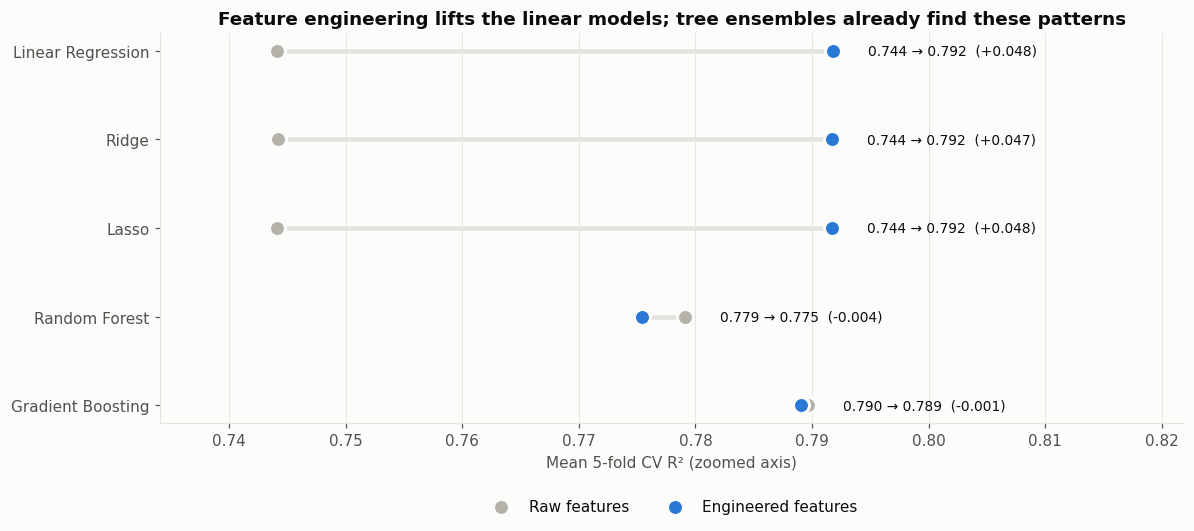

,R2 raw,R2 engineered,R2 gain,RMSE raw $,RMSE engineered $,RMSE reduction $
model,,,,,,
Linear Regression,0.7441,0.7918,0.0477,1144.2852,1031.8732,112.4120
Ridge,0.7442,0.7917,0.0475,1143.9871,1032.1622,111.8250
Lasso,0.7441,0.7917,0.0476,1144.1714,1032.1578,112.0136
Random Forest,0.7791,0.7754,-0.0037,1062.5103,1071.4486,-8.9383
Gradient Boosting,0.7897,0.7891,-0.0006,1036.8620,1038.5212,-1.6592


In [42]:
# ---------------------------------------------------------------
# 2.6.2 Effect of feature engineering on each model (cross-validated R^2)
# ---------------------------------------------------------------
pivot_r2 = cv_results.pivot(index="model", columns="features", values="R2_mean").reindex(MODEL_NAMES)
pivot_rmse = cv_results.pivot(index="model", columns="features", values="RMSE_mean").reindex(MODEL_NAMES)
fe_gain = pd.DataFrame({
    "R2 raw": pivot_r2["Raw"], "R2 engineered": pivot_r2["Engineered"],
    "R2 gain": pivot_r2["Engineered"] - pivot_r2["Raw"],
    "RMSE raw $": pivot_rmse["Raw"], "RMSE engineered $": pivot_rmse["Engineered"],
    "RMSE reduction $": pivot_rmse["Raw"] - pivot_rmse["Engineered"],
})

# Dumbbell chart: grey dot = raw features, blue dot = engineered features, line = change
fig, ax = plt.subplots(figsize=(12, 4.6))
ypos = np.arange(len(MODEL_NAMES))[::-1]
for yv, name in zip(ypos, MODEL_NAMES):
    r, e = pivot_r2.loc[name, "Raw"], pivot_r2.loc[name, "Engineered"]
    ax.plot([r, e], [yv, yv], color=GRID, lw=3, zorder=1)
    ax.scatter(r, yv, s=110, color=MUTED, edgecolor=SURFACE, linewidth=2, zorder=3,
               label="Raw features" if yv == ypos[0] else None)
    ax.scatter(e, yv, s=110, color=CAT[0], edgecolor=SURFACE, linewidth=2, zorder=3,
               label="Engineered features" if yv == ypos[0] else None)
    ax.text(max(r, e) + 0.003, yv, f"{r:.3f} → {e:.3f}  ({e - r:+.3f})", va="center", fontsize=9)
ax.set_yticks(ypos, MODEL_NAMES)
ax.set_xlim(pivot_r2.values.min() - 0.01, pivot_r2.values.max() + 0.03)
ax.set_xlabel("Mean 5-fold CV R² (zoomed axis)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
ax.set_title("Feature engineering lifts the linear models; tree ensembles already find these patterns")
save(fig, "02_feature_engineering_impact.png")
plt.show()

fe_gain.round(4)

### 2.6.3 Interpreting the cross-validation results

*(numbers from the tables above)*

* **Raw features:** the three linear models score almost identically (R² ≈ **0.744**, RMSE ≈ **\$1,144**). Ridge and
  Lasso barely differ from ordinary least squares because there are ~5,600 training rows for only 21 features, so there
  is little overfitting for regularisation to fix. The tree ensembles do better on raw data (Random Forest 0.779,
  Gradient Boosting **0.790**) because they can model interactions on their own.
* **Engineered features:** the linear models jump to R² ≈ **0.792** (+0.048) and RMSE falls by about **\$112** (to
  ≈ \$1,032); MAE falls from ≈ \$898 to ≈ \$742. The interaction terms give the linear models the "price slope depends on
  contract" structure seen in Section 3.
* **Tree models do not benefit** (Random Forest 0.779 → 0.775, Gradient Boosting 0.790 → 0.789). A tree can already split
  on contract first and then on price, so the engineered interactions are redundant for it.
* With engineered features, the **simple linear models catch up with Gradient Boosting**.
* Fold-to-fold standard deviations are small (≈ 0.01 in R²), so the results are stable. Random Forest varies the most
  between folds (≈ 0.016).

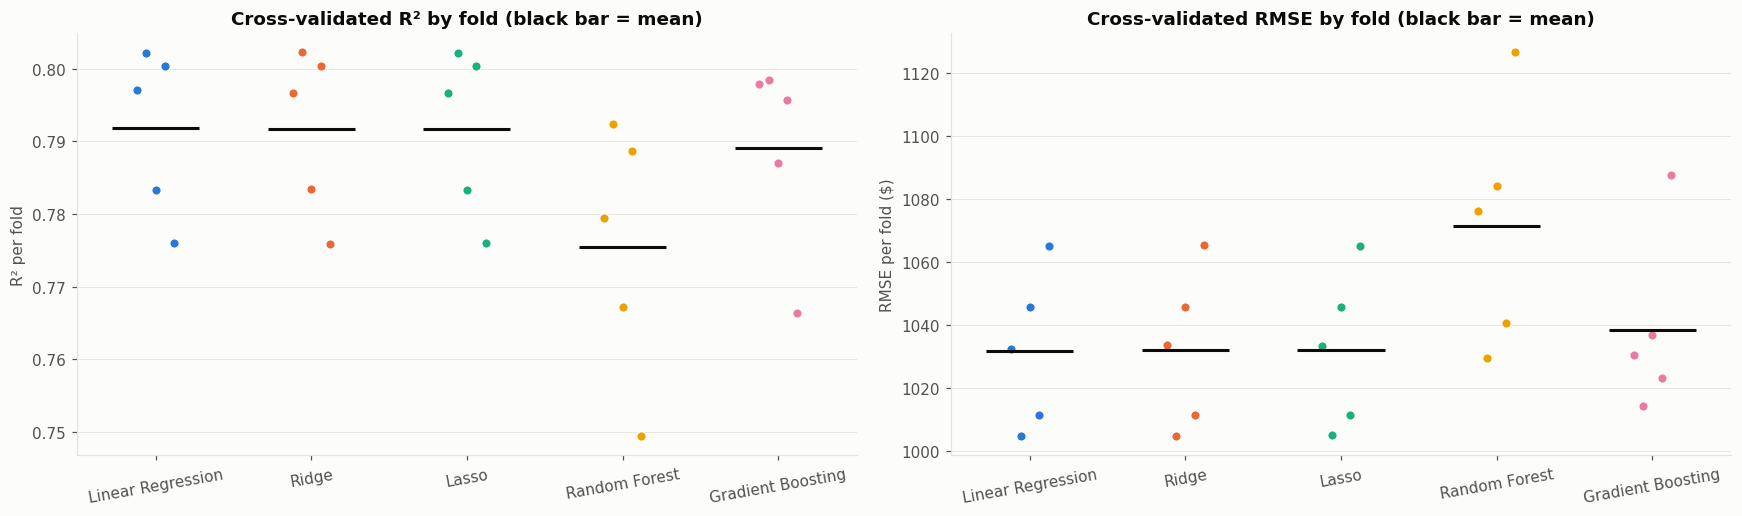

In [43]:
# ---------------------------------------------------------------
# 2.6.4 Fold-by-fold stability of each model (engineered features)
# ---------------------------------------------------------------
eng_folds = fold_results[fold_results["features"] == "Engineered"]
eng_cv = cv_results[cv_results["features"] == "Engineered"].set_index("model").reindex(MODEL_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, metric, label in [(axes[0], "R2", "R² per fold"), (axes[1], "RMSE", "RMSE per fold ($)")]:
    for i, name in enumerate(MODEL_NAMES):
        vals = eng_folds.loc[eng_folds["model"] == name, metric].values
        jitter = np.linspace(-0.12, 0.12, len(vals))
        ax.scatter(np.full(len(vals), i) + jitter, vals, s=40, color=MODEL_COLORS[name],
                   edgecolor=SURFACE, linewidth=1, zorder=3)
        ax.hlines(vals.mean(), i - 0.28, i + 0.28, color=INK, lw=2, zorder=4)
    ax.set_xticks(range(len(MODEL_NAMES)), MODEL_NAMES, rotation=10)
    ax.set_ylabel(label)
    ax.grid(axis="x", visible=False)
axes[0].set_title("Cross-validated R² by fold (black bar = mean)")
axes[1].set_title("Cross-validated RMSE by fold (black bar = mean)")
fig.tight_layout()
save(fig, "03_cv_fold_stability.png")
plt.show()

## 2.7 Hold-out Test Evaluation

Each model is now refit on the **full training set (engineered features)** and evaluated **once** on the untouched
20% test set. Agreement between CV scores and test scores shows the models generalise rather than overfit.

In [44]:
# ---------------------------------------------------------------
# 2.7.1 Fit on the training set, score on the test set
# ---------------------------------------------------------------
fitted, test_rows, test_preds = {}, [], {}
X_tr, X_te = X_eng.loc[idx_train], X_eng.loc[idx_test]
y_tr, y_te = y.loc[idx_train], y.loc[idx_test]

for name, model in make_models().items():
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    fitted[name], test_preds[name] = model, pred
    mse = mean_squared_error(y_te, pred)
    test_rows.append({
        "model": name,
        "Test R2": r2_score(y_te, pred),
        "Test MSE": mse,
        "Test RMSE $": np.sqrt(mse),
        "Test MAE $": mean_absolute_error(y_te, pred),
        "CV R2 (train)": eng_cv.loc[name, "R2_mean"],
        "Train R2": r2_score(y_tr, model.predict(X_tr)),
    })

test_results = pd.DataFrame(test_rows).set_index("model")
test_results["RMSE as % of mean revenue"] = test_results["Test RMSE $"] / y_te.mean() * 100
fmt = {"Test R2": "{:.4f}", "Test MSE": "{:,.0f}", "Test RMSE $": "{:,.1f}", "Test MAE $": "{:,.1f}",
       "CV R2 (train)": "{:.4f}", "Train R2": "{:.4f}", "RMSE as % of mean revenue": "{:.1f}%"}
# Format numbers as text for a readable table (best model = highest Test R2)
test_results.sort_values("Test R2", ascending=False).apply(
    lambda col: col.map(fmt[col.name].format))

,Test R2,Test MSE,Test RMSE $,Test MAE $,CV R2 (train),Train R2,RMSE as % of mean revenue
model,,,,,,,
Gradient Boosting,0.8010,"1,035,222","1,017.5",731.6,0.7891,0.8246,45.2%
Linear Regression,0.8001,"1,039,729","1,019.7",738.0,0.7918,0.7944,45.3%
Ridge,0.8001,"1,039,888","1,019.7",736.5,0.7917,0.7945,45.3%
Lasso,0.8000,"1,040,318","1,020.0",736.9,0.7917,0.7946,45.3%
Random Forest,0.7886,"1,100,043","1,048.8",740.2,0.7754,0.8768,46.6%


In [45]:
# ---------------------------------------------------------------
# 2.7.2 Regularisation strength chosen by Ridge and Lasso, and features Lasso removed
# ---------------------------------------------------------------
ridge = fitted["Ridge"][-1]
lasso = fitted["Lasso"][-1]
lasso_coef = pd.Series(lasso.coef_, index=X_eng.columns)
print(f"Ridge alpha chosen by CV : {ridge.alpha_:.4g}")
print(f"Lasso alpha chosen by CV : {lasso.alpha_:.4g}")
print(f"Lasso kept {int((lasso_coef != 0).sum())} of {len(lasso_coef)} features; "
      f"removed (coefficient = 0): {list(lasso_coef[lasso_coef == 0].index)}")

Ridge alpha chosen by CV : 5.012
Lasso alpha chosen by CV : 0.104
Lasso kept 28 of 32 features; removed (coefficient = 0): ['StreamingMovies_Yes', 'PaymentMethod_Electronic check', 'NumServices', 'ProtectionAddons']


## 2.8 Visual Comparison of Model Performance

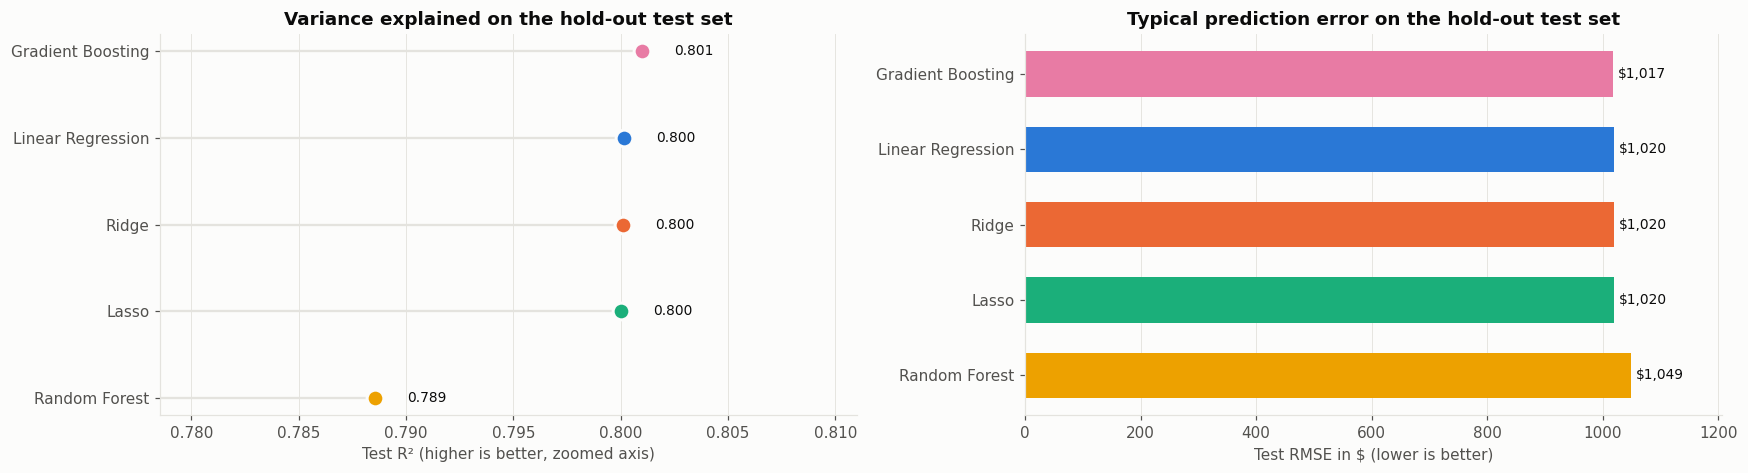

In [46]:
# ---------------------------------------------------------------
# 2.8.1 Test-set R^2 and RMSE side by side
# ---------------------------------------------------------------
order = test_results.sort_values("Test R2").index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4))

ax = axes[0]
# Dot plot (not bars) so a zoomed axis does not exaggerate differences
for i, m in enumerate(order):
    v = test_results.loc[m, "Test R2"]
    ax.hlines(i, test_results["Test R2"].min() - 0.01, v, color=GRID, lw=1.5, zorder=1)
    ax.scatter(v, i, s=120, color=MODEL_COLORS[m], edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.text(v + 0.0015, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_yticks(range(len(order)), order)
ax.set_xlim(test_results["Test R2"].min() - 0.01, test_results["Test R2"].max() + 0.01)
ax.set_xlabel("Test R² (higher is better, zoomed axis)")
ax.grid(axis="y", visible=False)
ax.set_title("Variance explained on the hold-out test set")

ax = axes[1]
ax.barh(order, test_results.loc[order, "Test RMSE $"], color=[MODEL_COLORS[m] for m in order], height=0.6)
for i, m in enumerate(order):
    v = test_results.loc[m, "Test RMSE $"]
    ax.text(v + 8, i, f"${v:,.0f}", va="center", fontsize=9)
ax.set_xlim(0, test_results["Test RMSE $"].max() * 1.15)
ax.set_xlabel("Test RMSE in $ (lower is better)")
ax.grid(axis="y", visible=False)
ax.set_title("Typical prediction error on the hold-out test set")

fig.tight_layout()
save(fig, "04_test_metrics_comparison.png")
plt.show()

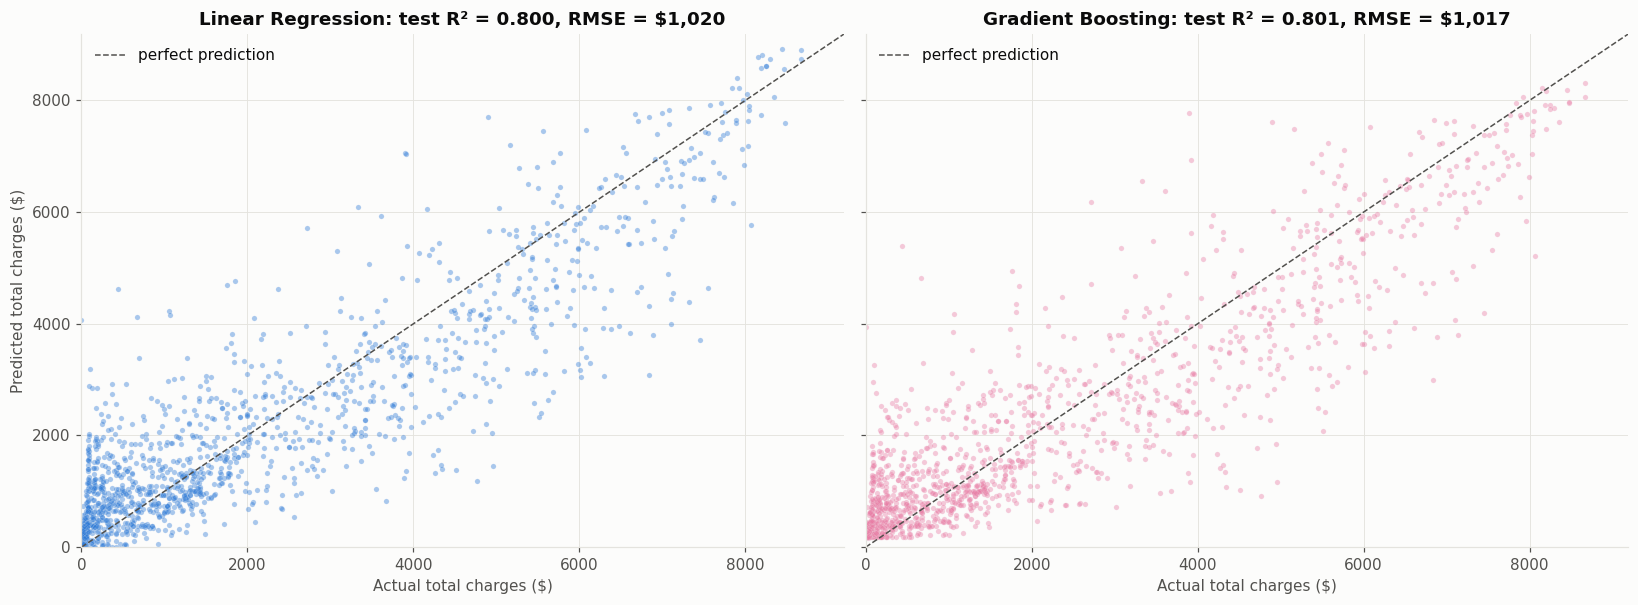

In [47]:
# ---------------------------------------------------------------
# 2.8.2 Predicted vs actual: best linear model vs best overall model
# ---------------------------------------------------------------
best_overall = test_results["Test R2"].idxmax()
linear_family = ["Linear Regression", "Ridge", "Lasso"]
best_linear = test_results.loc[linear_family, "Test R2"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), sharex=True, sharey=True)
lim = [0, max(y_te.max(), max(test_preds[best_overall].max(), test_preds[best_linear].max())) * 1.03]
for ax, name in zip(axes, [best_linear, best_overall]):
    ax.scatter(y_te, test_preds[name], s=12, alpha=0.4, color=MODEL_COLORS[name],
               edgecolor=SURFACE, linewidth=0.2)
    ax.plot(lim, lim, color=INK_2, ls="--", lw=1, label="perfect prediction")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel("Actual total charges ($)")
    ax.set_title(f"{name}: test R² = {test_results.loc[name, 'Test R2']:.3f}, "
                 f"RMSE = ${test_results.loc[name, 'Test RMSE $']:,.0f}")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted total charges ($)")
fig.tight_layout()
save(fig, "05_predicted_vs_actual.png")
plt.show()

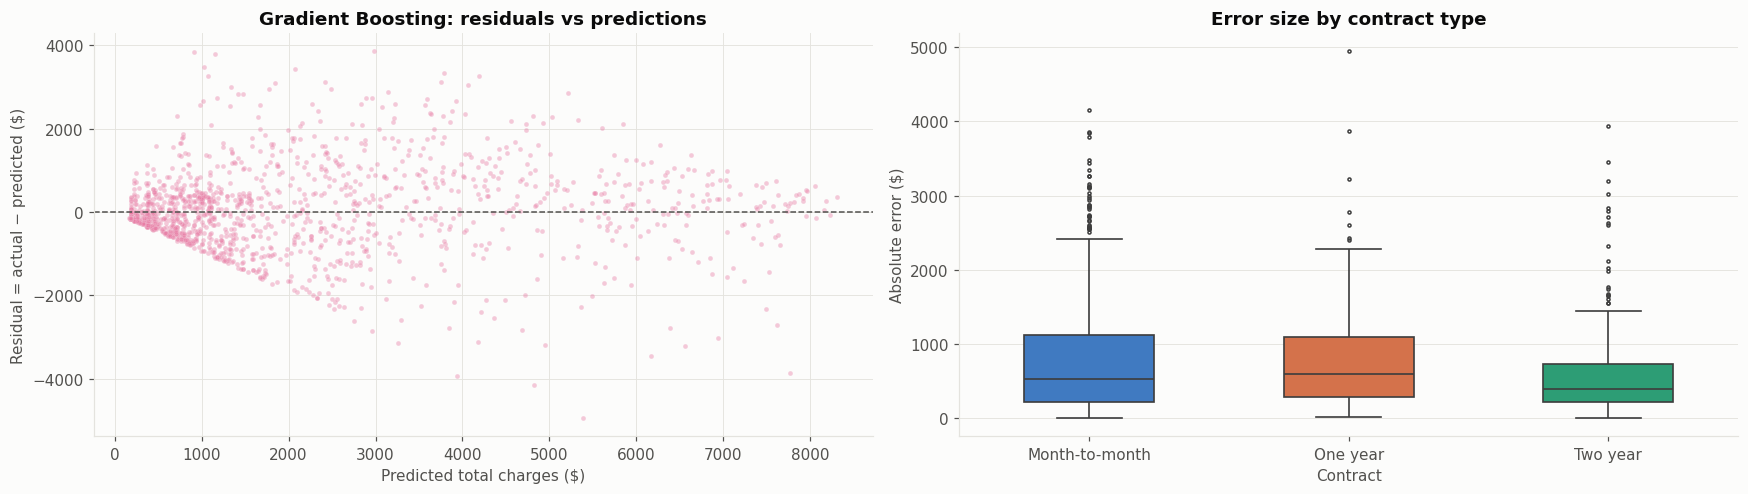

Mean absolute error by contract (test set):
Contract
Month-to-month    789.0
One year          788.0
Two year          562.0
Name: TotalCharges, dtype: float64


In [48]:
# ---------------------------------------------------------------
# 2.8.3 Residual analysis for the best model
# ---------------------------------------------------------------
resid = y_te - test_preds[best_overall]
contract_test = df.loc[idx_test, "Contract"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
ax = axes[0]
ax.scatter(test_preds[best_overall], resid, s=10, alpha=0.4, color=MODEL_COLORS[best_overall],
           edgecolor=SURFACE, linewidth=0.2)
ax.axhline(0, color=INK_2, ls="--", lw=1)
ax.set_xlabel("Predicted total charges ($)")
ax.set_ylabel("Residual = actual − predicted ($)")
ax.set_title(f"{best_overall}: residuals vs predictions")

ax = axes[1]
sns.boxplot(x=contract_test, y=resid.abs(), order=contract_order, hue=contract_test, hue_order=contract_order,
            palette=contract_colors, legend=False, width=0.5, fliersize=2, linewidth=1.1, ax=ax)
ax.set_xlabel("Contract")
ax.set_ylabel("Absolute error ($)")
ax.set_title("Error size by contract type")
fig.tight_layout()
save(fig, "06_residual_analysis.png")
plt.show()

print("Mean absolute error by contract (test set):")
print(resid.abs().groupby(contract_test).mean().reindex(contract_order).round(0))

## 2.9 Model Interpretation: What Drives Lifetime Revenue?

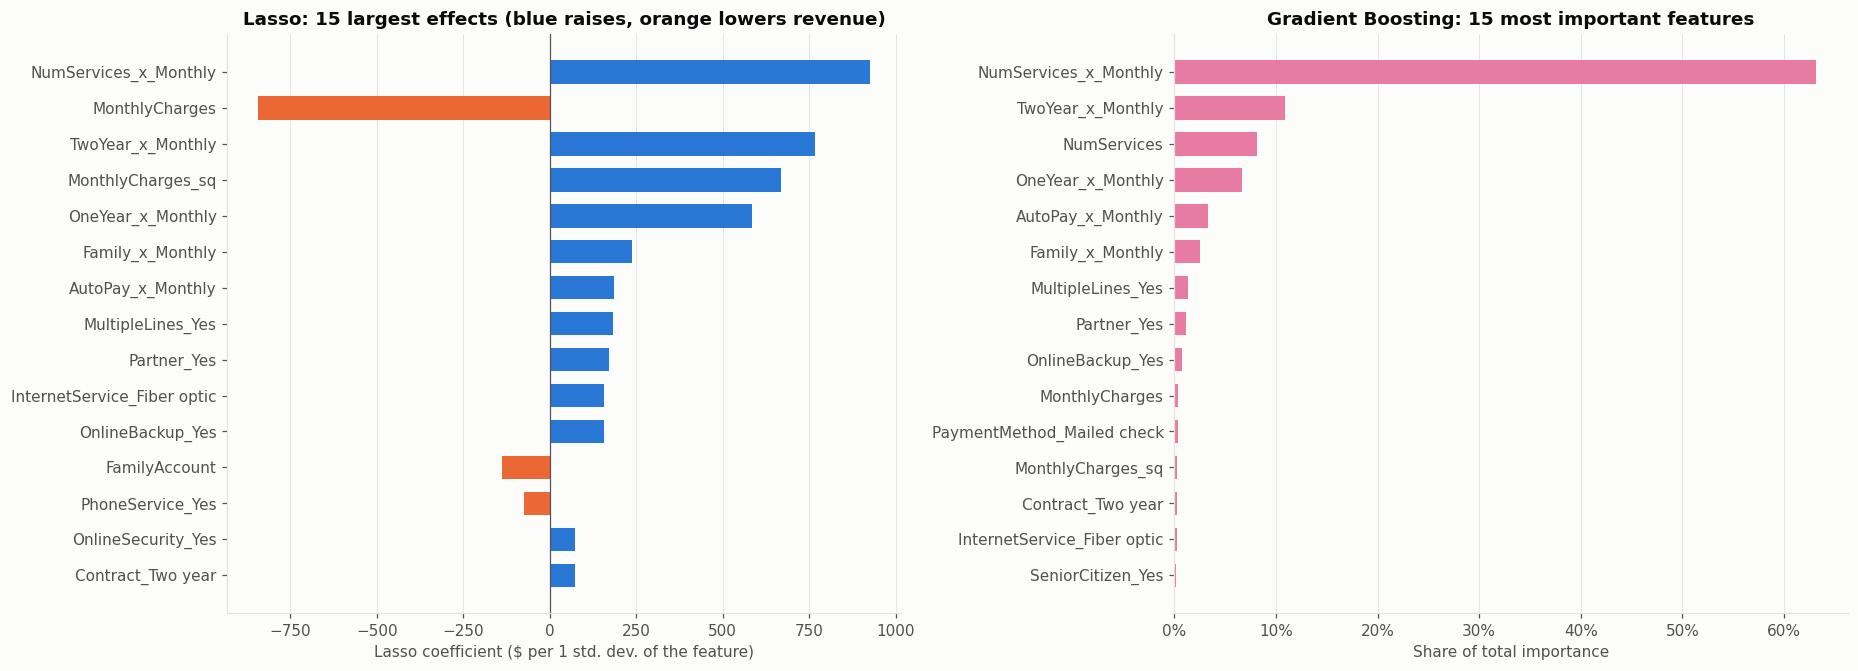

Top 8 Gradient Boosting features:
NumServices_x_Monthly    63.1%
TwoYear_x_Monthly        10.8%
NumServices               8.1%
OneYear_x_Monthly         6.6%
AutoPay_x_Monthly         3.3%
Family_x_Monthly          2.5%
MultipleLines_Yes         1.3%
Partner_Yes               1.1%
dtype: object


In [49]:
# ---------------------------------------------------------------
# 2.9.1 Lasso coefficients (standardised) and Gradient Boosting importances
# ---------------------------------------------------------------
gb = fitted["Gradient Boosting"][-1]
gb_imp = pd.Series(gb.feature_importances_, index=X_eng.columns).sort_values(ascending=False)
top_coef = lasso_coef[lasso_coef != 0].reindex(lasso_coef[lasso_coef != 0].abs().sort_values(ascending=False).index)[:15]

fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))
ax = axes[0]
tc = top_coef[::-1]
ax.barh(tc.index, tc.values, color=[CAT[0] if v > 0 else CAT[1] for v in tc.values], height=0.65)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_xlabel("Lasso coefficient ($ per 1 std. dev. of the feature)")
ax.grid(axis="y", visible=False)
ax.set_title("Lasso: 15 largest effects (blue raises, orange lowers revenue)")

ax = axes[1]
ti = gb_imp[:15][::-1]
ax.barh(ti.index, ti.values, color=MODEL_COLORS["Gradient Boosting"], height=0.65)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of total importance")
ax.grid(axis="y", visible=False)
ax.set_title("Gradient Boosting: 15 most important features")
fig.tight_layout()
save(fig, "07_feature_importance.png")
plt.show()

print("Top 8 Gradient Boosting features:")
print((gb_imp[:8] * 100).round(1).astype(str) + "%")

**Observations**

* Both models agree on the main drivers. The most important feature is **`NumServices × MonthlyCharges`**:
  customers who buy many services at a higher price are the ones who have stayed longest and generated the most
  revenue. Next come the **contract × price** interactions: a dollar of monthly price is worth far more on a one- or
  two-year contract than month-to-month.
* Lasso gives `MonthlyCharges` on its own a **negative** coefficient. This does **not** mean higher prices lower
  revenue. Price also appears in five interaction terms and a squared term, so its total effect is the sum of all of
  them (which is strongly positive). This is a textbook symptom of multicollinearity, and the reason we judge the models
  on predictions rather than on individual coefficients.
* Lasso set 4 features to exactly zero (`NumServices`, `ProtectionAddons`, `StreamingMovies_Yes`,
  `PaymentMethod_Electronic check`), because their information is already carried by the interaction terms and
  other features.
* Demographics (partner, senior citizen) add little once a customer's plan is known.

## 2.10 Summary of Results

### 2.10.1 Which model performed best?

| Model (engineered features) | 5-fold CV R² | Test R² | Test RMSE | Test MAE | Train R² |
|---|---|---|---|---|---|
| **Gradient Boosting** | 0.789 | **0.801** | **\$1,017.5** | **\$731.6** | 0.825 |
| **Ridge** | **0.792** | 0.800 | \$1,019.7 | \$736.5 | 0.795 |
| Lasso | 0.792 | 0.800 | \$1,020.0 | \$736.9 | 0.795 |
| Linear Regression | 0.792 | 0.800 | \$1,019.7 | \$738.0 | 0.794 |
| Random Forest | 0.775 | 0.789 | \$1,048.8 | \$740.2 | 0.877 |

* **Gradient Boosting** has the best test score, but only by **0.001 R² (about \$2 of RMSE)** over the engineered
  Ridge model — a practical tie.
* **Recommended model: Ridge regression on the engineered features.** It matches Gradient Boosting's accuracy, has
  the best cross-validated R², and its train, CV and test scores are almost identical (0.795 / 0.792 / 0.800), which
  shows it generalises without overfitting. It is also fast and explainable to business users.
* **Random Forest generalised worst:** train R² 0.877 vs test 0.789, the largest gap, i.e. some overfitting.

### 2.10.2 Key insights

1. **Feature engineering mattered more than the choice of algorithm.** Engineered features improved the linear models
   by +0.048 R² (−\$112 RMSE), while the top four models differ by less than 0.002 R².
2. **Contract length multiplies customer value.** Each \$1 of monthly price corresponds to about \$21 of lifetime
   revenue on month-to-month contracts, \$47 on one-year and \$61 on two-year contracts.
3. **Bundled customers are the most valuable.** Number of services × price is the strongest single predictor.
4. **Revenue is easiest to predict for two-year customers** (mean absolute error ≈ \$562 vs ≈ \$789 for the other
   contracts), because long contracts make the customer's future predictable.
5. **Remaining error is large (RMSE ≈ 45% of average revenue).** Lifetime revenue depends mostly on *how long* a
   customer stays, which plan and profile only partly reveal. That uncertainty is exactly what the churn model in
   Deliverable 3 addresses.
6. **Regularisation changed little here** (Ridge `alpha` ≈ 5, Lasso `alpha` ≈ 0.10) because the data has many more rows
   than features; its main value was confirming which engineered features are redundant.

## 2.11 Challenges Encountered and How They Were Addressed

| Challenge | How it was addressed |
|---|---|
| **The planned target was trivial.** `MonthlyCharges` is almost fully determined by the services bought (CV R² ≈ 0.999), so every model would tie. | Ran sanity checks before modelling and switched to a target with real uncertainty: lifetime revenue (`TotalCharges`). |
| **Target leakage.** `TotalCharges ≈ tenure × MonthlyCharges`, so including `tenure` gives R² ≈ 0.999 without learning anything useful. | Removed `tenure` and `tenure_group` from the predictors, and also `Churn` (an outcome, and Deliverable 3's target). |
| **A single price slope for every customer.** The EDA scatter showed revenue-per-dollar differs by contract, which a linear model cannot express. | Engineered interaction terms (`Contract × MonthlyCharges`, etc.) and count features; measured their effect with a raw-vs-engineered comparison. |
| **Multicollinearity** (one-hot dummies, price and service counts are correlated). | Used `drop_first` encoding and compared OLS with Ridge (L2) and Lasso (L1); regularisation strength was chosen automatically by internal cross-validation. |
| **Fair, honest evaluation.** | Locked a 20% test set away; all comparisons used 5-fold CV on the training data; scaling was fitted inside each pipeline so no test information leaked into training. |
| **Skewed target with large values** (many small totals, long tail up to ~\$8,700). | Reported RMSE alongside MAE and R², and examined residuals by contract to see where errors concentrate. |

## 2.12 Conclusion and Next Steps

We built and compared five regression models to estimate customer lifetime revenue from plan and profile data,
evaluated them with R², MSE, RMSE and MAE using 5-fold cross-validation and a hold-out test set, and showed that
**well-designed features let a simple, interpretable Ridge model match a Gradient Boosting ensemble (test R² ≈ 0.80)**.

**Practical use:** the predicted value of each customer can be combined with the churn probability from Deliverable 3
to estimate **revenue at risk** (value × probability of leaving), so retention offers go first to customers who are both
valuable and likely to leave.

**Next (Deliverable 3):** classification models for `Churn` with hyperparameter tuning, customer clustering, and
association rule mining.

---
# Part 3 – Classification, Clustering and Pattern Mining (Deliverable 3)

In [50]:
FIG_PREFIX = "p3_"     # figures from Part 3 are saved as Images/p3_*.png

### 3.0 Reload the cleaned data

In [51]:
# ---------------------------------------------------------------
# Reload the cleaned dataset written in Part 1 (a fresh copy for Part 3)
# ---------------------------------------------------------------
# The file is stored in this repository; if it is missing, the identical copy
# from the Deliverable 1 repository on GitHub is used instead.
DATA_PATH = "telco_churn_cleaned.csv"
DATA_URL = "https://raw.githubusercontent.com/pranavibalakulla/MSCS_634_Project_Deliverable_1/main/telco_churn_cleaned.csv"

source = DATA_PATH if os.path.exists(DATA_PATH) else DATA_URL
df = pd.read_csv(source)
print(f"Loaded from: {source}")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}   Missing values: {int(df.isna().sum().sum())}")
df.head(3)

Loaded from: telco_churn_cleaned.csv
Rows: 7,043   Columns: 24   Missing values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_flag,tenure_group,NumServices
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12,2
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,25-48,4
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12,4


## Part 3A – Classification: Predicting Customer Churn

**Goal:** predict `Churn` (Yes = the customer left) so the company can contact at-risk customers *before* they leave.

### 3A.1 Feature preparation

* **Removed:** `customerID` (identifier), `Churn` / `Churn_flag` (the target), `tenure_group` (duplicate of `tenure`),
  and `gender` and `PhoneService`, which Deliverable 1 showed have **no statistically significant association** with
  churn (Cramér's V ≈ 0.01, p > 0.3).
* **Encoding:** categorical columns are one-hot encoded (`drop_first=True`).
* **Scaling:** numeric columns are standardised **inside each model pipeline**, so scaling is learned from training
  folds only (no leakage). Scaling matters for distance- and gradient-based models (k-NN, Logistic Regression).
* **Class imbalance (≈ 73% stay / 27% churn):** we use a **stratified** split and stratified folds so every fold keeps
  the same churn rate, and `class_weight="balanced"` where the algorithm supports it.

In [52]:
# ---------------------------------------------------------------
# 3A.1 Build the feature matrix and target
# ---------------------------------------------------------------
drop_cols = ["customerID", "Churn", "Churn_flag", "tenure_group", "gender", "PhoneService"]
X = pd.get_dummies(df.drop(columns=drop_cols), drop_first=True, dtype=float)
y = df["Churn_flag"]

print(f"Features: {X.shape[1]}   Rows: {X.shape[0]:,}   Churn rate: {y.mean():.1%}")
list(X.columns)

Features: 22   Rows: 7,043   Churn rate: 26.5%


['tenure',
 'MonthlyCharges',
 'TotalCharges',
 'NumServices',
 'SeniorCitizen_Yes',
 'Partner_Yes',
 'Dependents_Yes',
 'MultipleLines_Yes',
 'InternetService_Fiber optic',
 'InternetService_No',
 'OnlineSecurity_Yes',
 'OnlineBackup_Yes',
 'DeviceProtection_Yes',
 'TechSupport_Yes',
 'StreamingTV_Yes',
 'StreamingMovies_Yes',
 'Contract_One year',
 'Contract_Two year',
 'PaperlessBilling_Yes',
 'PaymentMethod_Credit card (automatic)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mailed check']

In [53]:
# ---------------------------------------------------------------
# 3A.2 Stratified 80/20 train/test split
# ---------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,} rows (churn {y_train.mean():.1%})   "
      f"Test: {len(X_test):,} rows (churn {y_test.mean():.1%})")

Train: 5,634 rows (churn 26.5%)   Test: 1,409 rows (churn 26.5%)


### 3A.2 Classification models

| Model | Why it is included | Settings |
|---|---|---|
| **Logistic Regression** | Interpretable linear baseline that outputs probabilities | `class_weight="balanced"` |
| **Decision Tree (default)** | Human-readable rules; shown *before* tuning to demonstrate overfitting | scikit-learn defaults (grows until leaves are pure) |
| **k-Nearest Neighbours** | Instance-based: a customer looks like their nearest neighbours | `k = 25` (a larger *k* smooths out noise on 5,600 training rows) |
| **Naïve Bayes** | Fast probabilistic model; assumes independent features | `GaussianNB` |
| **Random Forest** | Ensemble of trees; robust to noise and interactions | 300 trees, `min_samples_leaf=5`, `class_weight="balanced"` |
| **Decision Tree (tuned)** | Same algorithm after **GridSearchCV** (Section A.3) | best parameters from the search |

In [54]:
# ---------------------------------------------------------------
# 3A.3 Define the models (each in a pipeline with standardisation)
# ---------------------------------------------------------------
base_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
    "Decision Tree (default)": make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "k-NN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
    "Naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)),
}

# Fixed colour per model in every chart (orange is reserved for "churned")
MODEL_COLORS = {"Logistic Regression": CAT[0], "Decision Tree (default)": MUTED,
                "Decision Tree (tuned)": CAT[2], "k-NN": CAT[3], "Naive Bayes": CAT[4],
                "Random Forest": CAT[5]}

# 5-fold stratified cross-validation on the TRAINING set
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in base_models.items():
    res = cross_validate(model, X_train, y_train, cv=skf, scoring=["accuracy", "f1", "roc_auc"])
    cv_rows.append({"model": name,
                    "CV accuracy": res["test_accuracy"].mean(),
                    "CV F1": res["test_f1"].mean(), "CV F1 std": res["test_f1"].std(),
                    "CV ROC-AUC": res["test_roc_auc"].mean()})
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.round(4)

,CV accuracy,CV F1,CV F1 std,CV ROC-AUC
model,,,,
Logistic Regression,0.7496,0.6294,0.0225,0.8462
Decision Tree (default),0.7284,0.4920,0.0135,0.6557
k-NN,0.7874,0.5839,0.0165,0.8258
Naive Bayes,0.7485,0.6203,0.0166,0.8312
Random Forest,0.7774,0.6326,0.0247,0.8433


### 3A.3 Hyperparameter tuning – Decision Tree with GridSearchCV

**Technique:** an exhaustive **grid search** with **5-fold stratified cross-validation** (`GridSearchCV`). Every
combination of the parameters below is trained on 4 folds and scored on the 5th; the combination with the best average
score is selected and refit on the full training set.

**Why tune the Decision Tree?** The default tree grows until every leaf is pure, which memorises the training data
(overfitting). Its parameters directly control model complexity, and a tuned tree stays readable, so the business can
see *why* a customer is flagged.

| Parameter | Values searched | What it controls |
|---|---|---|
| `max_depth` | 2, 3, 4, 5, 6, 7, 8, 10, 12, None | Maximum number of questions from root to leaf (complexity) |
| `min_samples_leaf` | 1, 5, 10, 20, 40, 80 | Minimum customers in a leaf; larger = smoother, less noise-fitting |
| `criterion` | gini, entropy | How split quality is measured |
| `class_weight` | None, balanced | Whether churners are up-weighted to offset the 73/27 imbalance |

**Scoring metric: F1 for the churn class.** Accuracy is misleading on imbalanced data (predicting "no churn" for
everyone already gives 73%). F1 balances **precision** (how many flagged customers really churn) and **recall** (how
many churners we catch). That is 10 × 6 × 2 × 2 = **240 combinations × 5 folds = 1,200 fits**.

In [55]:
# ---------------------------------------------------------------
# 3A.4 Grid search
# ---------------------------------------------------------------
param_grid = {
    "max_depth": [2, 3, 4, 5, 6, 7, 8, 10, 12, None],
    "min_samples_leaf": [1, 5, 10, 20, 40, 80],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"],
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
                    scoring="f1", cv=skf, n_jobs=-1, return_train_score=True)
start = time.time()
grid.fit(X_train, y_train)
print(f"Grid search finished in {time.time() - start:.1f} s ({len(grid.cv_results_['params'])} combinations x 5 folds)")
print("Best parameters :", grid.best_params_)
print(f"Best CV F1      : {grid.best_score_:.4f}")

# CV score of the default tree, for comparison
print(f"Default tree CV F1: {cv_table.loc['Decision Tree (default)', 'CV F1']:.4f}")

Grid search finished in 15.0 s (240 combinations x 5 folds)
Best parameters : {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 40}
Best CV F1      : 0.6167
Default tree CV F1: 0.4920


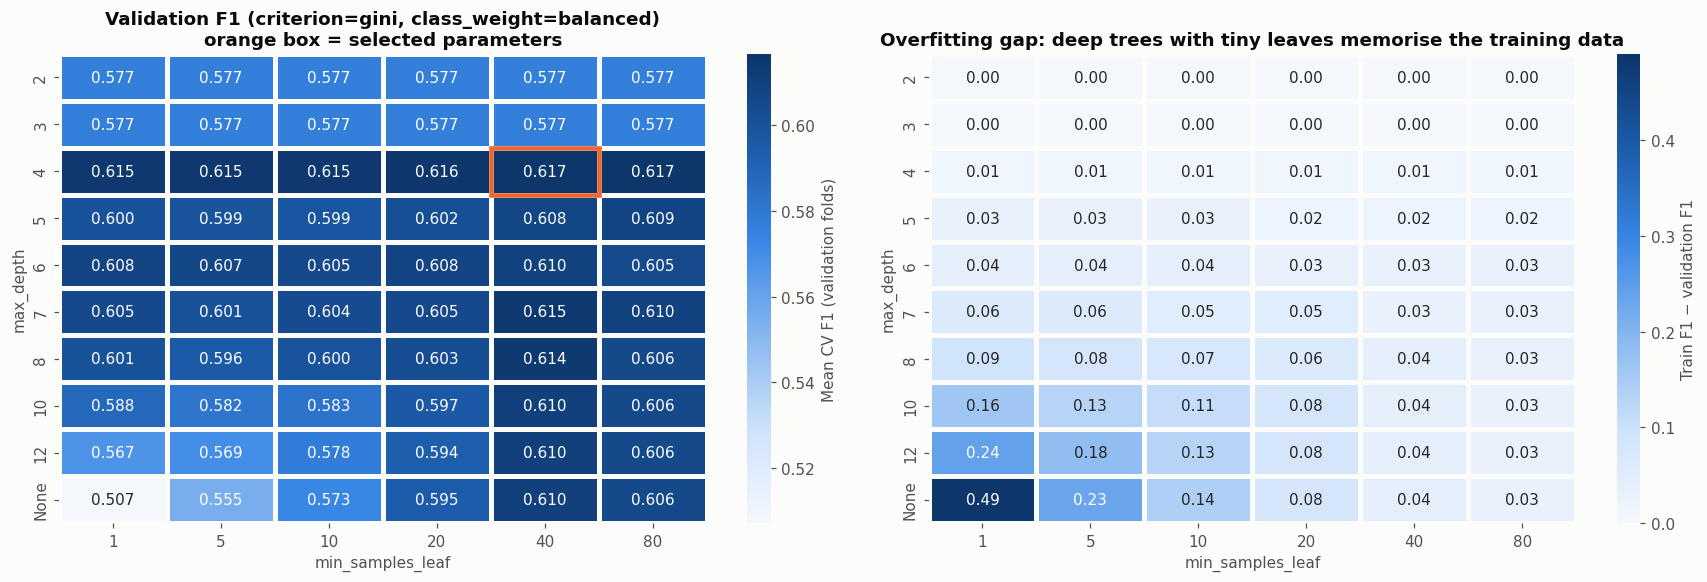

In [56]:
# ---------------------------------------------------------------
# 3A.5 Visualise the search: CV F1 for every max_depth x min_samples_leaf
#     (using the best criterion and class_weight)
# ---------------------------------------------------------------
cvr = pd.DataFrame(grid.cv_results_)
best = grid.best_params_
as_label = lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v)
mask = (cvr["param_criterion"] == best["criterion"]) & \
       (cvr["param_class_weight"].map(as_label) == as_label(best["class_weight"]))
sub = cvr[mask].copy()
sub["max_depth"] = sub["param_max_depth"].map(lambda v: as_label(v if v is None or pd.isna(v) else int(v)))
sub["min_samples_leaf"] = sub["param_min_samples_leaf"].astype(int)
depth_order = [str(d) for d in param_grid["max_depth"]]
heat = sub.pivot(index="max_depth", columns="min_samples_leaf", values="mean_test_score").reindex(depth_order)
gap = sub.pivot(index="max_depth", columns="min_samples_leaf", values="mean_train_score").reindex(depth_order) - heat
gap = gap.round(2) + 0.0          # + 0.0 turns "-0.00" into "0.00" for display

fig, axes = plt.subplots(1, 2, figsize=(16, 5.4))
sns.heatmap(heat, annot=True, fmt=".3f", cmap=SEQ_BLUE, linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "Mean CV F1 (validation folds)"}, ax=axes[0])
r = depth_order.index(str(best["max_depth"]))
c = list(heat.columns).index(best["min_samples_leaf"])
axes[0].add_patch(plt.Rectangle((c, r), 1, 1, fill=False, edgecolor=CAT[1], lw=3))
axes[0].set_title(f"Validation F1 (criterion={best['criterion']}, class_weight={best['class_weight']})"
                  "\norange box = selected parameters")
axes[0].grid(False)

sns.heatmap(gap, annot=True, fmt=".2f", cmap=SEQ_BLUE, linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "Train F1 − validation F1"}, ax=axes[1])
axes[1].set_title("Overfitting gap: deep trees with tiny leaves memorise the training data")
axes[1].grid(False)
for ax in axes:
    ax.set_ylabel("max_depth")
    ax.set_xlabel("min_samples_leaf")
fig.tight_layout()
save(fig, "01_hyperparameter_tuning_heatmap.png")
plt.show()

**Explaining the chosen parameters**

| Parameter | Chosen value | Why (from the heatmaps) |
|---|---|---|
| `max_depth` | **4** | Depths 2–3 are too simple (CV F1 0.577 – **underfitting**). Depth 4 gives the best validation F1 (**0.617**). Deeper trees score no better on validation folds while the train–validation gap keeps growing — up to **0.49** for an unlimited tree with 1-customer leaves, which is the default setting (**overfitting**). |
| `min_samples_leaf` | **40** | At depth 4 all leaf sizes are close, and 40 scores best. Larger leaves also protect deeper trees from memorising noise (the right-hand columns stay stable). Each final rule is based on at least 40 customers. |
| `criterion` | **gini** | Gini and entropy gave near-identical results; gini scored slightly higher. |
| `class_weight` | **balanced** | Up-weights churners so the tree does not ignore the minority class, raising recall. |

**Effect of tuning:** cross-validated F1 rose from **0.492** (default tree) to **0.617** (+0.125). On the test set (Section A.4)
F1 rises from 0.499 to 0.621, recall from 51% to 78%, and ROC-AUC from 0.659 to 0.816. Training F1 fell from 0.996 to 0.621,
so the tuned tree no longer memorises the training data.

The tuned tree is also easy to explain: its first questions are **"Two-year contract?" → "One-year contract?" → "Fiber
optic internet?"** Contract type alone accounts for about 71% of the tree's importance, followed by fiber optic (12%)
and tenure (10%). (Because of class balancing, the root node shows a 50/50 split.)

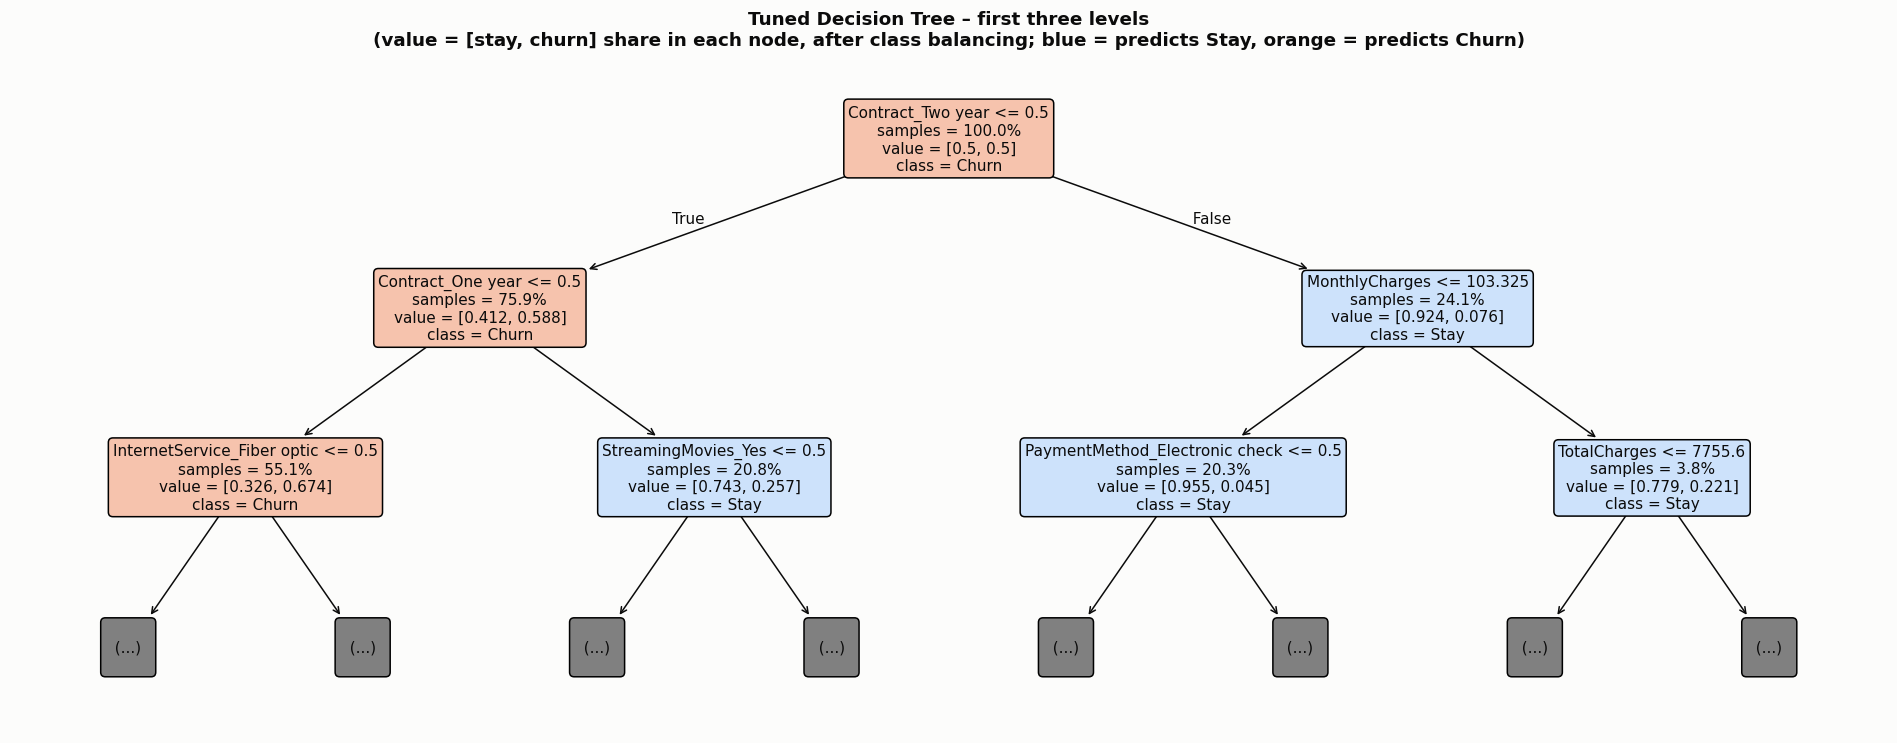

Top 8 features used by the tuned tree:
Contract_Two year                 43.5%
Contract_One year                 27.2%
InternetService_Fiber optic       12.0%
tenure                            10.1%
StreamingMovies_Yes                3.7%
MonthlyCharges                     1.7%
TotalCharges                       1.1%
PaymentMethod_Electronic check     0.8%
dtype: object


In [57]:
# ---------------------------------------------------------------
# 3A.6 The tuned tree's top levels (readable churn rules)
# ---------------------------------------------------------------
tuned_tree = grid.best_estimator_
fig, ax = plt.subplots(figsize=(22, 8))
nodes = plot_tree(tuned_tree, max_depth=2, feature_names=list(X.columns), class_names=["Stay", "Churn"],
                  filled=True, rounded=True, impurity=False, proportion=True, fontsize=10, ax=ax)
# Recolour nodes to match the rest of the project: blue = predicted Stay, orange = predicted Churn
for node in nodes:
    box = node.get_bbox_patch()
    if box is not None and "class = Churn" in node.get_text():
        box.set_facecolor("#f6c3ad")
    elif box is not None and "class = Stay" in node.get_text():
        box.set_facecolor("#cde2fb")
ax.set_title("Tuned Decision Tree – first three levels\n(value = [stay, churn] share in each node, after class balancing; "
             "blue = predicts Stay, orange = predicts Churn)")
save(fig, "02_tuned_tree_top_levels.png")
plt.show()

imp = pd.Series(tuned_tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 8 features used by the tuned tree:")
print((imp[:8] * 100).round(1).astype(str) + "%")

### 3A.4 Test-set evaluation: accuracy, precision, recall, F1 and ROC-AUC

All six models are fitted on the full training set and evaluated once on the untouched, stratified test set.

In [58]:
# ---------------------------------------------------------------
# 3A.7 Fit every model and score it on the test set
# ---------------------------------------------------------------
final_models = dict(base_models)
final_models["Decision Tree (tuned)"] = make_pipeline(StandardScaler(), DecisionTreeClassifier(
    random_state=RANDOM_STATE, **grid.best_params_))
MODEL_ORDER = ["Logistic Regression", "Decision Tree (default)", "Decision Tree (tuned)",
               "k-NN", "Naive Bayes", "Random Forest"]

rows, probas, preds = [], {}, {}
for name in MODEL_ORDER:
    model = final_models[name].fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    yhat = (p >= 0.5).astype(int)
    probas[name], preds[name] = p, yhat
    rows.append({"model": name,
                 "Accuracy": accuracy_score(y_test, yhat),
                 "Precision": precision_score(y_test, yhat),
                 "Recall": recall_score(y_test, yhat),
                 "F1": f1_score(y_test, yhat),
                 "ROC-AUC": roc_auc_score(y_test, p),
                 "Train F1": f1_score(y_train, model.predict(X_train))})
results = pd.DataFrame(rows).set_index("model")
results.sort_values("F1", ascending=False).round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,Train F1
model,,,,,,
Random Forest,0.7764,0.5601,0.7353,0.6358,0.8432,0.7588
Decision Tree (tuned),0.7459,0.5140,0.7834,0.6208,0.8159,0.6212
Logistic Regression,0.7374,0.5034,0.7834,0.6130,0.8415,0.6338
Naive Bayes,0.7381,0.5045,0.7513,0.6037,0.8229,0.6212
k-NN,0.7757,0.5806,0.5588,0.5695,0.8154,0.6148
Decision Tree (default),0.7310,0.4935,0.5053,0.4993,0.6594,0.9956


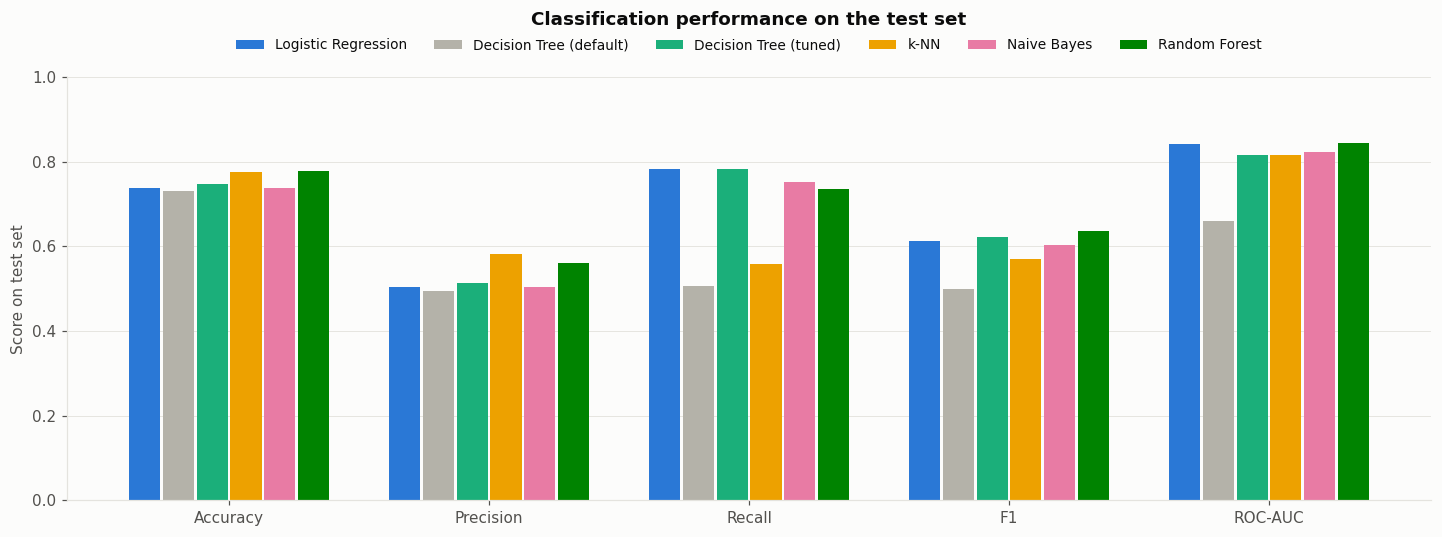

In [59]:
# ---------------------------------------------------------------
# 3A.8 Visual comparison of the test metrics
# ---------------------------------------------------------------
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
fig, ax = plt.subplots(figsize=(16, 5))
w = 0.13
x = np.arange(len(metrics))
for i, name in enumerate(MODEL_ORDER):
    vals = results.loc[name, metrics].values
    ax.bar(x + (i - 2.5) * w, vals, width=w * 0.92, color=MODEL_COLORS[name], label=name)
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score on test set")
ax.grid(axis="x", visible=False)
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.12), fontsize=9)
ax.set_title("Classification performance on the test set", pad=34)
save(fig, "03_classification_metrics.png")
plt.show()

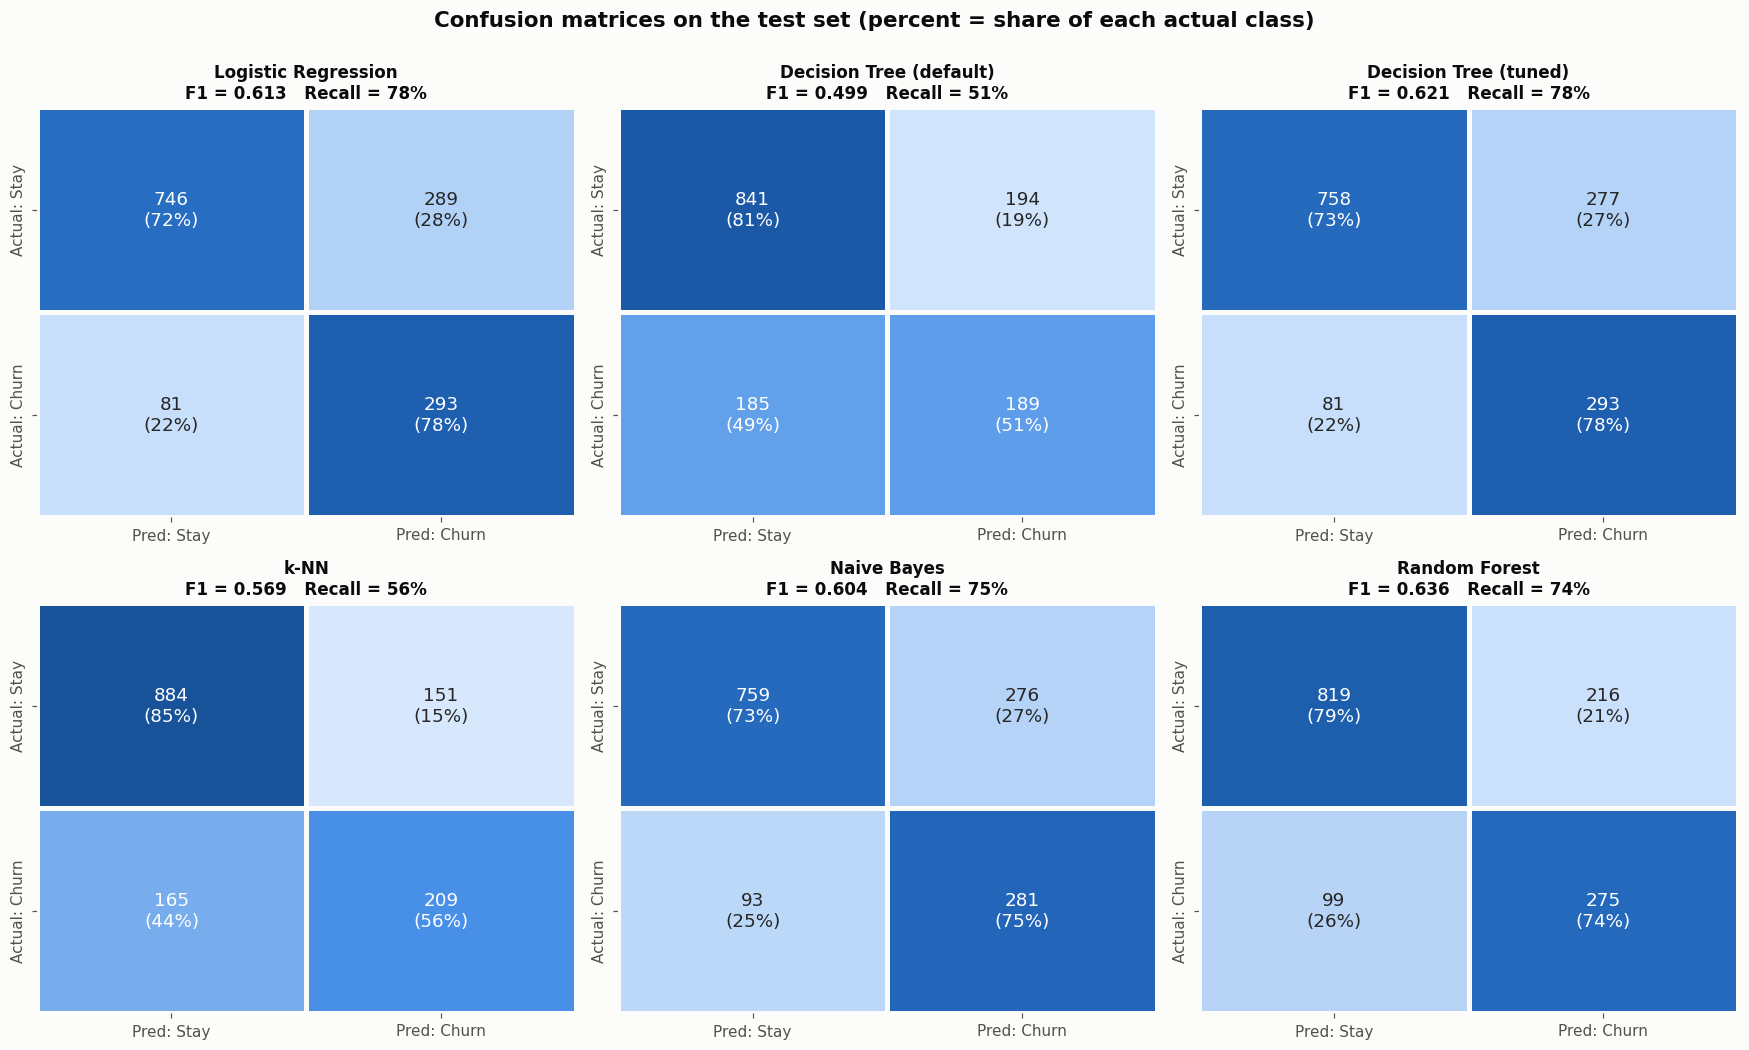

In [60]:
# ---------------------------------------------------------------
# 3A.9 Confusion matrices (counts and % of each actual class)
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for ax, name in zip(axes.flat, MODEL_ORDER):
    cm = confusion_matrix(y_test, preds[name])
    pct = cm / cm.sum(axis=1, keepdims=True)
    labels = np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.0%})" for j in range(2)] for i in range(2)])
    sns.heatmap(pct, annot=labels, fmt="", cmap=SEQ_BLUE, vmin=0, vmax=1, cbar=False,
                linewidths=2, linecolor=SURFACE, annot_kws={"size": 12}, ax=ax,
                xticklabels=["Pred: Stay", "Pred: Churn"], yticklabels=["Actual: Stay", "Actual: Churn"])
    ax.set_title(f"{name}\nF1 = {results.loc[name, 'F1']:.3f}   Recall = {results.loc[name, 'Recall']:.0%}",
                 fontsize=11)
    ax.grid(False)
fig.suptitle("Confusion matrices on the test set (percent = share of each actual class)",
             fontsize=14, fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "04_confusion_matrices.png")
plt.show()

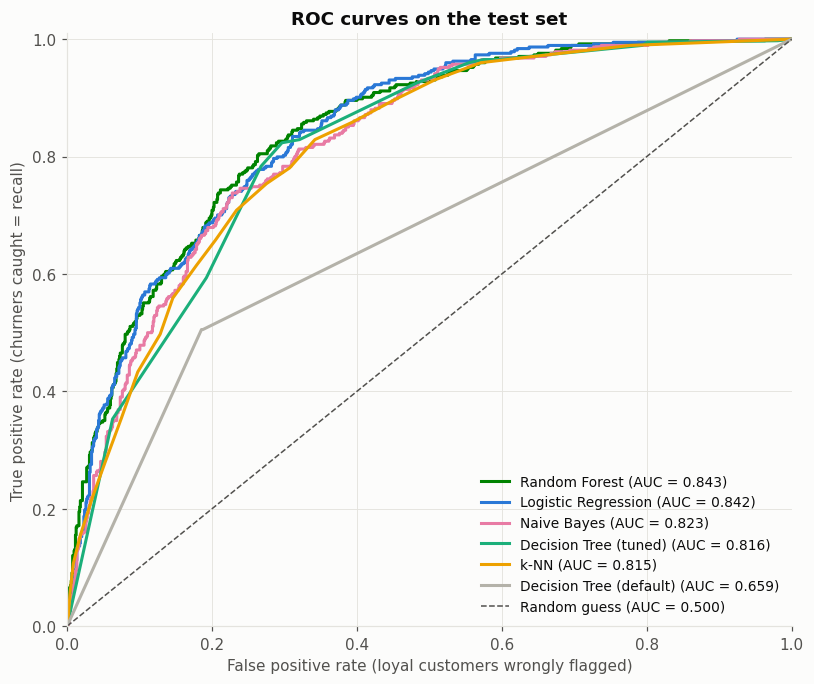

In [61]:
# ---------------------------------------------------------------
# 3A.10 ROC curves
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 7))
for name in sorted(MODEL_ORDER, key=lambda n: -results.loc[n, "ROC-AUC"]):
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    ax.plot(fpr, tpr, lw=2, color=MODEL_COLORS[name], label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color=INK_2, lw=1, label="Random guess (AUC = 0.500)")
ax.set_xlabel("False positive rate (loyal customers wrongly flagged)")
ax.set_ylabel("True positive rate (churners caught = recall)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
save(fig, "05_roc_curves.png")
plt.show()

### 3A.5 Classification insights

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **Random Forest** | **0.776** | 0.560 | 0.735 | **0.636** | **0.843** |
| Decision Tree (tuned) | 0.746 | 0.514 | **0.783** | 0.621 | 0.816 |
| Logistic Regression | 0.737 | 0.503 | **0.783** | 0.613 | 0.842 |
| Naive Bayes | 0.738 | 0.505 | 0.751 | 0.604 | 0.823 |
| k-NN | 0.776 | **0.581** | 0.559 | 0.570 | 0.815 |
| Decision Tree (default) | 0.731 | 0.494 | 0.505 | 0.499 | 0.659 |

* **Best model: Random Forest** — highest F1 (0.636), ROC-AUC (0.843) and accuracy (0.776). It catches **74% of
  churners** (275 of 374 in the test set) while keeping the best balance with precision.
* **Logistic Regression is almost as good** (ROC-AUC 0.842, recall 78%) and is fully interpretable, which makes it a
  strong, simple alternative.
* **Hyperparameter tuning turned the weakest model into one of the best:** the tuned Decision Tree catches 293 of 374
  churners (78%) with an F1 of 0.621, versus 0.499 for the default tree.
* **Accuracy is misleading here.** k-NN ties Random Forest on accuracy (0.776) but misses **44% of churners**
  (165 of 374), because it cannot use class weights and leans towards the majority class. That is why F1, recall and
  ROC-AUC were used to choose models.
* **Naïve Bayes** performs reasonably (F1 0.604) even though its independence assumption is violated (contract,
  tenure and charges are correlated).
* **Precision–recall trade-off:** the class-weighted models flag roughly 490–580 customers to catch 275–293 churners
  (precision 0.50–0.56), so about **one in two flagged customers really churns**. For a retention campaign (a call or a small discount) that is
  usually a good trade. The ROC curves show how the threshold can be moved if contacts are more expensive.
* The strongest predictors — **contract type, fiber-optic internet and tenure** — match what the EDA in Deliverable 1
  found.

*Note: Random Forest uses random sampling internally, so its exact scores can differ slightly between scikit-learn
versions (we observed F1 between 0.63 and 0.64). The ranking of the models and the conclusions do not change.*

## Part 3B – Clustering: Customer Segmentation with K-Means

**Goal:** find natural customer groups **without using the churn label**, then check how churn differs between groups.

**Features used:** `tenure` (loyalty), `MonthlyCharges` (spend) and `NumServices` (how many services the customer
uses). These three describe *relationship length, value and engagement*, and are all numeric, which suits K-Means'
distance-based approach. They are **standardised** first, otherwise `MonthlyCharges` (range ≈ 18–119) would dominate
`NumServices` (range 1–9).

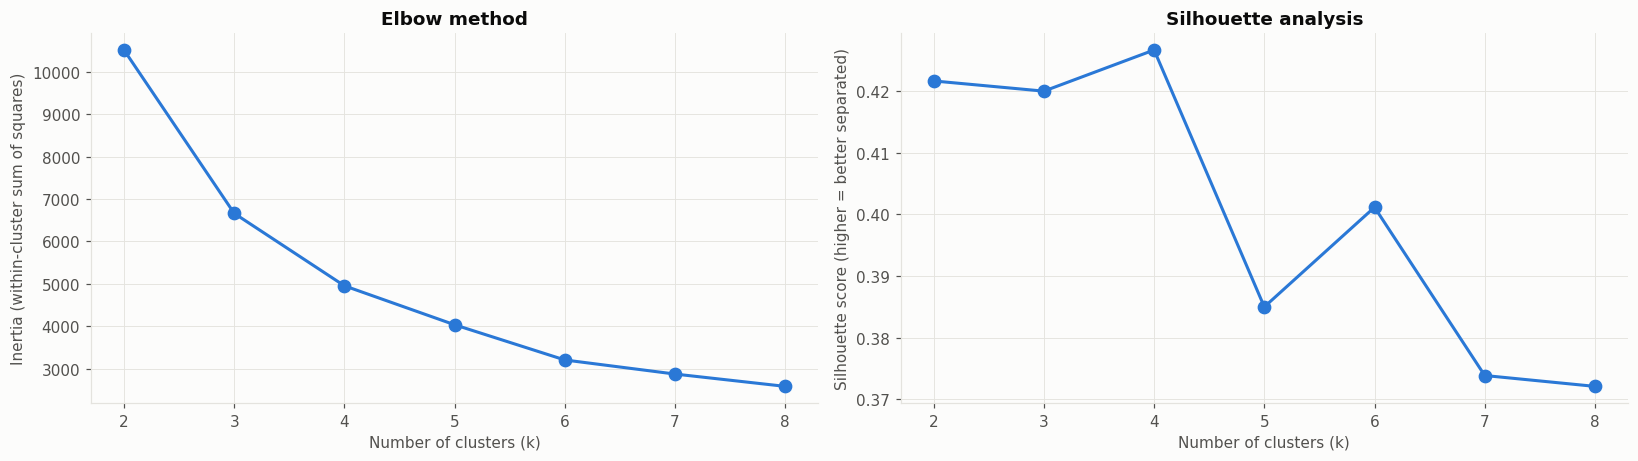

k,2,3,4,5,6,7,8
inertia,10513.0000,6663.00,4956.0000,4038.000,3208.0000,2876.0000,2586.0000
silhouette,0.4216,0.42,0.4267,0.385,0.4012,0.3739,0.3721


In [62]:
# ---------------------------------------------------------------
# 3B.1 Prepare and scale the clustering features
# ---------------------------------------------------------------
cluster_features = ["tenure", "MonthlyCharges", "NumServices"]
Xc = StandardScaler().fit_transform(df[cluster_features])

# ---------------------------------------------------------------
# 3B.2 Choose k: elbow (inertia) and silhouette score for k = 2..8
# ---------------------------------------------------------------
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(Xc, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
axes[0].plot(list(ks), inertia, marker="o", ms=8, lw=2, color=CAT[0])
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].set_title("Elbow method")
axes[1].plot(list(ks), silhouette, marker="o", ms=8, lw=2, color=CAT[0])
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score (higher = better separated)")
axes[1].set_title("Silhouette analysis")
for ax in axes:
    ax.set_xticks(list(ks))
fig.tight_layout()
save(fig, "06_choosing_k.png")
plt.show()

pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 0), "silhouette": np.round(silhouette, 4)}).set_index("k").T

**Choosing k = 4**

* The **silhouette score is highest at k = 4 (0.427)**, ahead of k = 2 (0.422) and k = 3 (0.420), and drops sharply at
  k = 5 (0.385).
* The **elbow curve** bends around k = 3–4: inertia falls by 37% from k = 2 to 3 and by 26% from 3 to 4, after which each
  extra cluster gives smaller gains.
* **k = 4 is also the most interpretable**: the groups split customers into *new vs loyal* and *low vs high spend*,
  which a marketing team can act on directly.

A silhouette of ≈ 0.43 means moderate but real structure. Customer data is continuous, so groups shade into each other
rather than being perfectly separated.

In [63]:
# ---------------------------------------------------------------
# 3B.3 Fit the final K-Means model
# ---------------------------------------------------------------
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Xc)

# K-Means numbers clusters arbitrarily (cluster "0" can differ between runs or library versions).
# So each cluster is NAMED from its own centre: is its average tenure above the overall median
# (new vs loyal), and is its average monthly charge above the overall median (low vs high spend)?
df["Cluster"] = kmeans.labels_
centres = df.groupby("Cluster")[cluster_features].mean()
NAME_BY_PROFILE = {
    (False, False): "New, basic plan",
    (False, True): "New, high spend",
    (True, False): "Loyal, low cost",
    (True, True): "Loyal, premium bundle",
}
CLUSTER_NAMES = {cid: NAME_BY_PROFILE[(row["tenure"] > df["tenure"].median(),
                                       row["MonthlyCharges"] > df["MonthlyCharges"].median())]
                 for cid, row in centres.iterrows()}
assert len(set(CLUSTER_NAMES.values())) == K, "Two clusters received the same profile name"
df["Segment"] = df["Cluster"].map(CLUSTER_NAMES)
SEG_ORDER = list(NAME_BY_PROFILE.values())
SEG_COLORS = dict(zip(SEG_ORDER, [CAT[0], CAT[4], CAT[2], CAT[5]]))
centres.index = centres.index.map(CLUSTER_NAMES)
centres.reindex(SEG_ORDER).round(1)

print(f"Silhouette score for k = {K}: {silhouette_score(Xc, df['Cluster']):.3f}")
print(df["Segment"].value_counts().reindex(SEG_ORDER).to_string())

Silhouette score for k = 4: 0.427
Segment
New, basic plan          1509
New, high spend          2410
Loyal, low cost           972
Loyal, premium bundle    2152


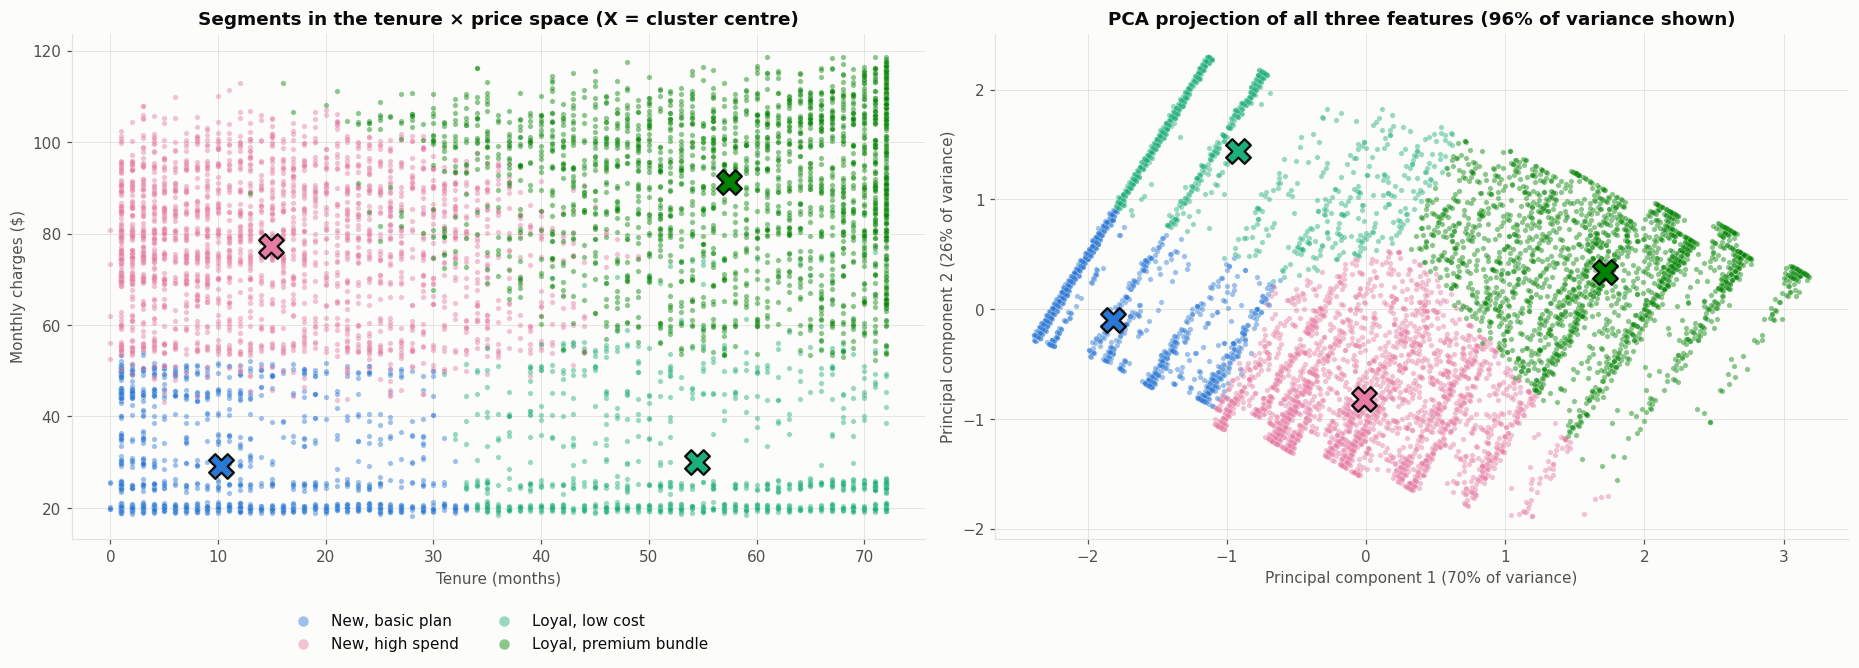

In [64]:
# ---------------------------------------------------------------
# 3B.4 Visualise the clusters
# ---------------------------------------------------------------
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xc)
pcs = pca.transform(Xc)
centers_pc = pca.transform(kmeans.cluster_centers_)
centers_raw = df.groupby("Segment")[cluster_features].mean()

fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))
ax = axes[0]
for seg in SEG_ORDER:
    m = df["Segment"] == seg
    ax.scatter(df.loc[m, "tenure"], df.loc[m, "MonthlyCharges"], s=12, alpha=0.45,
               color=SEG_COLORS[seg], edgecolor=SURFACE, linewidth=0.2, label=seg)
for seg, row in centers_raw.iterrows():
    ax.scatter(row["tenure"], row["MonthlyCharges"], s=260, marker="X", color=SEG_COLORS[seg],
               edgecolor=INK, linewidth=1.5, zorder=5)
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Monthly charges ($)")
ax.set_title("Segments in the tenure × price space (X = cluster centre)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, markerscale=2)

ax = axes[1]
for seg in SEG_ORDER:
    m = (df["Segment"] == seg).values
    ax.scatter(pcs[m, 0], pcs[m, 1], s=12, alpha=0.45, color=SEG_COLORS[seg], edgecolor=SURFACE, linewidth=0.2)
for cid in range(K):
    cpc = centers_pc[cid]
    ax.scatter(cpc[0], cpc[1], s=260, marker="X", color=SEG_COLORS[CLUSTER_NAMES[cid]],
               edgecolor=INK, linewidth=1.5, zorder=5)
ev = pca.explained_variance_ratio_
ax.set_xlabel(f"Principal component 1 ({ev[0]:.0%} of variance)")
ax.set_ylabel(f"Principal component 2 ({ev[1]:.0%} of variance)")
ax.set_title(f"PCA projection of all three features ({ev.sum():.0%} of variance shown)")
fig.tight_layout()
save(fig, "07_kmeans_clusters.png")
plt.show()

In [65]:
# ---------------------------------------------------------------
# 3B.5 Profile each segment (the churn label is used ONLY here, after clustering)
# ---------------------------------------------------------------
profile = df.groupby("Segment").agg(
    customers=("customerID", "size"),
    avg_tenure=("tenure", "mean"),
    avg_monthly=("MonthlyCharges", "mean"),
    avg_services=("NumServices", "mean"),
    avg_lifetime_revenue=("TotalCharges", "mean"),
    churn_rate=("Churn_flag", "mean"),
    pct_month_to_month=("Contract", lambda s: (s == "Month-to-month").mean()),
    pct_fiber=("InternetService", lambda s: (s == "Fiber optic").mean()),
    pct_no_internet=("InternetService", lambda s: (s == "No").mean()),
    pct_electronic_check=("PaymentMethod", lambda s: (s == "Electronic check").mean()),
).reindex(SEG_ORDER)
profile["share_of_customers"] = profile["customers"] / len(df)
profile["share_of_all_churners"] = df.groupby("Segment")["Churn_flag"].sum().reindex(SEG_ORDER) / df["Churn_flag"].sum()

fmt = {"avg_tenure": "{:.1f}", "avg_monthly": "${:.2f}", "avg_services": "{:.1f}",
       "avg_lifetime_revenue": "${:,.0f}", "churn_rate": "{:.1%}", "pct_month_to_month": "{:.0%}",
       "pct_fiber": "{:.0%}", "pct_no_internet": "{:.0%}", "pct_electronic_check": "{:.0%}",
       "share_of_customers": "{:.0%}", "share_of_all_churners": "{:.0%}", "customers": "{:,}"}
profile.apply(lambda col: col.map(fmt[col.name].format)).T

Segment,"New, basic plan","New, high spend","Loyal, low cost","Loyal, premium bundle"
customers,"1,509","2,410",972,"2,152"
avg_tenure,10.3,14.9,54.5,57.4
avg_monthly,$29.21,$77.30,$30.13,$91.30
avg_services,1.7,4.2,2.1,6.7
avg_lifetime_revenue,$282,"$1,146","$1,634","$5,242"
churn_rate,23.9%,47.0%,4.1%,15.6%
pct_month_to_month,72%,86%,16%,26%
pct_fiber,0%,70%,2%,64%
pct_no_internet,58%,0%,67%,0%
pct_electronic_check,21%,53%,13%,30%


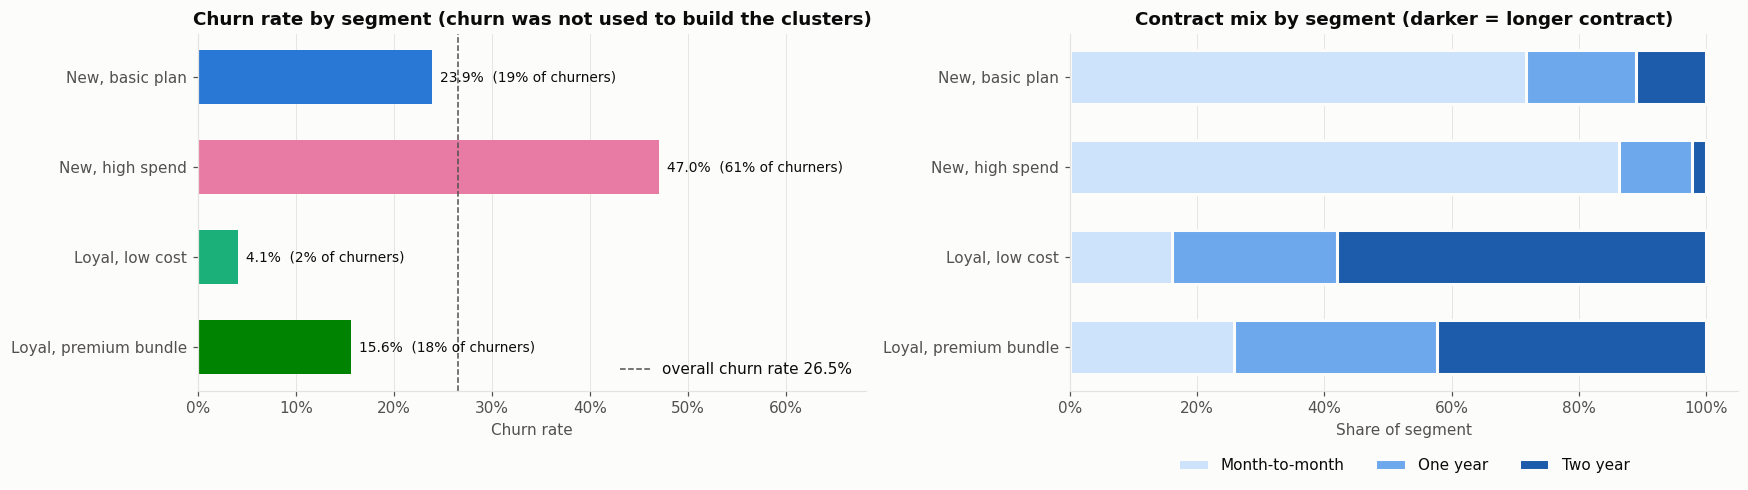

In [66]:
# ---------------------------------------------------------------
# 3B.6 Churn rate and contract mix per segment
# ---------------------------------------------------------------
overall = df["Churn_flag"].mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))

ax = axes[0]
vals = profile["churn_rate"]
ax.barh(SEG_ORDER, vals, color=[SEG_COLORS[s] for s in SEG_ORDER], height=0.6)
ax.axvline(overall, color=INK_2, ls="--", lw=1, label=f"overall churn rate {overall:.1%}")
ax.legend(loc="lower right")
for i, v in enumerate(vals):
    ax.text(v + 0.008, i, f"{v:.1%}  ({profile['share_of_all_churners'].iloc[i]:.0%} of churners)",
            va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, vals.max() * 1.45)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Churn rate")
ax.grid(axis="y", visible=False)
ax.set_title("Churn rate by segment (churn was not used to build the clusters)")

ax = axes[1]
mix = pd.crosstab(df["Segment"], df["Contract"], normalize="index").reindex(SEG_ORDER)
left = np.zeros(len(mix))
contract_cols = {"Month-to-month": "#cde2fb", "One year": "#6da7ec", "Two year": "#1c5cab"}   # light -> dark = longer
for c in ["Month-to-month", "One year", "Two year"]:
    ax.barh(mix.index, mix[c], left=left, color=contract_cols[c], height=0.6, label=c,
            edgecolor=SURFACE, linewidth=2)
    left += mix[c].values
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of segment")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.set_title("Contract mix by segment (darker = longer contract)")
fig.tight_layout()
save(fig, "08_segment_churn_and_contracts.png")
plt.show()

### 3B.7 Explaining the identified groups

| Segment | Size | Profile | Churn rate | What it means |
|---|---|---|---|---|
| **New, basic plan** | 1,509 (21%) | ~10 months, **\$29/month**, 1.7 services, 58% have no internet | 23.9% | Cheap, simple plans; average churn, low revenue (≈ \$282 to date) |
| **New, high spend** | 2,410 (34%) | ~15 months, **\$77/month**, 4.2 services, **70% fiber**, **86% month-to-month**, 53% pay by electronic check | **47.0%** | The **critical segment**: churns at almost twice the average and contains **61% of all churners** |
| **Loyal, low cost** | 972 (14%) | ~55 months, \$30/month, 2.1 services, 67% no internet, 84% on 1–2-year contracts | **4.1%** | Very stable; little retention spending needed |
| **Loyal, premium bundle** | 2,152 (31%) | ~57 months, **\$91/month**, **6.7 services**, 64% fiber | 15.6% | The **most valuable** customers (≈ \$5,242 lifetime revenue each); fewer leave, but each loss is expensive |

**Key takeaways**

* K-Means found these groups **without seeing the churn label**, yet churn rates range from **4% to 47%**. Segmentation
  on tenure, spend and engagement alone separates low-risk from high-risk customers.
* **Tenure is the main dividing line** (the first principal component explains 70% of the variance). Within each tenure
  group, spend separates basic from premium customers.
* The high-risk "New, high spend" segment matches the classification results and the Deliverable 1 EDA: new,
  month-to-month, fiber-optic customers paying by electronic check.

## Part 3C – Association Rule Mining

**Goal:** find combinations of customer attributes that frequently occur together — and especially combinations that
lead to **churn** — expressed as human-readable rules `{A, B} ⇒ {C}`.

**Each customer is treated as a "basket" of items**, for example `Contract=Month-to-month`, `Internet=Fiber optic`,
`TechSupport=No`, `Tenure=0-12`, `Churn=Yes`.

* Numeric columns are discretised first (association rules need categorical items): tenure uses the
  `tenure_group` bins from Deliverable 1, and monthly charges are split into three equal-sized bands (Low / Medium / High).
* Add-on items (`TechSupport=Yes/No`, …) are only created for internet customers, so "No" means the customer
  *chose not to buy* the add-on — not that it was unavailable.
* Very common, uninformative items (e.g. `SeniorCitizen=No`, 84% of customers) are left out so they do not flood the
  rules.

**Measures used**

* **Support** – share of all customers that contain the whole rule (how common the pattern is).
* **Confidence** – P(consequent | antecedent): of customers matching the left side, how many also have the right side.
* **Lift** – confidence ÷ overall frequency of the consequent. Lift > 1 means the items occur together **more than by
  chance**; e.g. lift 2.0 for `⇒ Churn=Yes` means those customers churn at twice the average rate.

In [67]:
# ---------------------------------------------------------------
# 3C.1 Build the one-hot "basket" table
# ---------------------------------------------------------------
charge_band = pd.qcut(df["MonthlyCharges"], q=3, labels=["Low", "Medium", "High"])
print("Monthly charge bands:", pd.qcut(df["MonthlyCharges"], q=3).cat.categories.astype(str).tolist())

basket_src = pd.DataFrame({
    "Contract": df["Contract"],
    "Internet": df["InternetService"],
    "Payment": df["PaymentMethod"],
    "Tenure": df["tenure_group"].astype(str) + " mo",
    "Charges": charge_band.astype(str),
    "Partner": df["Partner"],
    "Dependents": df["Dependents"],
    "PaperlessBilling": df["PaperlessBilling"],
    "Churn": df["Churn"],
})
basket_src.loc[df["SeniorCitizen"] == "Yes", "SeniorCitizen"] = "Yes"     # only the informative "Yes" item
basket_src.loc[df["MultipleLines"] == "Yes", "MultipleLines"] = "Yes"
has_internet = df["InternetService"] != "No"
for c in ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]:
    basket_src.loc[has_internet, c] = df.loc[has_internet, c]           # NaN (no item) for no-internet customers

basket = pd.get_dummies(basket_src, prefix_sep="=").astype(bool)
print(f"Transactions (customers): {basket.shape[0]:,}   Distinct items: {basket.shape[1]}")
basket.mean().sort_values(ascending=False).round(3).rename("support").to_frame().T

Monthly charge bands: ['(18.249, 50.4]', '(50.4, 83.9]', '(83.9, 118.75]']
Transactions (customers): 7,043   Distinct items: 40


,Churn=No,Dependents=No,PaperlessBilling=Yes,Contract=Month-to-month,Partner=No,OnlineSecurity=No,TechSupport=No,Partner=Yes,Internet=Fiber optic,DeviceProtection=No,OnlineBackup=No,MultipleLines=Yes,PaperlessBilling=No,StreamingTV=No,StreamingMovies=No,StreamingMovies=Yes,StreamingTV=Yes,OnlineBackup=Yes,DeviceProtection=Yes,Internet=DSL,Payment=Electronic check,Charges=Low,Charges=High,Charges=Medium,Tenure=0-12 mo,Dependents=Yes,TechSupport=Yes,OnlineSecurity=Yes,Churn=Yes,Contract=Two year,Payment=Mailed check,Tenure=25-48 mo,Payment=Bank transfer (automatic),Internet=No,Payment=Credit card (automatic),Contract=One year,Tenure=61-72 mo,SeniorCitizen=Yes,Tenure=13-24 mo,Tenure=49-60 mo
support,0.735,0.7,0.592,0.55,0.517,0.497,0.493,0.483,0.44,0.439,0.438,0.422,0.408,0.399,0.395,0.388,0.384,0.345,0.344,0.344,0.336,0.334,0.333,0.333,0.31,0.3,0.29,0.287,0.265,0.241,0.229,0.226,0.219,0.217,0.216,0.209,0.2,0.162,0.145,0.118


In [68]:
# ---------------------------------------------------------------
# 3C.2 Frequent itemsets with Apriori, cross-checked with FP-Growth
# ---------------------------------------------------------------
MIN_SUPPORT = 0.05     # pattern must cover at least 5% of customers (~350 people)
MAX_LEN = 4            # rules of up to 4 items stay readable

t0 = time.time()
freq_apriori = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
t_ap = time.time() - t0
t0 = time.time()
freq_fp = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
t_fp = time.time() - t0

same = set(freq_apriori["itemsets"]) == set(freq_fp["itemsets"])
print(f"Apriori   : {len(freq_apriori):,} frequent itemsets in {t_ap:.2f} s")
print(f"FP-Growth : {len(freq_fp):,} frequent itemsets in {t_fp:.2f} s")
print("Both algorithms found exactly the same itemsets:", same)

Apriori   : 10,429 frequent itemsets in 0.72 s
FP-Growth : 10,429 frequent itemsets in 2.02 s
Both algorithms found exactly the same itemsets: True


In [69]:
# ---------------------------------------------------------------
# 3C.3 Generate association rules
# ---------------------------------------------------------------
def make_rules(freq, n_transactions, min_confidence):
    # mlxtend changed the signature of association_rules between versions; support both.
    try:
        return association_rules(freq, num_itemsets=n_transactions, metric="confidence",
                                 min_threshold=min_confidence)
    except TypeError:
        return association_rules(freq, metric="confidence", min_threshold=min_confidence)

rules = make_rules(freq_apriori, len(basket), min_confidence=0.5)
rules = rules[rules["lift"] > 1].copy()                          # keep positively associated rules only
rules["antecedent"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
rules["consequent"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
rules["n_antecedent"] = rules["antecedents"].apply(len)
print(f"Rules with confidence >= 0.5 and lift > 1: {len(rules):,}")

cols = ["antecedent", "consequent", "support", "confidence", "lift"]

# (a) Rules that predict churn
all_churn_rules = rules[rules["consequent"] == "Churn=Yes"]

# Many churn rules are near-copies: {Fiber, first year} plus one more item that adds almost nothing.
# A rule is kept as NON-REDUNDANT only if it beats every simpler rule (subset of its left side)
# by at least 0.05 in lift - i.e. the extra item genuinely adds risk.
simpler = dict(zip(all_churn_rules["antecedents"], all_churn_rules["lift"]))
def is_non_redundant(row, tol=0.05):
    return all(row["lift"] >= lift + tol for ante, lift in simpler.items() if ante < row["antecedents"])

churn_rules = (all_churn_rules[all_churn_rules.apply(is_non_redundant, axis=1)]
               .sort_values(["lift", "support"], ascending=False))
print(f"Rules leading to Churn=Yes: {len(all_churn_rules)}   non-redundant: {len(churn_rules)}")
churn_rules[cols].head(12).round(3).reset_index(drop=True)

Rules with confidence >= 0.5 and lift > 1: 31,739
Rules leading to Churn=Yes: 331   non-redundant: 254


,antecedent,consequent,support,confidence,lift
0,"Internet=Fiber optic, PaperlessBilling=Yes, Tenure=0-12 mo",Churn=Yes,0.074,0.723,2.724
1,"Internet=Fiber optic, OnlineSecurity=No, Tenure=0-12 mo",Churn=Yes,0.085,0.717,2.701
2,"Internet=Fiber optic, Tenure=0-12 mo",Churn=Yes,0.092,0.699,2.633
3,"PaperlessBilling=Yes, Payment=Electronic check, Tenure=0-12 mo",Churn=Yes,0.068,0.671,2.528
4,"OnlineSecurity=No, Payment=Electronic check, Tenure=0-12 mo",Churn=Yes,0.078,0.668,2.518
5,"Payment=Electronic check, TechSupport=No, Tenure=0-12 mo",Churn=Yes,0.078,0.665,2.505
6,"OnlineBackup=No, Payment=Electronic check, Tenure=0-12 mo",Churn=Yes,0.071,0.664,2.504
7,"PaperlessBilling=Yes, TechSupport=No, Tenure=0-12 mo",Churn=Yes,0.089,0.655,2.468
8,"OnlineSecurity=No, PaperlessBilling=Yes, Tenure=0-12 mo",Churn=Yes,0.091,0.652,2.456
9,"DeviceProtection=No, Payment=Electronic check, Tenure=0-12 mo",Churn=Yes,0.069,0.642,2.418


In [70]:
# ---------------------------------------------------------------
# 3C.3b Broad churn patterns: two-item rules that cover the most customers
# ---------------------------------------------------------------
# The top rules above are the most *intense*; these are the most *widespread* risk patterns.
broad = all_churn_rules[all_churn_rules["n_antecedent"] == 2].sort_values("support", ascending=False)
broad[cols].head(8).round(3).reset_index(drop=True)

,antecedent,consequent,support,confidence,lift
0,"Contract=Month-to-month, TechSupport=No",Churn=Yes,0.192,0.504,1.898
1,"Contract=Month-to-month, OnlineSecurity=No",Churn=Yes,0.191,0.510,1.924
2,"Contract=Month-to-month, Internet=Fiber optic",Churn=Yes,0.165,0.546,2.058
3,"Contract=Month-to-month, OnlineBackup=No",Churn=Yes,0.163,0.503,1.896
4,"Contract=Month-to-month, Tenure=0-12 mo",Churn=Yes,0.145,0.514,1.935
5,"Contract=Month-to-month, Payment=Electronic check",Churn=Yes,0.141,0.537,2.025
6,"OnlineSecurity=No, Payment=Electronic check",Churn=Yes,0.131,0.532,2.004
7,"Payment=Electronic check, TechSupport=No",Churn=Yes,0.131,0.532,2.004


In [71]:
# ---------------------------------------------------------------
# 3C.4 Retention patterns: rules that lead to Churn=No with very high confidence
# ---------------------------------------------------------------
stay_rules = (rules[(rules["consequent"] == "Churn=No") & (rules["confidence"] >= 0.95)]
              .sort_values(["support", "confidence"], ascending=False))
print(f"Rules leading to Churn=No with confidence >= 95%: {len(stay_rules)}")
stay_rules[cols].head(10).round(3).reset_index(drop=True)

Rules leading to Churn=No with confidence >= 95%: 133


,antecedent,consequent,support,confidence,lift
0,Contract=Two year,Churn=No,0.234,0.972,1.323
1,"Contract=Two year, Partner=Yes",Churn=No,0.165,0.974,1.326
2,"Contract=Two year, Tenure=61-72 mo",Churn=No,0.136,0.969,1.318
3,"Contract=Two year, PaperlessBilling=No",Churn=No,0.127,0.984,1.339
4,"Contract=Two year, Dependents=No",Churn=No,0.124,0.967,1.316
5,"Contract=Two year, MultipleLines=Yes",Churn=No,0.119,0.960,1.307
6,"Contract=Two year, TechSupport=Yes",Churn=No,0.112,0.965,1.313
7,"Contract=Two year, DeviceProtection=Yes",Churn=No,0.111,0.958,1.305
8,"Contract=Two year, Dependents=Yes",Churn=No,0.110,0.977,1.330
9,"Contract=Two year, Partner=Yes, Tenure=61-72 mo",Churn=No,0.107,0.969,1.319


In [72]:
# ---------------------------------------------------------------
# 3C.5 Service-bundle patterns (no churn item): what do customers buy together?
# ---------------------------------------------------------------
service_prefixes = ("OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                    "StreamingTV", "StreamingMovies", "MultipleLines", "Internet")
is_service_rule = rules.apply(
    lambda r: all(i.startswith(service_prefixes) for i in r["antecedents"] | r["consequents"])
    and all(i.endswith("=Yes") or i.startswith("Internet") for i in r["antecedents"] | r["consequents"]),
    axis=1)
bundle_rules = (rules[is_service_rule & (rules["lift"] >= 1.3)]
                .sort_values(["lift", "confidence"], ascending=False))
print(f"Service-bundle rules (items bought, lift >= 1.3): {len(bundle_rules)}")
bundle_rules[cols].head(10).round(3).reset_index(drop=True)

Service-bundle rules (items bought, lift >= 1.3): 509


,antecedent,consequent,support,confidence,lift
0,"StreamingMovies=Yes, TechSupport=Yes","DeviceProtection=Yes, StreamingTV=Yes",0.100,0.574,2.580
1,"StreamingTV=Yes, TechSupport=Yes","DeviceProtection=Yes, StreamingMovies=Yes",0.100,0.579,2.556
2,"Internet=DSL, OnlineSecurity=Yes, StreamingTV=Yes",TechSupport=Yes,0.053,0.729,2.512
3,"Internet=DSL, OnlineSecurity=Yes, StreamingMovies=Yes",TechSupport=Yes,0.055,0.718,2.475
4,"Internet=Fiber optic, StreamingMovies=Yes","MultipleLines=Yes, StreamingTV=Yes",0.136,0.549,2.451
5,"MultipleLines=Yes, StreamingTV=Yes","Internet=Fiber optic, StreamingMovies=Yes",0.136,0.609,2.451
6,"OnlineSecurity=Yes, StreamingTV=Yes","DeviceProtection=Yes, StreamingMovies=Yes",0.082,0.552,2.437
7,"MultipleLines=Yes, StreamingMovies=Yes","Internet=Fiber optic, StreamingTV=Yes",0.136,0.604,2.431
8,"Internet=Fiber optic, StreamingTV=Yes","MultipleLines=Yes, StreamingMovies=Yes",0.136,0.549,2.431
9,"OnlineSecurity=Yes, StreamingMovies=Yes","DeviceProtection=Yes, StreamingTV=Yes",0.082,0.539,2.423


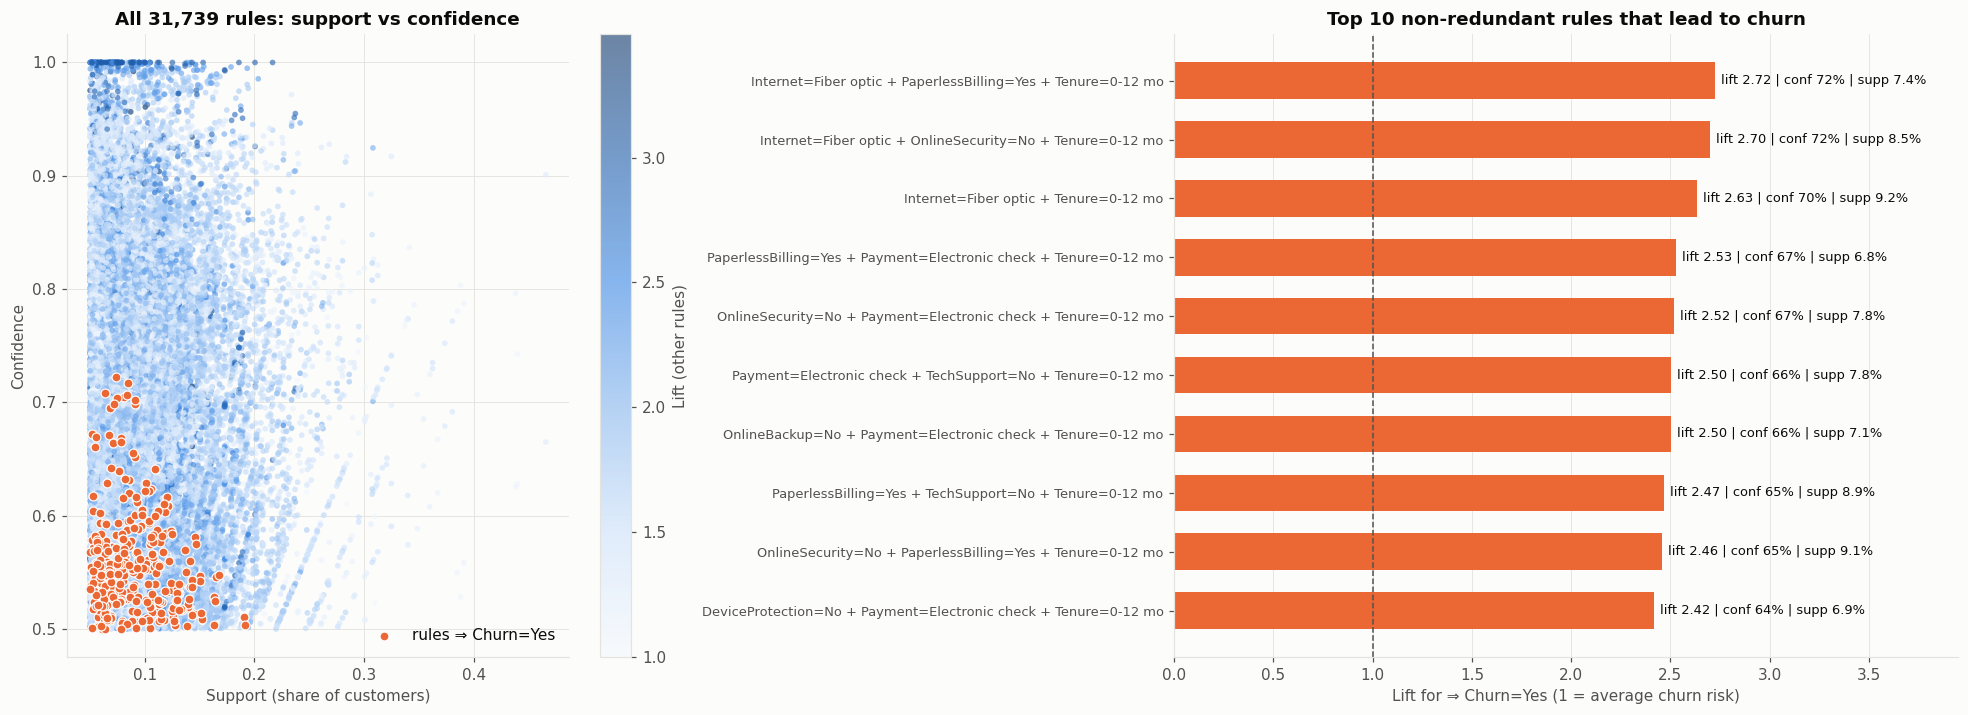

In [73]:
# ---------------------------------------------------------------
# 3C.6 Visualise the rules
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 6.6), gridspec_kw={"width_ratios": [1, 1.25]})

ax = axes[0]
other = rules[rules["consequent"] != "Churn=Yes"]
sc = ax.scatter(other["support"], other["confidence"], c=other["lift"], cmap=SEQ_BLUE, s=14, alpha=0.6,
                edgecolor="none", vmin=1, vmax=rules["lift"].quantile(0.99))
ax.scatter(all_churn_rules["support"], all_churn_rules["confidence"], s=34, color=CAT[1], edgecolor=SURFACE,
           linewidth=0.8, label="rules ⇒ Churn=Yes", zorder=4)
cb = fig.colorbar(sc, ax=ax)
cb.set_label("Lift (other rules)")
ax.set_xlabel("Support (share of customers)")
ax.set_ylabel("Confidence")
ax.set_title(f"All {len(rules):,} rules: support vs confidence")
ax.legend(loc="lower right")

ax = axes[1]
top = churn_rules.head(10).iloc[::-1]
labels = [a.replace(", ", " + ") for a in top["antecedent"]]
ax.barh(range(len(top)), top["lift"], color=CAT[1], height=0.62)
for i, (lift, conf, sup) in enumerate(zip(top["lift"], top["confidence"], top["support"])):
    ax.text(lift + 0.03, i, f"lift {lift:.2f} | conf {conf:.0%} | supp {sup:.1%}", va="center", fontsize=8.5)
ax.set_yticks(range(len(top)), labels, fontsize=8.5)
ax.axvline(1, color=INK_2, ls="--", lw=1)
ax.set_xlim(0, top["lift"].max() * 1.45)
ax.set_xlabel("Lift for ⇒ Churn=Yes (1 = average churn risk)")
ax.grid(axis="y", visible=False)
ax.set_title("Top 10 non-redundant rules that lead to churn")
fig.tight_layout()
save(fig, "09_association_rules.png")
plt.show()

### 3C.7 Pattern-mining insights

* **Apriori and FP-Growth agree:** both found exactly the same **10,429 frequent itemsets** (minimum support 5%), which
  confirms the result. FP-Growth avoids generating candidate itemsets, so it scales better on large data. On this small
  item set (40 items) both finish in seconds.
* **31,739 rules** pass confidence ≥ 50% and lift > 1. Of these, **331 lead to churn**, and 254 remain after removing
  redundant rules.
* **Three churn "themes" dominate**, all involving the **first year** of the relationship:
  1. **Fiber optic + first 12 months → 70% churn** (lift 2.63, ≈ 9% of customers). Adding *paperless billing* or *no
     OnlineSecurity* pushes it to **72%**.
  2. **Electronic check + first 12 months** (+ paperless billing or a missing protective add-on) → **66–67% churn**
     (lift ≈ 2.5).
  3. **No protective add-ons (OnlineSecurity / TechSupport = No) + first 12 months** → **64–65% churn** (lift ≈ 2.4).
* **The most widespread risk patterns** (two-item rules with the highest support) involve month-to-month contracts:
  e.g. *{Month-to-month, Fiber optic} ⇒ Churn* covers **16.5% of all customers** with 55% confidence (lift 2.06), and
  *{Month-to-month, Electronic check} ⇒ Churn* covers 14.1% with 54% confidence.
* **Retention pattern:** *{Two-year contract} ⇒ Stay* holds with **97.2%** confidence: almost every customer on a two-year contract (24% of all customers) stays.
* **Bundle patterns (cross-selling):** add-ons are bought together. For example, customers with *StreamingTV + TechSupport*
  are 2.6× more likely than average to also have *DeviceProtection + StreamingMovies*, and DSL customers with
  *OnlineSecurity + StreamingTV* buy *TechSupport* 73% of the time (lift 2.5).

## Part 3D – Real-World Application, Challenges and Conclusion (Part 3)

### How these patterns can be applied

The three techniques point to the same story from different angles, which makes the findings trustworthy:
**new customers on flexible contracts, especially fiber-optic customers paying by electronic check and without
protective add-ons, are the most likely to leave.**

| Finding | Evidence | Real-world action |
|---|---|---|
| Churn can be predicted in advance | Random Forest catches 74% of churners (ROC-AUC 0.84); tuned tree and logistic regression catch 78% | **Score every customer monthly** and send the highest-risk list to the retention team. Combine with the Deliverable 2 value model to rank by **revenue at risk**. |
| The first year is the danger zone | All top churn rules include *Tenure = 0–12 months*; the "New, high spend" segment churns at 47% | Run a **12-month onboarding programme**: welcome calls, a 3-month check-in, and early-life satisfaction surveys. |
| Fiber-optic customers churn most | Rule {Fiber, first year} ⇒ churn 70%; fiber is a top split in the decision tree | **Investigate fiber service quality and pricing** (fiber is the premium product, yet it churns most); offer first-year price locks. |
| Contracts retain customers | {Two-year contract} ⇒ stay 97%; contract is the tree's first split | **Offer incentives to move month-to-month customers to 1- or 2-year contracts** (e.g. a discount or free add-on). |
| Electronic-check payers churn more | Electronic-check rules at lift 2.0–2.5 | **Encourage automatic payment** with a small bill credit for switching. |
| Protective add-ons are linked to staying | "No TechSupport / No OnlineSecurity" appear in many churn rules | Include a **free trial of OnlineSecurity / TechSupport** for new internet customers. |
| Add-ons are bought in bundles | Bundle rules with lift ≈ 2.4–2.6 | Design **"protection" and "entertainment" bundles** for cross-selling to customers who own one item. |
| Segments need different strategies | 4% churn (Loyal, low cost) vs 47% (New, high spend) | **Spend the retention budget where it matters**: proactive outreach for New/high-spend, VIP care for Loyal/premium, minimal spend for Loyal/low-cost. |

**Caution:** these are associations, not proof of cause and effect. For example, auto-pay customers may stay longer
because they are already committed, not *because* of auto-pay. Each action should be tested (e.g. an A/B test of the
onboarding programme) before full rollout. Using `SeniorCitizen` as a model input also needs a fairness review; this
is examined in Part 4 below.

### Challenges Encountered and How They Were Addressed

| Challenge | How it was addressed |
|---|---|
| **Class imbalance** (only 26.5% churners): accuracy rewards predicting "stay" for everyone. | Stratified split and folds, `class_weight="balanced"`, and model selection by **F1 / recall / ROC-AUC** rather than accuracy. |
| **Overfitting of the default Decision Tree** (near-perfect training score, weak test score). | `GridSearchCV` over depth, leaf size, criterion and class weight with 5-fold CV; the heatmaps show the train–validation gap closing for the chosen settings. |
| **Different feature scales** would distort k-NN distances and K-Means clusters. | `StandardScaler` inside every pipeline (fitted on training folds only) and on the clustering features. |
| **Choosing the number of clusters** has no single right answer. | Combined the elbow curve, silhouette scores and business interpretability; profiled clusters with churn only *after* clustering. |
| **K-Means labels are arbitrary** (cluster "0" can change between runs or library versions). | Re-numbered clusters by average tenure and spend so segment names stay attached to the right group. |
| **Association rules need categorical items** and can explode in number. | Binned tenure and charges, created add-on items only for internet customers, dropped uninformative items, and used minimum support (5%), confidence (50%), lift > 1 and a maximum rule length of 4. |
| **Library version differences** (`mlxtend` changed `association_rules`' arguments). | Wrote a small wrapper that works with both old and new versions. |

### Conclusion

* **Classification:** six classifiers were compared with confusion matrices, ROC curves, accuracy and F1. **Random
  Forest** performed best (F1 0.636, ROC-AUC 0.843, 74% of churners caught). **GridSearchCV tuning** of the Decision
  Tree (`max_depth=4`, `min_samples_leaf=40`, `gini`, `balanced`) raised its test F1 from 0.499 to 0.621 and removed
  overfitting.
* **Clustering:** K-Means with **k = 4** (best silhouette, 0.427) found four interpretable segments. Churn ranges from
  4% (Loyal, low cost) to 47% (New, high spend), even though churn was not used to form the clusters.
* **Association rules:** Apriori (confirmed by FP-Growth) found that **fiber optic, electronic-check payment and missing
  protective add-ons in the first year** lead to churn rates of 64–72% (lift ≈ 2.4–2.7), while **two-year contracts**
  lead to 97% retention.

Together, the models give the business **who** is likely to leave (classification), **which group** they belong to
(clustering) and **why** (association rules). Part 4 reviews the ethical side and Part 5 consolidates the recommendations.

---
# Part 4 – Ethical Considerations: Privacy, Fairness and Bias (Deliverable 4)

A churn model decides **who receives attention** (calls, discounts, offers), and a value model decides **how much the
company is willing to spend** on each customer. Both can treat groups of people differently, so we checked the project
for privacy risks, unfair outcomes and biases in the data.

## 4.1 Data privacy

| Risk | What we did / recommend |
|---|---|
| Customer records are personal data | The dataset is an **IBM sample of a fictional company**: no real customers are identifiable. It contains no names, addresses, phone numbers or payment details. |
| `customerID` links predictions to a person | It is a pseudonymous code. It was **never used as a model input** (checked below) and only kept so results could be traced back to rows. |
| Sensitive attributes (age group, gender, household) | Used only for analysis and fairness checks. `gender` was **excluded** from the churn models. |
| Real deployment | Apply **data minimisation** (keep only fields the model needs), role-based access, encryption, retention limits, and a lawful basis or consent for this use of customer data under laws such as **GDPR** and **CCPA**. Publish only aggregated results. |

In [74]:
# ---------------------------------------------------------------
# 4.1 Privacy checks: identifiers and sensitive attributes in the model inputs
# ---------------------------------------------------------------
FIG_PREFIX = "p4_"     # figures from Part 4 are saved as Images/p4_*.png
sensitive = ["gender", "SeniorCitizen", "Partner", "Dependents"]

def used_in(columns, attr):
    return any(col == attr or col.startswith(attr + "_") for col in columns)

usage = pd.DataFrame({
    "Regression inputs (Part 2)": [used_in(X_eng.columns, a) for a in ["customerID"] + sensitive],
    "Churn classifier inputs (Part 3A)": [used_in(X.columns, a) for a in ["customerID"] + sensitive],
    "Clustering inputs (Part 3B)": [a in cluster_features for a in ["customerID"] + sensitive],
}, index=["customerID"] + sensitive).replace({True: "used", False: "not used"})
usage

,Regression inputs (Part 2),Churn classifier inputs (Part 3A),Clustering inputs (Part 3B)
customerID,not used,not used,not used
gender,used,not used,not used
SeniorCitizen,used,used,not used
Partner,used,used,not used
Dependents,used,used,not used


**Regression check.** The revenue model (Part 2) used `gender` and `SeniorCitizen` as inputs. Below we measure how much
the Lasso model actually relies on them, compared with its strongest feature.

In [75]:
# ---------------------------------------------------------------
# 4.1b How much does the regression model rely on sensitive attributes?
# ---------------------------------------------------------------
sens_coef = lasso_coef[[c for c in lasso_coef.index if any(c.startswith(a + "_") for a in sensitive)]]
top_abs = lasso_coef.abs().max()
pd.DataFrame({"Lasso coefficient ($ per std. dev.)": sens_coef.round(1),
              "% of the largest coefficient": (sens_coef.abs() / top_abs * 100).round(1)})

,Lasso coefficient ($ per std. dev.),% of the largest coefficient
gender_Male,24.7,2.7
SeniorCitizen_Yes,59.8,6.5
Partner_Yes,170.9,18.4
Dependents_Yes,-47.2,5.1


## 4.2 Fairness analysis of the churn model

We audit the **best churn model (Random Forest, Part 3A)** on the test set for two groups:

* **Senior citizens vs non-seniors.** `SeniorCitizen` *is* a model input, and age is a protected characteristic in many
  settings.
* **Women vs men.** `gender` is *not* an input, but outcomes can still differ.

For each group we compare:

* **Flag rate:** share of customers the model marks as "likely to churn" (they would receive retention outreach).
* **Recall (true positive rate):** share of real churners the model catches. Equal recall across groups is the
  *equal opportunity* criterion.
* **False positive rate:** share of loyal customers wrongly flagged.
* **Precision:** share of flagged customers who really churn.

Finally, we **retrain the model without `SeniorCitizen`** to see whether removing the attribute changes accuracy or the
group differences.

In [76]:
# ---------------------------------------------------------------
# 4.2 Group metrics for the Random Forest, with and without the SeniorCitizen input
# ---------------------------------------------------------------
test_rows = df.loc[X_test.index]          # the original attributes of the test customers

def group_metrics(y_true, y_pred, groups):
    out = []
    for g in sorted(groups.unique()):
        m = (groups == g).values
        yt, yp = y_true[m], y_pred[m]
        out.append({"group": g, "customers": int(m.sum()), "actual churn rate": yt.mean(),
                    "flag rate": yp.mean(), "recall (TPR)": yp[yt == 1].mean(),
                    "false positive rate": yp[yt == 0].mean(), "precision": yt[yp == 1].mean()})
    return pd.DataFrame(out).set_index("group")

y_true_test = y_test.values
pred_with = preds["Random Forest"]

# Same Random Forest settings, but SeniorCitizen removed from the inputs
X_no_senior = X.drop(columns=["SeniorCitizen_Yes"])
rf_no_senior = make_pipeline(StandardScaler(), RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))
rf_no_senior.fit(X_no_senior.loc[X_train.index], y_train)
proba_without = rf_no_senior.predict_proba(X_no_senior.loc[X_test.index])[:, 1]
pred_without = (proba_without >= 0.5).astype(int)

overall_cmp = pd.DataFrame({
    "with SeniorCitizen": [f1_score(y_test, pred_with), roc_auc_score(y_test, probas["Random Forest"]),
                           recall_score(y_test, pred_with)],
    "without SeniorCitizen": [f1_score(y_test, pred_without), roc_auc_score(y_test, proba_without),
                              recall_score(y_test, pred_without)],
}, index=["F1", "ROC-AUC", "Recall"]).round(4)
print("Overall test performance of the Random Forest:")
print(overall_cmp, "\n")

senior_with = group_metrics(y_true_test, pred_with, test_rows["SeniorCitizen"])
senior_without = group_metrics(y_true_test, pred_without, test_rows["SeniorCitizen"])
gender_with = group_metrics(y_true_test, pred_with, test_rows["gender"])

fair_table = pd.concat({"Senior (model WITH SeniorCitizen)": senior_with,
                        "Senior (model WITHOUT SeniorCitizen)": senior_without,
                        "Gender (gender never used)": gender_with})
fair_table.round(3)

Overall test performance of the Random Forest:
         with SeniorCitizen  without SeniorCitizen
F1                   0.6358                 0.6327
ROC-AUC              0.8432                 0.8409
Recall               0.7353                 0.7299 



customers  actual churn rate  flag rate  recall (TPR)  false positive rate  precision
                                     group                                                                                        
Senior (model WITH SeniorCitizen)    No           1187              0.233      0.302         0.696                0.182      0.536
                                     Yes           222              0.441      0.599         0.847                0.403      0.624
Senior (model WITHOUT SeniorCitizen) No           1187              0.233      0.303         0.696                0.184      0.533
                                     Yes           222              0.441      0.581         0.827                0.387      0.628
Gender (gender never used)           Female        687              0.281      0.342         0.705                0.200      0.579
                                     Male          722              0.251      0.355         0.768                0.216      0.543

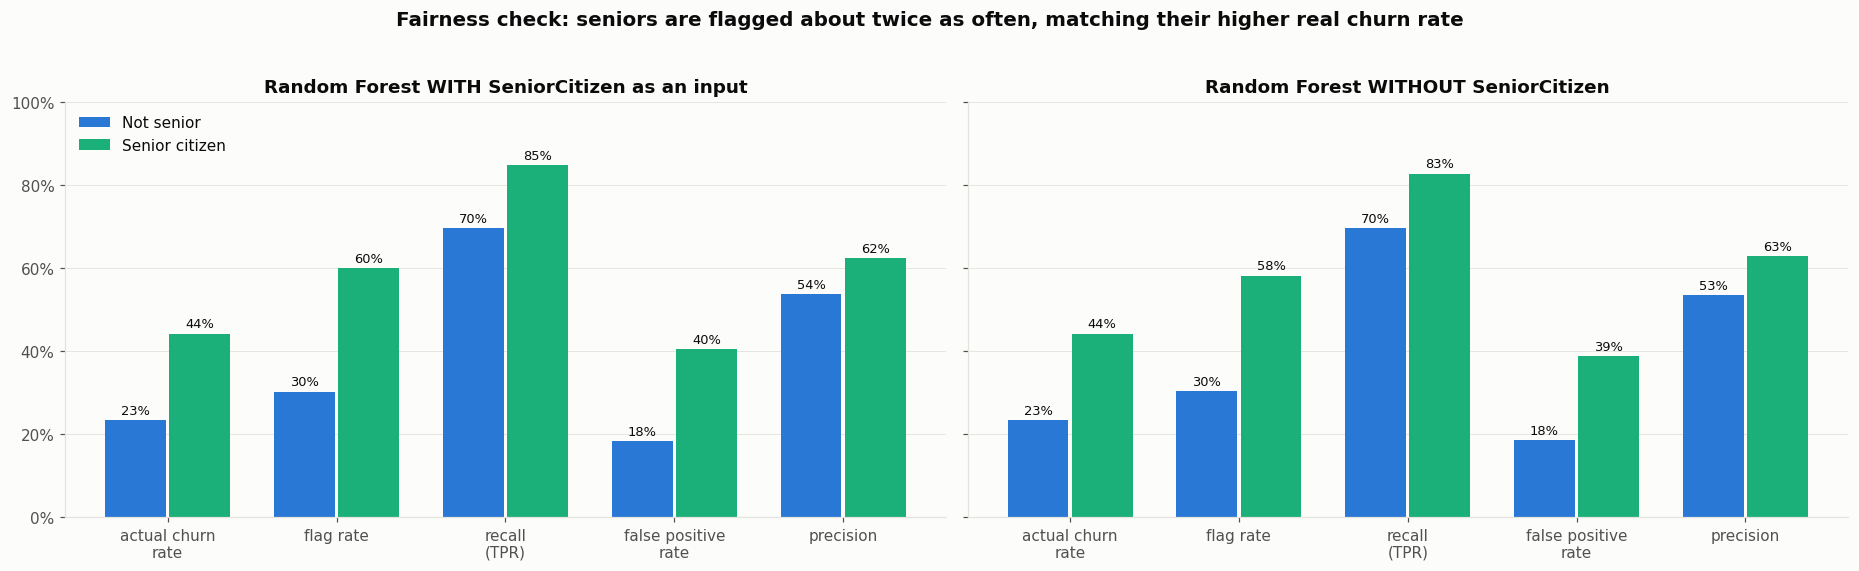

In [77]:
# ---------------------------------------------------------------
# 4.3 Visualise the fairness metrics by senior status
# ---------------------------------------------------------------
metrics_f = ["actual churn rate", "flag rate", "recall (TPR)", "false positive rate", "precision"]
group_colors = {"No": CAT[0], "Yes": CAT[2]}
fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharey=True)
for ax, tbl, title in [(axes[0], senior_with, "Random Forest WITH SeniorCitizen as an input"),
                       (axes[1], senior_without, "Random Forest WITHOUT SeniorCitizen")]:
    x = np.arange(len(metrics_f))
    for k, g in enumerate(["No", "Yes"]):
        vals = tbl.loc[g, metrics_f].values.astype(float)
        bars = ax.bar(x + (k - 0.5) * 0.38, vals, width=0.36, color=group_colors[g],
                      label="Senior citizen" if g == "Yes" else "Not senior")
        for xi, v in zip(x + (k - 0.5) * 0.38, vals):
            ax.text(xi, v + 0.015, f"{v:.0%}", ha="center", fontsize=8.5)
    ax.set_xticks(x, [m.replace(" (TPR)", "\n(TPR)").replace("false positive rate", "false positive\nrate")
                      .replace("actual churn rate", "actual churn\nrate") for m in metrics_f])
    ax.set_ylim(0, 1.0)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
axes[0].legend(loc="upper left")
fig.suptitle("Fairness check: seniors are flagged about twice as often, matching their higher real churn rate",
             fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "fairness_senior.png")
plt.show()

In [78]:
# ---------------------------------------------------------------
# 4.4 Proxy check: why removing SeniorCitizen barely changes the outcome
# ---------------------------------------------------------------
proxy = df.groupby("SeniorCitizen").agg(
    customers=("customerID", "size"),
    churn_rate=("Churn_flag", "mean"),
    pct_fiber=("InternetService", lambda s: (s == "Fiber optic").mean()),
    pct_electronic_check=("PaymentMethod", lambda s: (s == "Electronic check").mean()),
    pct_month_to_month=("Contract", lambda s: (s == "Month-to-month").mean()),
    pct_paperless=("PaperlessBilling", lambda s: (s == "Yes").mean()),
    avg_monthly_charges=("MonthlyCharges", "mean"),
)
proxy.round(3)

,customers,churn_rate,pct_fiber,pct_electronic_check,pct_month_to_month,pct_paperless,avg_monthly_charges
SeniorCitizen,,,,,,,
No,5901,0.236,0.384,0.30,0.520,0.558,61.847
Yes,1142,0.417,0.728,0.52,0.707,0.767,79.820


### 4.6 Interpreting the fairness results

**What the audit shows**

* **Seniors are flagged about twice as often** (60% vs 30%). Their *actual* churn rate is also about twice as high
  (44% vs 23% in the test set), so the difference largely reflects real behaviour rather than an arbitrary penalty.
* **Equal opportunity is not violated against seniors:** the model catches **85%** of senior churners vs **70%** of
  non-senior churners, and precision is higher for seniors (62% vs 54%).
* **But loyal seniors are wrongly flagged more often:** the false positive rate is **40% vs 18%**. If being flagged
  means a *helpful* offer (a discount, a service check) this costs the customer little. If it meant pressure sales or
  worse treatment, it would be a real harm.
* **Removing `SeniorCitizen` hardly changes anything:** F1 0.636 → 0.633, ROC-AUC 0.843 → 0.841, and the senior flag
  rate only drops from 60% to 58%. The **proxy table** explains why: seniors are far more likely to have fiber optic
  (73% vs 38%), pay by electronic check (52% vs 30%) and be on month-to-month contracts (71% vs 52%), so the model can
  infer senior status from other inputs. *Simply deleting a sensitive column does not make a model fair.*
* **Gender** (never an input) shows only modest differences: flag rate 34% vs 36%, recall 71% (women) vs 77% (men).
* **Regression model:** sensitive attributes carry little weight. `gender` is 2.7% and `SeniorCitizen` 6.5% of the
  largest Lasso coefficient.

**Steps taken and recommended**

1. `customerID` was never used as a model input, and `gender` was excluded from the churn models.
2. **Deploy the churn model without `SeniorCitizen`.** It costs almost no accuracy (−0.003 F1) and avoids treating
   customers differently *directly* because of age. Likewise, drop `gender` and `SeniorCitizen` from the revenue model
   (small weights).
3. Because proxies remain, **monitor outcomes by group** (flag rate, recall, false positive rate) every time the model is
   retrained, rather than relying on removed columns.
4. **Use the scores only for beneficial actions** (retention offers, proactive support). Never use them to raise prices,
   restrict service or make credit decisions. Respect contact opt-outs.
5. Keep **interpretable models** (Logistic Regression, the tuned Decision Tree) available, so individual decisions can be
   explained and reviewed by a person.

## 4.5 Potential biases in the dataset and models

| Source of bias | Effect on our results | How we handled it / what would be needed |
|---|---|---|
| **Sample data from one fictional company** (IBM sample) | Patterns may not transfer to real telecoms, other regions or other time periods | Results are presented as patterns to *test*, not facts; a real deployment must retrain on its own data |
| **Snapshot in time** (one quarter) | `tenure` and `TotalCharges` are *censored* for customers who are still active, so their lifetime revenue is understated | Documented in Part 2; a survival-analysis approach would handle censoring properly |
| **Class imbalance** (26.5% churn) | Models can ignore churners | Stratification, class weights, and evaluation with F1, recall and ROC-AUC |
| **Missing explanatory variables** (satisfaction, network quality, complaints, competitor offers) | Models may blame *who* customers are (e.g. seniors) for what is really *service experience* | Treat demographic patterns with caution; collect experience data before acting on them |
| **Proxy variables** | Removing a sensitive attribute does not remove its influence (shown above) | Audit outcomes by group instead of relying only on removing attributes |
| **Associations are not causes** (Part 3C) | Acting on a rule may not change behaviour | A/B test interventions before rollout |

---
# Part 5 – Consolidated Results, Recommendations and Future Improvements

In [79]:
# ---------------------------------------------------------------
# 5.1 One table with the headline result of every technique (pulled from the variables above)
# ---------------------------------------------------------------
best_reg = test_results["Test R2"].idxmax()
best_clf = results["F1"].idxmax()
summary_rows = [
    ("Regression (lifetime revenue)", f"Best: {best_reg}; recommended: Ridge",
     f"Test R² {test_results.loc[best_reg, 'Test R2']:.3f}, RMSE ${test_results.loc[best_reg, 'Test RMSE $']:,.0f}; "
     f"Ridge R² {test_results.loc['Ridge', 'Test R2']:.3f}"),
    ("Feature engineering", "Linear Regression, raw → engineered",
     f"CV R² {pivot_r2.loc['Linear Regression', 'Raw']:.3f} → {pivot_r2.loc['Linear Regression', 'Engineered']:.3f}"),
    ("Classification (churn)", f"Best: {best_clf}",
     f"F1 {results.loc[best_clf, 'F1']:.3f}, ROC-AUC {results.loc[best_clf, 'ROC-AUC']:.3f}, "
     f"recall {results.loc[best_clf, 'Recall']:.0%}"),
    ("Hyperparameter tuning", "Decision Tree, default → GridSearchCV",
     f"Test F1 {results.loc['Decision Tree (default)', 'F1']:.3f} → {results.loc['Decision Tree (tuned)', 'F1']:.3f}"),
    ("Clustering (K-Means, k = 4)", f"Silhouette {silhouette_score(Xc, df['Cluster']):.3f}",
     f"Churn by segment: {profile['churn_rate'].min():.0%} to {profile['churn_rate'].max():.0%}"),
    ("Association rules (Apriori / FP-Growth)", f"{len(rules):,} rules; {len(all_churn_rules)} lead to churn",
     f"Top churn rule: {churn_rules.iloc[0]['antecedent']} ⇒ Churn "
     f"(conf {churn_rules.iloc[0]['confidence']:.0%}, lift {churn_rules.iloc[0]['lift']:.2f})"),
    ("Fairness (Random Forest)", "Without SeniorCitizen input",
     f"F1 {overall_cmp.loc['F1', 'with SeniorCitizen']:.3f} → {overall_cmp.loc['F1', 'without SeniorCitizen']:.3f}; "
     f"senior flag rate {senior_with.loc['Yes', 'flag rate']:.0%} → {senior_without.loc['Yes', 'flag rate']:.0%}"),
]
with pd.option_context("display.max_colwidth", 200):
    display(pd.DataFrame(summary_rows, columns=["Technique", "Model / setting", "Headline result"]))

,Technique,Model / setting,Headline result
0,Regression (lifetime revenue),Best: Gradient Boosting; recommended: Ridge,"Test R² 0.801, RMSE $1,017; Ridge R² 0.800"
1,Feature engineering,"Linear Regression, raw → engineered",CV R² 0.744 → 0.792
2,Classification (churn),Best: Random Forest,"F1 0.636, ROC-AUC 0.843, recall 74%"
3,Hyperparameter tuning,"Decision Tree, default → GridSearchCV",Test F1 0.499 → 0.621
4,"Clustering (K-Means, k = 4)",Silhouette 0.427,Churn by segment: 4% to 47%
5,Association rules (Apriori / FP-Growth),"31,739 rules; 331 lead to churn","Top churn rule: Internet=Fiber optic, PaperlessBilling=Yes, Tenure=0-12 mo ⇒ Churn (conf 72%, lift 2.72)"
6,Fairness (Random Forest),Without SeniorCitizen input,F1 0.636 → 0.633; senior flag rate 60% → 58%


### 5.2 Practical recommendations

| # | Recommendation | Evidence |
|---|---|---|
| 1 | **Score customers monthly for churn risk** and rank them by **revenue at risk** (churn probability × predicted value) | Random Forest ROC-AUC 0.843 (Part 3A); revenue model R² ≈ 0.80 (Part 2) |
| 2 | **Run a 12-month onboarding programme** (welcome call, 3-month check-in, satisfaction survey) | First-year churn 47%; every top churn rule includes *Tenure = 0–12 mo* |
| 3 | **Move month-to-month customers to longer contracts** with a discount or a free add-on | Two-year contracts: 97% stay; contract is the #1 driver in every model |
| 4 | **Review fiber-optic pricing and service quality** | Fiber + first year ⇒ 70% churn (lift 2.63) |
| 5 | **Encourage automatic payment** (e.g. a small bill credit) | Electronic-check payers churn at 45% vs 15–19% |
| 6 | **Bundle protective add-ons** (OnlineSecurity / TechSupport trial) for new internet customers | Missing add-ons appear in many churn rules; bundle rules have lift ≈ 2.5 |
| 7 | **Tailor strategy to segments**: proactive outreach for "New, high spend" (47% churn), VIP care for "Loyal, premium bundle" (≈ \$5,242 lifetime revenue) | K-Means segments (Part 3B) |
| 8 | **Deploy responsibly**: no `SeniorCitizen`/`gender` inputs, monitor group metrics, use scores only for beneficial actions | Fairness audit (Part 4) |

### 5.3 Future improvements

* **Survival analysis** (e.g. Cox model) to predict *when* customers will leave and to handle censored tenure properly.
* **Cost-based threshold tuning:** choose the decision threshold that maximises expected profit (offer cost vs revenue
  saved) instead of the default 0.5.
* **Uplift modelling:** target customers whose behaviour an offer can actually *change*, not just those likely to leave.
* **Richer data:** complaints, network quality, support calls, satisfaction scores and competitor prices.
* **Stronger and explainable models:** gradient-boosting libraries (XGBoost / LightGBM) with probability calibration and
  SHAP explanations.
* **Fairness tooling and monitoring:** group-aware thresholds (e.g. with Fairlearn) and drift monitoring after
  deployment.

### 5.4 Conclusion

Starting from 7,043 customer records, the project cleaned and explored the data, estimated customer value (regression,
R² ≈ 0.80), predicted churn (Random Forest, ROC-AUC 0.843, 74% of churners caught), found four customer segments with
churn from 4% to 47%, and mined rules that explain *why* customers leave. All techniques agree: **new customers on flexible
contracts, especially fiber-optic customers paying by electronic check without protective add-ons, are most at risk,
while long contracts and service bundles keep customers.** A responsible deployment, without direct use of age or
gender and with group-level monitoring, can turn these findings into targeted, fair retention actions.